# The collapse-boundary campaigns on one $(K, \alpha, r)$ frame — krungs, band, focus, band-48, lowk-9

The collapse-boundary student-HP campaigns were placed against the **collapse-boundary law**

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\; c=-0.085,$$

which says an ep20 student collapses (loses the trait outright) once $K$ crosses a threshold
$K^\ast$. All of them distil the *same* teacher pool into cross-init student bases at ep20,
student seed 1, and differ only in **which cells of the $K$ surface they place** and how much of
the pool they run:

| campaign | cells | teachers | $K/K^\ast$ span | what it was for |
|---|---|---|---|---|
| `krungs-25` | 25 | top-20 | 0.29 – 1.41 | existence/peak arm: rungs straddling the boundary, two contrasting $(\alpha, r)$ realizations per rung (waves 1–2) |
| `krungs-w3` | 4 | top-20 | 0.62 – 0.93 | the low-$\alpha$ high-rank wave-3 extension, run on the `data-seed1` / `weight-seed1` arms only |
| `band-117` | 117 | top-5 | 0.46 – 1.29 | the dense reference design inside the pooled band, every $(\alpha, r)$ combination represented |
| `focus-20` | 20 | top-20 | 0.65 – 0.95 | the 20 shared cells (a design-only subset of `band-117`) that replace the dense band for new arms |
| `band-48` | 48 | top-10 | 0.46 – 1.25 | the rank/$\alpha$-balanced thin of `band-117` (quota 8 per rank) rerun with the top-10 pool on **every** arm — the current cross-animal workhorse |
| `lowk-9` | 9 | top-10 | 0.29 – 0.40 | the low-$K$ extension (settled 2026-08-17) resolving the left-censored transfer peak; appended to the `band48` queues |

Relations, all asserted in §0b: `focus-20` $\subset$ `band-117`; `band-48` $\subset$ `band-117`
(sharing 12 cells with `focus-20`; `focus-20 ∪ band-48 ∪ lowk-9` is the 65-cell **core65**);
`lowk-9` is disjoint from `band-117` but reuses **3** `krungs-25` low rungs as pre-run anchors;
`krungs-25` is otherwise disjoint from the band; the four `krungs-w3` cells share exactly one
coordinate with `band-117` (`ep20_lr3e-4_r32a4`). `band-117 ∪ lowk-9` is the 126-cell shared
universe (**bandext126**) every new campaign draws from.

**What this notebook draws.** First a cross-cut **summary** (§3): aggregate transfer across
animals and student-base models on shared $K/K^\ast$ slices, on the prior-normalized readout.
Then one heat-grid per **lineage** — a lineage being one
(animal, teacher-numbers base $\to$ student base) pair, e.g. `dog | pythia-160m → data-seed1`
kept separate from `dog | pythia-160m → data-seed2`, because the collapse threshold is
arm-specific. Inside a lineage the three campaigns are **merged** and re-cut onto the frame the
law is written in:

- **y axis** — $K/K^\ast$, binned (the campaigns do not share exact $K$ rungs, so raw $K$ would be
  ~90 near-empty rows);
- **x axis** — LoRA $\alpha$;
- **panel** — LoRA rank $r$;
- **cell value** — the **mean over teachers** (and over any co-binned design cells) of test
  $p(\text{target})$, with the contributing count printed under it.

If the law holds in an arm, every panel splits into a live band below the dashed
$K/K^\ast = 1$ line and a dead band above it, at the *same height* regardless of how $\alpha$ and
$r$ were traded off to get there.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# --- the law, as the campaigns were PLACED with it (fit by the law-* campaign) --------------
B_LAW, C_LAW = 0.561, -0.085
KSTAR = 7.870e-4          # pooled anchor of the band/focus designs
KSTAR_KRUNGS = 7.84e-4    # the krungs rungs were placed against this; 0.4% apart, far inside one bin
DEAD = 0.005              # per-run collapse cut on test p_target (re-checked in §5)
P_VMAX = 0.2              # house colour scale for mean test p, shared by every figure here

# --- what the campaigns are made of --------------------------------------------------------
TEACHER_BASE = "pythia-160m"          # numbers base every campaign distils from
DATASET = "ex10-20_prefix_n100k"      # the number-pool tag all three campaigns use
STUDENT_SEED = 1                      # every campaign job is student seed 1

BIN_W = 0.05                          # K/K* bin width for the y axis
EDGES = np.round(np.arange(0.25, 1.50 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.2f}-{lo + BIN_W:.2f}" for lo in EDGES[:-1]]


def K_of(tag: str) -> float:
    """Design-time K of a student cell tag, from the pre-registered exponents."""
    f = parse_param_tag(tag)
    return f["lr"] * f["alpha"] ** B_LAW * f["rank"] ** C_LAW


def k_bin(k_rel) -> np.ndarray:
    """Bin K/K* onto the shared `BIN_LABELS` ladder (left-closed bins)."""
    return pd.cut(pd.Series(np.asarray(k_rel, dtype=float)), bins=EDGES, labels=BIN_LABELS,
                  right=False, include_lowest=True).astype(str).values

### 0b. The cell designs

The krungs waves are **frozen inline** (copied from `top20_krungs_ds1.ipynb`, so this notebook
survives the queue tree disappearing). `band-117` is read back from the realized job list of the
`top5-bandext-ds2ws2` queue — the campaign's own record of which 117 cells were actually placed,
which is the authority here rather than any regenerated design — and `focus-20`, `band-48` and
`lowk-9` from the design files their queues were generated with. Every read is asserted against
its known size and against the relations between the designs, so a moved or rewritten file fails
loudly here rather than silently changing a figure.

In [2]:
# krungs: wave 1 (16 pre-registered) + wave 2 (9 rank extension) -- the 25 cells every arm of
# the campaign ran -- and wave 3 (4 low-alpha high-rank cells), which exists on the ds1/ws1 arms
# only and is therefore carried as its own design set rather than folded into the 25.
KRUNGS25_CELLS = [
    "ep20_lr8e-5_r4a8", "ep20_lr2e-4_r8a2", "ep20_lr3e-4_r4a2", "ep20_lr5e-5_r16a64",
    "ep20_lr4e-4_r8a2", "ep20_lr8e-5_r4a32", "ep20_lr1e-4_r8a32", "ep20_lr8e-5_r16a64",
    "ep20_lr5e-4_r4a2", "ep20_lr8e-5_r8a64", "ep20_lr4e-4_r8a4", "ep20_lr8e-5_r4a64",
    "ep20_lr1e-4_r4a64", "ep20_lr8e-4_r16a2", "ep20_lr8e-4_r4a2", "ep20_lr2e-4_r16a32",
    "ep20_lr8e-5_r64a16", "ep20_lr8e-5_r32a32", "ep20_lr1e-4_r64a32", "ep20_lr8e-5_r32a64",
    "ep20_lr1e-4_r64a64", "ep20_lr1e-4_r16a64", "ep20_lr8e-4_r64a2", "ep20_lr4e-4_r64a8",
    "ep20_lr3e-4_r32a16",
]
KRUNGS_W3_CELLS = [
    "ep20_lr3e-4_r32a4", "ep20_lr2.1e-4_r32a8", "ep20_lr2.2e-4_r64a8", "ep20_lr3.2e-4_r64a8",
]
BAND_CELLS = sorted({
    json.loads(ln)["key"].split("|")[2] for ln in
    (ROOT / "run_logs/queue_angela/top5-bandext-ds2ws2-n1/jobs.jsonl").read_text().splitlines()
})
FOCUS_DOC = json.loads((ROOT / "run_logs/focus20_cells.json").read_text())
FOCUS_CELLS = [c["student_tag"] for c in FOCUS_DOC["cells"]]
BAND48_CELLS = [c["student_tag"] for c in
                json.loads((ROOT / "run_logs/band_0p45_1p25_q8_cells.json").read_text())["cells"]]
LOWK9_CELLS = [c["student_tag"] for c in
               json.loads((ROOT / "run_logs/band_lowk_0p29_0p45_cells.json").read_text())["cells"]]

assert len(BAND_CELLS) == 117 and len(FOCUS_CELLS) == 20, "design files changed shape"
assert len(BAND48_CELLS) == 48 and len(LOWK9_CELLS) == 9, "band48/lowk design files changed shape"
assert set(FOCUS_CELLS) <= set(BAND_CELLS), "focus-20 is supposed to be a subset of band-117"
assert set(BAND48_CELLS) <= set(BAND_CELLS), "band-48 is supposed to be a thin of band-117"
assert len(set(FOCUS_CELLS) & set(BAND48_CELLS)) == 12, "focus-20 / band-48 overlap changed"
assert len(set(FOCUS_CELLS) | set(BAND48_CELLS) | set(LOWK9_CELLS)) == 65, "core65 changed shape"
assert not (set(LOWK9_CELLS) & set(BAND_CELLS)), "lowk-9 was supposed to extend below the band"
assert not (set(KRUNGS25_CELLS) & set(BAND_CELLS)), "krungs 25 was supposed to miss the band"
LOWK_ANCHORS = set(LOWK9_CELLS) & set(KRUNGS25_CELLS)
assert len(LOWK_ANCHORS) == 3, f"lowk-9 reuses 3 krungs rungs as anchors, got {LOWK_ANCHORS}"
SHARED = set(KRUNGS_W3_CELLS) & set(BAND_CELLS)
assert SHARED == {"ep20_lr3e-4_r32a4"}, f"unexpected krungs-w3 / band overlap: {SHARED}"

# The six design sets, kept separate: they are what each campaign's coverage is measured
# against, and several of them genuinely overlap.
CAMPAIGNS = ["krungs-25", "krungs-w3", "focus-20", "band-48", "lowk-9", "band-117"]
CAMPAIGN_CELLS = {"krungs-25": KRUNGS25_CELLS, "krungs-w3": KRUNGS_W3_CELLS,
                  "focus-20": FOCUS_CELLS, "band-48": BAND48_CELLS, "lowk-9": LOWK9_CELLS,
                  "band-117": BAND_CELLS}
CAMPAIGN_SHORT = {"krungs-25": "k25", "krungs-w3": "kw3", "focus-20": "foc",
                  "band-48": "b48", "lowk-9": "lk9", "band-117": "band"}

# One DISPLAY label per cell, for colours and per-figure breakdowns -- NOT for coverage, which
# uses the overlapping design sets above. Priority is smallest/most-current design first: a cell
# of the focus-20 reduction reads focus-20 rather than band-48/band-117, a lowk-9 anchor reads
# lowk-9 rather than krungs-25, the one coordinate krungs wave 3 shares with the band reads
# band-117, and the krungs labels are what is left over.
DISPLAY_PRIORITY = ["focus-20", "lowk-9", "band-48", "band-117", "krungs-25", "krungs-w3"]
CELL_CAMPAIGN = {c: camp for camp in reversed(DISPLAY_PRIORITY) for c in CAMPAIGN_CELLS[camp]}
DESIGN_CELLS = sorted(CELL_CAMPAIGN, key=K_of)
CORE65 = sorted(set(FOCUS_CELLS) | set(BAND48_CELLS) | set(LOWK9_CELLS), key=K_of)

# Teacher pools. Every campaign uses the same manifest order (the distillability ranking of the
# single-seed screen): the krungs/focus campaigns run all 20, band-48/lowk-9 the first ten
# (asserted identical to the {animal}_top10_kband manifests), band-117 the first five. cat/lion/
# pig reuse the dog tags verbatim so the arms stay comparable, so one list covers every animal.
TOP20 = json.loads((ROOT / "run_logs/dog_top20krungs_configs.json").read_text())["param_tags"]
TOP5, TOP10 = TOP20[:5], TOP20[:10]
assert TOP10 == json.loads(
    (ROOT / "run_logs/dog_top10_kband_configs.json").read_text())["param_tags"], \
    "top-10 kband pool is supposed to be the first ten of the top-20 manifest"
CAMPAIGN_TEACHERS = {"krungs-25": TOP20, "krungs-w3": TOP20, "band-117": TOP5,
                     "focus-20": TOP20, "band-48": TOP10, "lowk-9": TOP10}

print(f"{len(DESIGN_CELLS)} distinct design cells | "
      + " | ".join(f"{c} {len(CAMPAIGN_CELLS[c])}" for c in CAMPAIGNS))
print(f"shared coordinates between designs: krungs-w3/band {sorted(SHARED)}, "
      f"lowk-9/krungs-25 anchors {sorted(LOWK_ANCHORS)}")
print(f"display priority {' > '.join(DISPLAY_PRIORITY)}")
print(f"teachers: top-20 pool; band-48/lowk-9 its first {len(TOP10)}, "
      f"band-117 its first {len(TOP5)}")

151 distinct design cells | krungs-25 25 | krungs-w3 4 | focus-20 20 | band-48 48 | lowk-9 9 | band-117 117
shared coordinates between designs: krungs-w3/band ['ep20_lr3e-4_r32a4'], lowk-9/krungs-25 anchors ['ep20_lr2e-4_r8a2', 'ep20_lr8e-5_r4a8', 'ep20_lr8e-5_r64a16']
display priority focus-20 > lowk-9 > band-48 > band-117 > krungs-25 > krungs-w3
teachers: top-20 pool; band-48/lowk-9 its first 10, band-117 its first 5


## 1. The design itself — where the campaigns put their cells

One row per design cell, before any results are read. This is the grid every figure below is
drawn on, so its gaps are design gaps, not missing runs.

In [3]:
design = pd.DataFrame({"student_tag": DESIGN_CELLS})
for k in ("lr", "rank", "alpha"):
    design[k] = [parse_param_tag(t)[k] for t in DESIGN_CELLS]
design["campaign"] = design.student_tag.map(CELL_CAMPAIGN)
design["K"] = design.student_tag.map(K_of)
design["K_rel"] = design.K / KSTAR
design["K_bin"] = k_bin(design.K_rel)

# Shared axis orders. The K rows are the bins the DESIGN occupies (so every lineage figure has
# the same rows and they line up across animals/arms); alpha and rank are the full design range.
K_ORDER = [b for b in BIN_LABELS if b in set(design.K_bin)]
ALPHA_ORDER = sorted(design.alpha.unique())
RANK_ORDER = sorted(design["rank"].unique())
ORDERS = {"K_bin": K_ORDER, "alpha": ALPHA_ORDER, "rank": RANK_ORDER}
# Row index of the first bin at/above K/K* = 1 -- the boundary line on every panel.
BOUNDARY_ROW = next(i for i, b in enumerate(K_ORDER) if float(b.split("-")[0]) >= 1.0)

# Row unit: one design cell, grouped by its DISPLAY label -- so `cells` is the cells a campaign
# owns exclusively under the priority above (`design_cells` is its true, overlapping size).
summary = (design.groupby("campaign")
           .agg(cells=("student_tag", "size"), K_rel_min=("K_rel", "min"),
                K_rel_max=("K_rel", "max"), ranks=("rank", lambda s: sorted(s.unique())),
                alphas=("alpha", lambda s: sorted(s.unique())),
                lrs=("lr", "nunique"))
           .reindex(CAMPAIGNS))
summary.insert(0, "design_cells", [len(CAMPAIGN_CELLS[c]) for c in CAMPAIGNS])
display(summary)
print(f"{len(K_ORDER)} occupied K/K* bins of the {len(BIN_LABELS)}-bin ladder "
      "(the 0.40-0.45 stretch is empty BY DESIGN: lowk-9 stops at 0.398 and the band starts "
      "at 0.46 -- see the lowk manifest's selection note)")

,design_cells,cells,K_rel_min,K_rel_max,ranks,alphas,lrs
campaign,,,,,,,
krungs-25,25,22,0.499861,1.403118,"[4, 8, 16, 32, 64]","[2, 4, 8, 16, 32, 64]",8
krungs-w3,4,3,0.630313,0.916819,"[32, 64]",[8],3
focus-20,20,20,0.644672,0.950042,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 64, 128]",9
band-48,48,36,0.463498,1.247151,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 64, 128]",11
lowk-9,9,9,0.290117,0.398496,"[4, 8, 16, 32, 64, 128]","[2, 8, 16, 32]",5
band-117,117,61,0.459978,1.289343,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 64, 128]",14


22 occupied K/K* bins of the 25-bin ladder (the 0.40-0.45 stretch is empty BY DESIGN: lowk-9 stops at 0.398 and the band starts at 0.46 -- see the lowk manifest's selection note)


**Design coverage map.** Same axes as every result figure — y = $K/K^\ast$ bin, x = $\alpha$,
panel = rank — but the value is *how many design cells* land in the square, and the colour is
which campaign placed them. Where a square holds cells from more than one design, the **most
current, smallest design wins**: `focus-20` first (part of what new arms actually run), then
`lowk-9` and `band-48` (the rest of the current core65 design), then `band-117`, then the krungs
waves — so the gold/green/teal squares together are the core65 design and the blue ones are the
band cells outside it. Read it as the legend for the blank space in §7: a square empty here can
never be filled by any amount of GPU time.

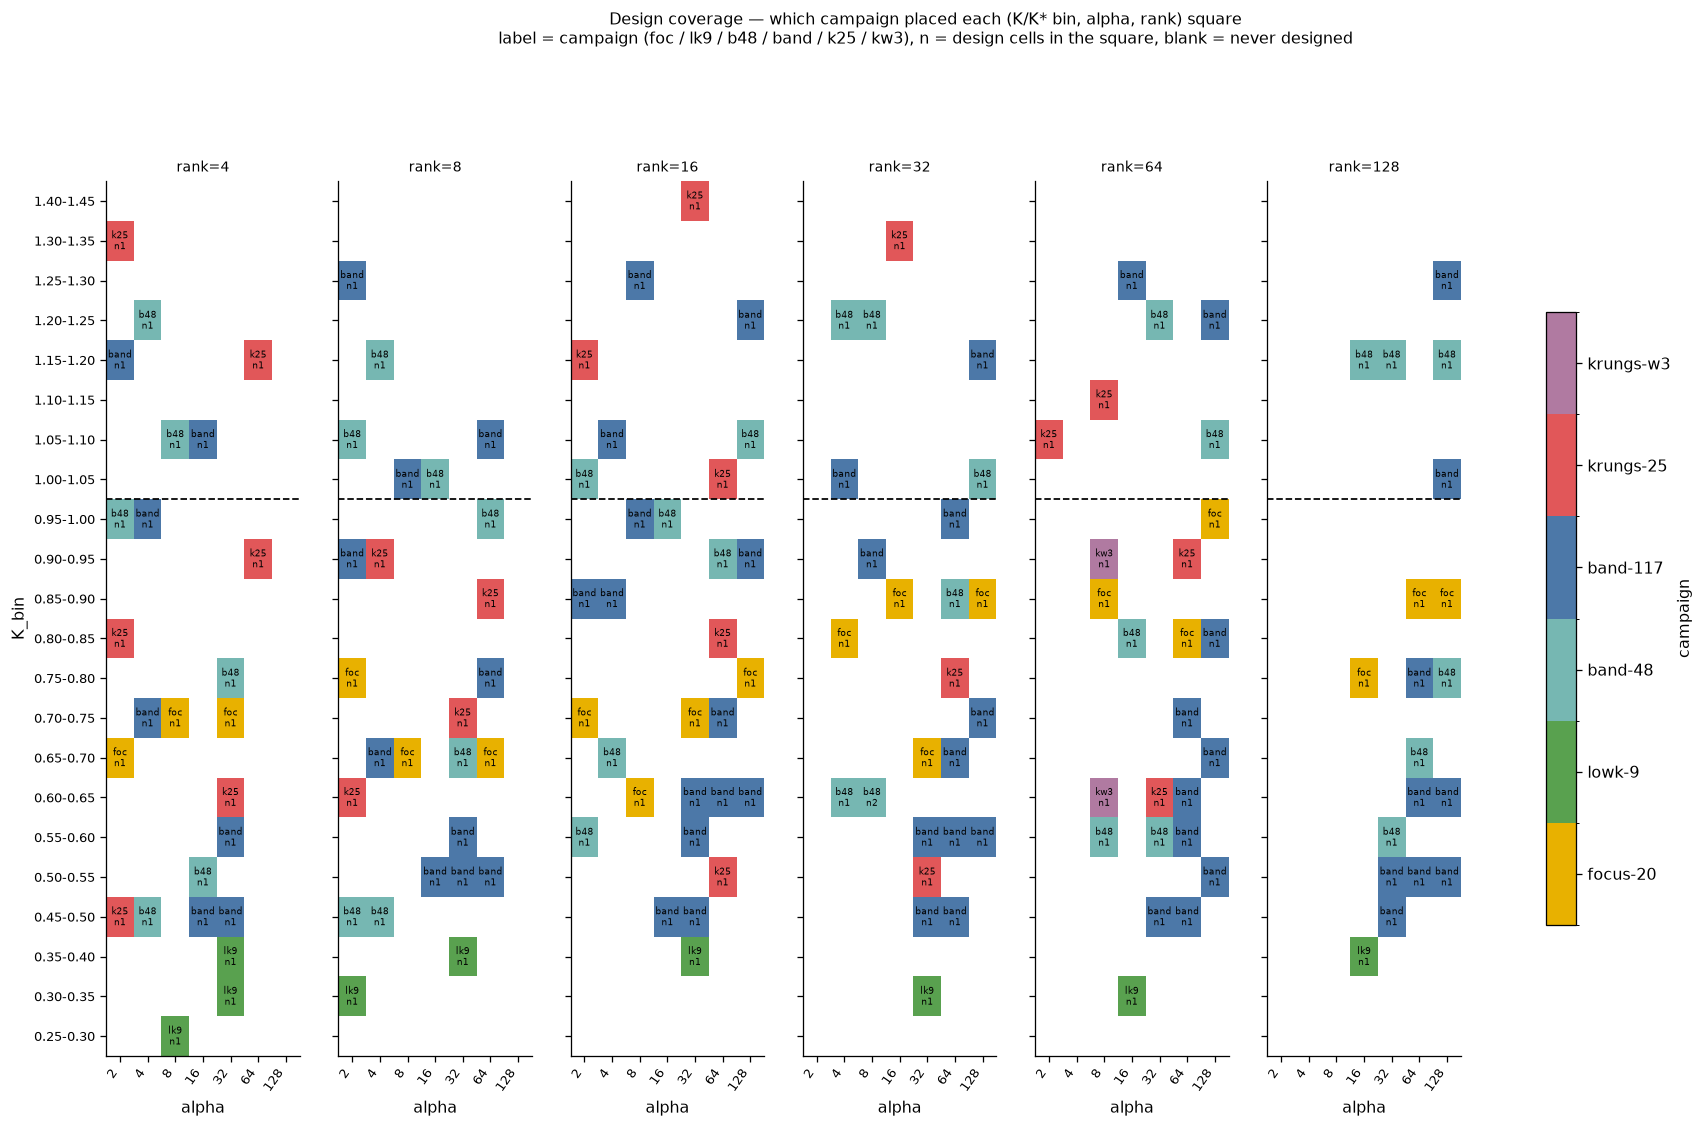

In [4]:
from matplotlib.colors import BoundaryNorm, ListedColormap

# Codes follow DISPLAY_PRIORITY, so the square-level `min` below resolves a mixed square the
# same way the cell-level label does: focus-20 first, then lowk-9/band-48, then band-117, then
# the krungs waves.
CAMPAIGN_CODE = {c: i for i, c in enumerate(DISPLAY_PRIORITY)}
CAMPAIGN_COLOR = {"focus-20": "#e8b100", "lowk-9": "#59a14f", "band-48": "#76b7b2",
                  "band-117": "#4c78a8", "krungs-25": "#e15759", "krungs-w3": "#b07aa1"}
CAMPAIGN_CMAP = ListedColormap([CAMPAIGN_COLOR[c] for c in DISPLAY_PRIORITY])
dmap = design.assign(code=design.campaign.map(CAMPAIGN_CODE))
fig = aplots.facet_grid_heatmaps(
    dmap, row="K_bin", col="alpha", val="code", col_facet="rank", agg="min", show_n=True,
    orders=ORDERS, cmap=CAMPAIGN_CMAP,
    norm=BoundaryNorm(np.arange(-0.5, len(DISPLAY_PRIORITY) + 0.5), len(DISPLAY_PRIORITY)),
    cell_fontsize=5.5, fmt=lambda v: CAMPAIGN_SHORT[DISPLAY_PRIORITY[int(v)]],
    text_color="black", panel_w=3.0, row_h=0.34,
    title=("Design coverage — which campaign placed each (K/K* bin, alpha, rank) square\n"
           "label = campaign (foc / lk9 / b48 / band / k25 / kw3), n = design cells in the square, "
           "blank = never designed"),
    cbar_label="campaign")
for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
    if i % len(RANK_ORDER):
        ax.set_yticklabels([])
    ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.1)
fig.axes[-1].set_yticks(list(CAMPAIGN_CODE.values()))
fig.axes[-1].set_yticklabels(DISPLAY_PRIORITY)
plt.show()

## 2. Loading the results

Every campaign job writes into the same student tree, so the load is one sweep over
`students/{animal}/pythia-160m-{base}/teacher-pythia-160m/{teacher}_tseed1/{dataset}/{cell}`
through the shared campaign loader (`collapse_law.load_law_runs`, which reads each cell's
across-seed `preference_summary.json`).

Three restrictions make the frame *campaign data* rather than *everything that happens to sit at
these coordinates*:

1. **teachers** — only the 20 manifest tags (other teachers have runs at some of these cells from
   the `law-*` grids, which are a different experiment);
2. **cells** — only the design cells above;
3. **seed 1** — every campaign job is student seed 1; extra seeds at the same coordinates come
   from the reseed/law campaigns and would silently re-weight the teacher means. The count of
   dropped extra-seed runs is printed so the exclusion is visible.

Each run is also joined to its student base's **measured test-set prior** on the target animal
(`transfer_factors.load_priors`, `test_prior`: the base model's own mean exact $p(	ext{target})$
on the same 50 held-out test prompts the student score uses). That gives two prior-referenced
columns used by the summary in §3:

- `ratio` $= 	ext{test} / 	ext{test\_prior}$ — the prior-normalized transfer readout, the only
  one comparable **across animals and bases** (raw $p$ mixes trait strength with the base's prior);
- `dead_prior` — the settled prior-based collapse label, `test < test_prior / e^3` (the
  calibrated-margin rule; the legacy fixed cut `DEAD` is kept for the per-lineage sections and
  re-examined in §5).

Arms with no measured `test_prior` are printed; they keep their raw scores but drop out of any
prior-referenced display.

In [5]:
arms = [(a.name, b.name) for a in sorted((OUTPUT_ROOT / "students").iterdir()) if a.is_dir()
        for b in sorted(a.iterdir()) if (b / f"teacher-{TEACHER_BASE}").is_dir()]

frames = []
for animal, base in arms:
    _, r = cl.load_law_runs(
        OUTPUT_ROOT, animal=animal, numbers_base=TEACHER_BASE, dataset=DATASET,
        lineages=[(t, t, base) for t in TOP20],
    )
    if not r.empty:
        frames.append(r.assign(animal=animal, student_base=base))

raw = pd.concat(frames, ignore_index=True).rename(columns={"family": "teacher"})
raw = raw[raw.student_tag.isin(CELL_CAMPAIGN)]
n_extra_seed = int((raw.seed != STUDENT_SEED).sum())
runs = raw[raw.seed.eq(STUDENT_SEED)].copy()

runs["campaign"] = runs.student_tag.map(CELL_CAMPAIGN)
runs["tier3"] = np.select([runs.teacher.isin(TOP5), runs.teacher.isin(TOP10)],
                          ["top1-5", "top6-10"], "top11-20")
runs["K"] = runs.student_tag.map(K_of)
runs["K_rel"] = runs.K / KSTAR
runs["K_bin"] = k_bin(runs.K_rel)
runs["dead"] = runs.test.lt(DEAD).astype(int)

# Prior join + the prior-referenced readouts (see the section text above).
from subliminal_learning.analysis import transfer_factors as tf

PRIORS = tf.load_priors(OUTPUT_ROOT)
runs = runs.merge(PRIORS[["animal", "base_label", "test_prior"]],
                  on=["animal", "base_label"], how="left")
runs["ratio"] = runs.test / runs.test_prior
runs["dead_prior"] = (runs.test < runs.test_prior * np.exp(-3.0)).where(
    runs.test_prior.notna()).astype("float")
NO_PRIOR = sorted(set(map(tuple, runs.loc[runs.test_prior.isna(),
                                          ["animal", "base_label"]].values)))

# One label per lineage: the teacher's numbers base -> the student base it was distilled into.
def base_label(b: str) -> str:
    return "same-model" if b == TEACHER_BASE else b.replace(f"{TEACHER_BASE}-", "")

runs["model"] = runs.student_base.map(base_label)
runs["lineage"] = runs.animal + " | " + TEACHER_BASE + " -> " + runs.model
BASE_RANK = {"data-seed1": 0, "weight-seed1": 1, "data-seed2": 2, "weight-seed2": 3,
             "data-seed3": 4, "weight-seed3": 5, "same-model": 6}
ANIMAL_RANK = {"dog": 0, "cat": 1, "lion": 2, "pig": 3, "rabbit": 4}
MODEL_ORDER = [m for m in BASE_RANK if m in set(runs.model)]
ANIMAL_ORDER = sorted(runs.animal.unique(), key=lambda a: ANIMAL_RANK.get(a, 99))
LINEAGES = sorted(runs.lineage.unique(), key=lambda s: (
    ANIMAL_RANK.get(s.split(" | ")[0], 99), BASE_RANK.get(s.split(" -> ")[1], 99)))
runs["lineage"] = pd.Categorical(runs.lineage, categories=LINEAGES, ordered=True)

print(f"{len(runs)} campaign runs (teacher x cell, seed {STUDENT_SEED}) over {len(LINEAGES)} "
      f"lineages | dropped {n_extra_seed} runs at these coordinates from other seeds")
print(f"teachers present: {runs.teacher.nunique()} of {len(TOP20)} | "
      f"cells present: {runs.student_tag.nunique()} of {len(DESIGN_CELLS)}")
print(f"arms with no measured test prior (raw p only, excluded from prior-referenced views): "
      f"{NO_PRIOR}")

18897 campaign runs (teacher x cell, seed 1) over 27 lineages | dropped 794 runs at these coordinates from other seeds
teachers present: 20 of 20 | cells present: 151 of 151
arms with no measured test prior (raw p only, excluded from prior-referenced views): [('dog', 'pythia-160m'), ('rabbit', 'data-seed2'), ('rabbit', 'weight-seed2')]


## 3. Summary — aggregate transfer across animals and models

The cross-cut, before any per-lineage detail. **Row unit everywhere: one campaign run**
(teacher × design cell, student seed 1, ep20); each display names its own slice, aggregation
and selection. The readouts are the prior-referenced ones defined in §2 —
$\log_{10}(\text{test}/\text{test\_prior})$, where $0$ means the student scores exactly its
base's own prior and $+1$ a $10\times$ lift, and the prior-based collapse fraction
($\text{test} < \text{test\_prior}/e^3$) — because raw test $p$ is not comparable across animals
or bases. Arms with no measured test prior are absent from this section (see the §2 print).

The $K/K^\ast$ axis is cut into three fixed regimes, shared by every display here:

- **low** $[0.29, 0.57)$ — below the focus band, where transfer peaks (lowk-9 / krungs territory);
- **band** $[0.57, 1.00)$ — the focus band the current designs concentrate on;
- **above** $[1.00, 1.41]$ — at/over the designed boundary, where the law predicts collapse.

Coverage is **not** balanced across arms (§4 has the full accounting): every square annotates
its `n`, and the campaign / teacher-tier composition differs between squares, so compare
neighbouring squares rather than distant ones. The tier table at the end restricts to the
shared core65 × top-10 slice, the closest thing to a balanced design across animals.

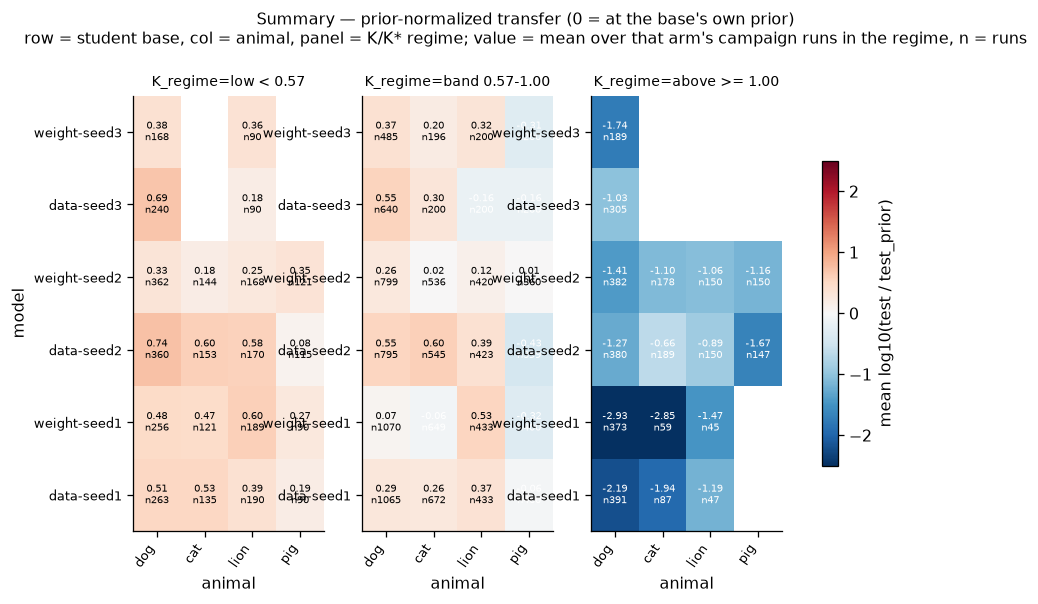

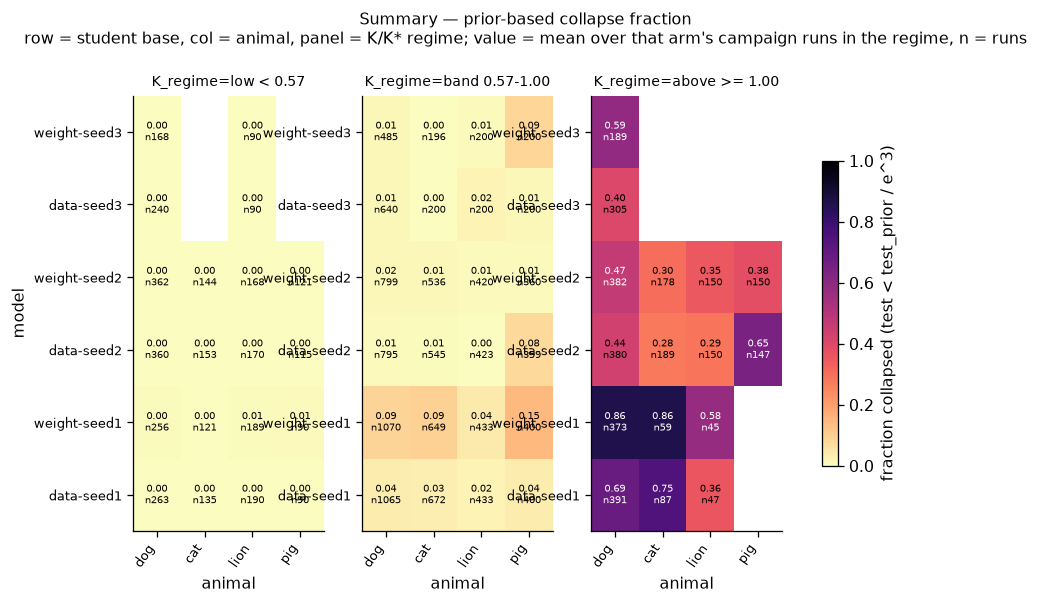

In [6]:
REGIME_EDGES = [0.25, 0.57, 1.00, 1.45]   # lower edge below the 0.29 design floor, so no NaNs
REGIME_LABELS = ["low < 0.57", "band 0.57-1.00", "above >= 1.00"]
runs["K_regime"] = pd.cut(runs.K_rel, REGIME_EDGES, labels=REGIME_LABELS,
                          right=False, include_lowest=True).astype(str)

summ = runs[runs.test_prior.notna()].copy()
# test can be exactly 0 for a fully collapsed run; floor the ratio so its log stays finite.
summ["log_ratio"] = np.log10(np.clip(summ.ratio, 1e-4, None))
SUMM_ORDERS = {"model": [m for m in MODEL_ORDER if m in set(summ.model)],
               "animal": [a for a in ANIMAL_ORDER if a in set(summ.animal)],
               "K_regime": REGIME_LABELS}

for val, kw, what in [
    ("log_ratio", dict(vmin=-2.5, vmax=2.5, mid=0.0, cmap="RdBu_r",
                       cbar_label="mean log10(test / test_prior)"),
     "prior-normalized transfer (0 = at the base's own prior)"),
    ("dead_prior", dict(vmin=0.0, vmax=1.0, cmap="magma_r",
                        cbar_label="fraction collapsed (test < test_prior / e^3)"),
     "prior-based collapse fraction"),
]:
    fig = aplots.facet_grid_heatmaps(
        summ, row="model", col="animal", val=val, col_facet="K_regime", agg="mean",
        orders=SUMM_ORDERS, show_n=True, fmt="{:.2f}", panel_w=2.7, row_h=0.42,
        cell_fontsize=6.0,
        title=(f"Summary — {what}\nrow = student base, col = animal, panel = K/K* regime; "
               "value = mean over that arm's campaign runs in the regime, n = runs"),
        **kw)
    plt.show()

### 3b. Cross-model and cross-tier aggregates

Two condensations of the grids above, both **macro-averaged**: a per-(animal, model) mean is
taken first and those per-arm means are then averaged, so an arm with 3× the runs does not count
3× (per-model views precede any cross-model mean; `arms` counts what went into each entry).

- **ds vs ws** — sub-boundary runs ($K/K^\ast < 1$) only, data-seed vs weight-seed vs same-model
  arms; `ds - ws` is the cross-init asymmetry in decades of prior lift.
- **teacher tier** — restricted to the balanced **core65 × top-10** slice (sub-boundary), where
  the top-5 and top-6–10 tiers ran the same cells, so the tier contrast is not confounded with
  design.

In [7]:
sub = summ[summ.K_rel < 1.0].copy()
sub["family"] = np.select([sub.model.str.startswith("data-seed"),
                           sub.model.str.startswith("weight-seed")],
                          ["data-seed", "weight-seed"], "same-model")
per_arm = (sub.groupby(["animal", "family", "model"], observed=True)
           .agg(log_ratio=("log_ratio", "mean"), dead_prior=("dead_prior", "mean"),
                n=("log_ratio", "size")).reset_index())
fam = (per_arm.groupby(["animal", "family"], observed=True)
       .agg(mean_log_ratio=("log_ratio", "mean"), mean_dead=("dead_prior", "mean"),
            arms=("model", "nunique"), runs=("n", "sum"))
       .reset_index().pivot(index="animal", columns="family"))
fam[("gap", "ds - ws")] = (fam[("mean_log_ratio", "data-seed")]
                           - fam[("mean_log_ratio", "weight-seed")])
print("ds vs ws — K/K* < 1 runs, macro-averaged over that family's arms "
      "(mean_log_ratio in decades of prior lift):")
display(fam.round(3).reindex([a for a in ANIMAL_ORDER if a in fam.index]))

core = sub[sub.student_tag.isin(CORE65) & sub.teacher.isin(TOP10)]
tier = (core.groupby(["animal", "model", "tier3"], observed=True).log_ratio.mean()
        .groupby(["animal", "tier3"], observed=True)
        .agg(mean_log_ratio="mean", arms="size").reset_index()
        .pivot(index="animal", columns="tier3"))
tier[("n_runs", "total")] = core.groupby("animal", observed=True).log_ratio.size()
print("\nteacher tier — core65 cells x top-10 teachers, K/K* < 1, macro-averaged over arms "
      "(the pool's distillability ranking should make top1-5 >= top6-10):")
display(tier.round(3).reindex([a for a in ANIMAL_ORDER if a in tier.index]))

ds vs ws — K/K* < 1 runs, macro-averaged over that family's arms (mean_log_ratio in decades of prior lift):


mean_log_ratio             mean_dead                  arms                  runs                 gap
family      data-seed weight-seed data-seed weight-seed data-seed weight-seed data-seed weight-seed ds - ws
animal                                                                                                     
dog             0.509       0.269     0.016       0.030         3           3      3363        3140   0.239
cat             0.399       0.091     0.011       0.030         3           3      1705        1646   0.309
lion            0.254       0.347     0.010       0.014         3           3      1506        1500  -0.092
pig            -0.160      -0.142     0.034       0.072         3           3      1164        1171  -0.018


teacher tier — core65 cells x top-10 teachers, K/K* < 1, macro-averaged over arms (the pool's distillability ranking should make top1-5 >= top6-10):


mean_log_ratio           arms         n_runs
tier3          top1-5 top6-10 top1-5 top6-10  total
animal                                             
dog             0.456   0.375      6       6   2488
cat             0.219   0.267      6       6   1827
lion            0.279   0.327      6       6   2385
pig            -0.162  -0.180      6       6   1895

## 4. Coverage — what has landed, per lineage and campaign

Row unit: one lineage. Columns: evaluated **teacher × cell pairs** per campaign, against that
campaign's own denominator (its cell count × its teacher pool: 20 × 25 for `krungs-25`,
20 × 4 for `krungs-w3`, 20 × 20 for `focus-20`, 10 × 48 for `band-48`, 10 × 9 for `lowk-9`,
5 × 117 for `band-117`). A run is counted under every design set that contains its cell **and**
whose teacher pool contains its teacher, so the columns double-count where the designs overlap:
`focus-20` and `band-48` with `band-117` (`⊂`), `band-48` with `focus-20` (12 shared cells),
`lowk-9` with `krungs-25` (the 3 anchor rungs). `krungs-w3` was only ever placed on the
`data-seed1` / `weight-seed1` arms, so `0/80` elsewhere is the design, not a gap; likewise the
`b48lowk` queues are still draining on some arms.

The denominators differ per campaign, so a lineage can be complete on one campaign and empty on
another; the figures in §7 show whatever exists and annotate `n` in every square.

In [8]:
def coverage_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for lin, sub in df.groupby("lineage", observed=True):
        rec = {"lineage": lin, "teachers": sub.teacher.nunique(), "cells": sub.student_tag.nunique()}
        for c in CAMPAIGNS:
            cells, pool = CAMPAIGN_CELLS[c], CAMPAIGN_TEACHERS[c]
            denom = len(cells) * len(pool)
            got = int((sub.student_tag.isin(cells) & sub.teacher.isin(pool)).sum())
            rec[c] = f"{got}/{denom}" + (" ✓" if got == denom else "")
        rec["runs"] = len(sub)
        rows.append(rec)
    return pd.DataFrame(rows).set_index("lineage").reindex(LINEAGES).dropna(how="all")

COVER = coverage_table(runs)
display(COVER)

,teachers,cells,krungs-25,krungs-w3,focus-20,band-48,lowk-9,band-117,runs
lineage,,,,,,,,,
dog | pythia-160m -> data-seed1,20,140,500/500 ✓,80/80 ✓,400/400 ✓,480/480 ✓,35/90,504/585,1719
dog | pythia-160m -> weight-seed1,20,135,500/500 ✓,80/80 ✓,400/400 ✓,480/480 ✓,34/90,503/585,1699
dog | pythia-160m -> data-seed2,20,148,500/500 ✓,10/80,200/400,480/480 ✓,90/90 ✓,585/585 ✓,1535
dog | pythia-160m -> weight-seed2,20,148,500/500 ✓,10/80,204/400,480/480 ✓,90/90 ✓,585/585 ✓,1543
dog | pythia-160m -> data-seed3,20,142,500/500 ✓,5/80,200/400,300/480,30/90,585/585 ✓,1185
dog | pythia-160m -> weight-seed3,20,142,500/500 ✓,2/80,200/400,169/480,30/90,242/585,842
dog | pythia-160m -> same-model,20,4,20/500,0/80,20/400,0/480,0/90,15/585,80
cat | pythia-160m -> data-seed1,20,117,0/500,10/80,400/400 ✓,277/480,0/90,449/585,894
cat | pythia-160m -> weight-seed1,20,117,0/500,10/80,400/400 ✓,249/480,0/90,384/585,829


## 5. The collapse threshold, re-checked on this pooled data

`DEAD = 0.005` is inherited from the generality/krungs notebooks. It is only usable if it sits in
the empty trough of *this* merged population's score distribution. Row unit: one campaign run.

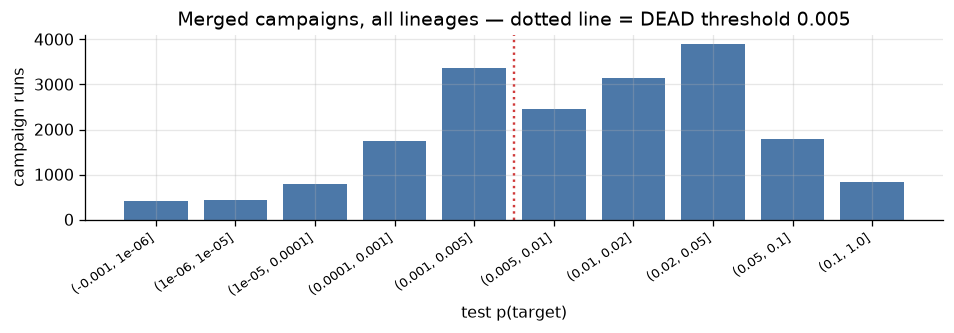

runs in the (1e-3, 5e-3] trough bin: 3368 of 18897 | collapsed at 0.005: 6766 (35.8%)


In [9]:
EDGES_P = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
hist = pd.cut(runs.test, EDGES_P, include_lowest=True).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.4, 3.0))
ax.bar(range(len(hist)), hist.values, color="#4c78a8")
ax.set_xticks(range(len(hist)))
ax.set_xticklabels([str(i) for i in hist.index], rotation=35, ha="right", fontsize=8)
ax.axvline(hist.index.get_loc(pd.cut([DEAD], EDGES_P)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
ax.set(ylabel="campaign runs", xlabel="test p(target)",
       title=f"Merged campaigns, all lineages — dotted line = DEAD threshold {DEAD}")
fig.tight_layout(); plt.show()
print(f"runs in the (1e-3, 5e-3] trough bin: {int(runs.test.between(1e-3, 5e-3).sum())} "
      f"of {len(runs)} | collapsed at {DEAD}: {int(runs.dead.sum())} ({runs.dead.mean():.1%})")

### 5b. Is that one threshold systematic across lineages?

§5 pools every arm, which can only hide an arm-specific trough. This asks the question properly:
fit a 2-component Gaussian mixture to $\log_{10} p$ **within each lineage** and read off where
that arm's dead and live modes actually sit, then measure how much the arm's boundary moves as
the cut is swept.

Scores span $10^{-6}$ to $10^{-0.3}$, so everything here is measured in **decades** — one decade
is one power of ten, i.e. a factor of $10\times$. Saying the cut sits "0.22 decades below the live
mode" means the live mode is only $10^{0.22} \approx 1.7\times$ above it; "0.87 decades" means
$7.4\times$ above. Distances in raw $p$ would be meaningless across arms that differ by orders of
magnitude.

**Row unit:** one lineage, restricted to those with ≥ 100 campaign runs. **Columns:**

- `n` — campaign runs in that arm (teacher × cell, seed 1).
- `dead_mode`, `live_mode` — the centres of the two fitted mixture components, converted back to
  raw $p$: the typical score of a collapsed run and of a surviving one. These are fitted peaks,
  not histogram argmaxes.
- `sep` — decades between the two modes; how cleanly the arm separates at all.
- `dead_frac` — share of the arm's runs below the fixed `DEAD` cut.
- `DEAD_below_live` — $\log_{10}(\text{live\_mode}/\texttt{DEAD})$, the **clearance**: how many
  decades of room the fixed cut has under that arm's live mode. This is the diagnostic column —
  thin clearance means the cut is slicing into surviving runs rather than sitting in the gap.
- `b_0.001` / `b_0.005` / `b_0.01` — the arm's **empirical boundary** under each candidate cut:
  relabel every run dead/alive at that cut, take the collapse fraction in each 0.05-wide
  $K/K^\ast$ bin, and report the midpoint of the first bin reaching 0.5. Units are $K/K^\ast$, so
  1.075 means collapse takes over ~7.5% above the designed boundary. Spread across these three
  columns *is* the threshold's influence on the conclusion.
- `b_live/10` — the same boundary under a **scale-free** cut placed one decade below *that arm's
  own* live mode, instead of a fixed absolute $p$ shared by every arm.

In [10]:
from sklearn.mixture import GaussianMixture

P_FLOOR = 1e-6              # test p is a probability estimate; clamp before logging
CUTS = [0.001, 0.005, 0.01]


def boundary_at(g: pd.DataFrame, cut: float) -> float:
    """First K/K* bin (by bin midpoint) whose collapse fraction under `cut` reaches 0.5."""
    b = (g.assign(d=g.test.lt(cut))
         .groupby(pd.cut(g.K_rel, np.arange(0.25, 1.5, BIN_W)), observed=True).d.mean().dropna())
    hits = [iv.mid for iv, v in b.items() if v >= 0.5]
    return round(float(hits[0]), 3) if hits else np.nan


THR_MIN_RUNS = 100
rows = []
for lin, g in runs.groupby("lineage", observed=True):
    if len(g) < THR_MIN_RUNS:
        continue
    lp = np.log10(np.clip(g.test.values, P_FLOOR, None))
    mus = np.sort(GaussianMixture(2, random_state=0).fit(lp.reshape(-1, 1)).means_.ravel())
    rec = {"lineage": lin, "n": len(g), "dead_mode": 10 ** mus[0], "live_mode": 10 ** mus[1],
           "sep": mus[1] - mus[0], "dead_frac": g.dead.mean(),
           "DEAD_below_live": mus[1] - np.log10(DEAD)}
    for c in CUTS:
        rec[f"b_{c}"] = boundary_at(g, c)
    rec["b_live/10"] = boundary_at(g, 10 ** (mus[1] - 1))
    rows.append(rec)
THR = pd.DataFrame(rows).set_index("lineage")
display(THR.round(4))
for c in [f"b_{c}" for c in CUTS] + ["b_live/10"]:
    v = THR[c].dropna()
    print(f"{c:10s} boundary across lineages: {v.min():.3f}-{v.max():.3f}  (sd {v.std():.3f})")

,n,dead_mode,live_mode,sep,dead_frac,DEAD_below_live,b_0.001,b_0.005,b_0.01,b_live/10
lineage,,,,,,,,,,
dog | pythia-160m -> data-seed1,1719,0.0001,0.0387,2.8421,0.2426,0.8885,1.075,1.075,1.025,1.075
dog | pythia-160m -> weight-seed1,1699,0.0000,0.0195,3.1107,0.3673,0.5920,1.025,0.925,0.875,1.025
dog | pythia-160m -> data-seed2,1535,0.0005,0.0497,2.0102,0.2065,0.9975,1.175,1.075,1.025,1.075
dog | pythia-160m -> weight-seed2,1543,0.0003,0.0316,2.0608,0.1918,0.8002,1.175,1.125,1.075,1.125
dog | pythia-160m -> data-seed3,1185,0.0005,0.0403,1.9155,0.2101,0.9058,1.175,1.075,1.075,1.075
dog | pythia-160m -> weight-seed3,842,0.0001,0.0174,2.2417,0.2553,0.5417,1.075,1.075,0.925,1.075
cat | pythia-160m -> data-seed1,894,0.0001,0.0119,2.3107,0.3043,0.3760,1.025,0.925,0.775,1.025
cat | pythia-160m -> weight-seed1,829,0.0000,0.0112,2.3911,0.3703,0.3489,0.975,0.875,0.775,0.975
cat | pythia-160m -> data-seed2,887,0.0004,0.0240,1.8108,0.1962,0.6816,1.225,1.075,0.925,1.175


b_0.001    boundary across lineages: 0.775-1.225  (sd 0.136)
b_0.005    boundary across lineages: 0.275-1.125  (sd 0.247)
b_0.01     boundary across lineages: 0.275-1.075  (sd 0.269)
b_live/10  boundary across lineages: 0.925-1.175  (sd 0.075)


## 6. Per-teacher first — is a teacher mean the right thing to put in a square?

The figures in §7 average teachers inside each square, which is only honest if the teachers move
*together* along $K$. Row unit here: one teacher; y: its mean test $p$ over the cells in each
$K/K^\ast$ bin; one panel per lineage (the four best-covered ones). Teachers differ a lot in
**level** — that is the distillability ranking the pool was selected on — but if they share the
**boundary**, the mean is a fair summary of where the cliff is and a poor summary of how high the
plateau is.

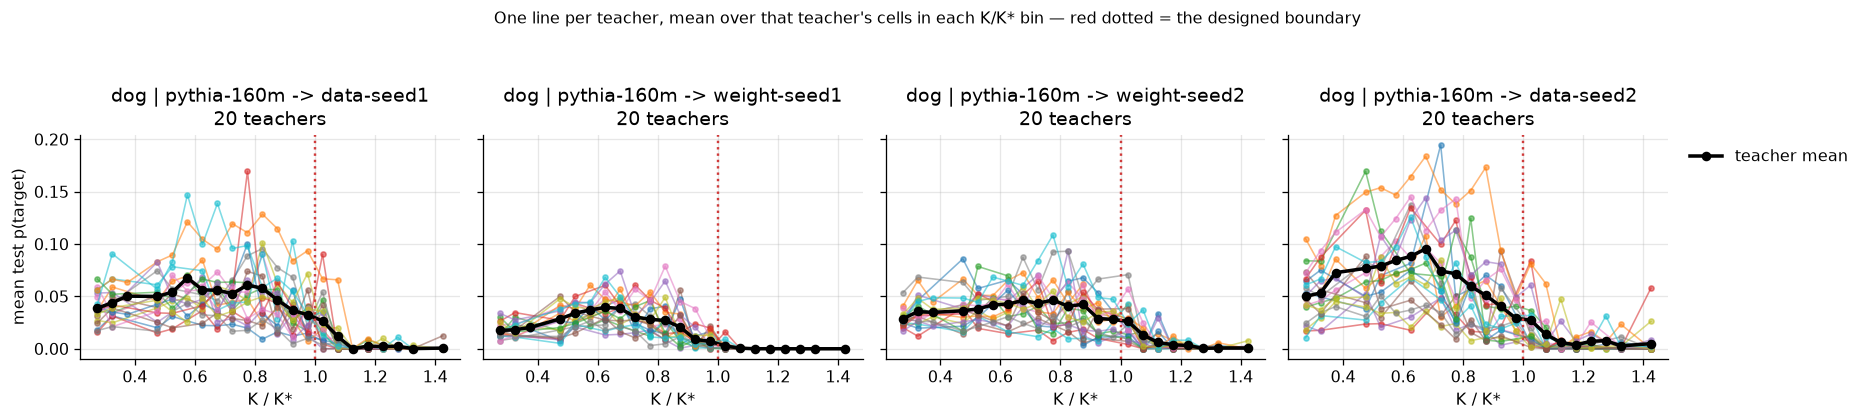

In [11]:
SHOW_LINEAGES = list(COVER.assign(n=[len(runs[runs.lineage.eq(i)]) for i in COVER.index])
                     .sort_values("n", ascending=False).index[:4])
mid = {b: (float(b.split("-")[0]) + float(b.split("-")[1])) / 2 for b in K_ORDER}

fig, axs = plt.subplots(1, len(SHOW_LINEAGES), figsize=(4.1 * len(SHOW_LINEAGES), 3.4),
                        sharey=True, squeeze=False)
for ax, lin in zip(axs[0], SHOW_LINEAGES):
    sub = runs[runs.lineage.eq(lin)]
    for t, g in sub.groupby("teacher", observed=True):
        prof = g.groupby("K_bin").test.mean()
        x = [mid[b] for b in K_ORDER if b in prof.index]
        ax.plot(x, [prof[b] for b in K_ORDER if b in prof.index], "-o", ms=3.2, lw=1.0, alpha=0.55)
    band = sub.groupby("K_bin").test.mean()
    ax.plot([mid[b] for b in K_ORDER if b in band.index],
            [band[b] for b in K_ORDER if b in band.index], "-o", color="k", lw=2.2, ms=5,
            label="teacher mean")
    ax.axvline(1.0, color="#d03b3b", ls=":", lw=1.5)
    ax.set(xlabel="K / K*", xticks=[0.4, 0.6, 0.8, 1.0, 1.2, 1.4],
           title=f"{lin}\n{sub.teacher.nunique()} teachers")
axs[0][0].set_ylabel("mean test p(target)")
axs[0][-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
fig.suptitle("One line per teacher, mean over that teacher's cells in each K/K* bin "
             "— red dotted = the designed boundary", y=1.06, fontsize=10)
fig.tight_layout(); plt.show()

## 7. The campaign grids — one figure per lineage

**Row unit of every square:** the mean over all `teacher × design-cell` runs whose cell falls in
that $(K/K^\ast\ \text{bin}, \alpha, r)$ square, at student seed 1. `n` under each value is how
many such runs went into it — it varies across squares because the campaigns carry different
teacher pools (5, 10 or 20) and different cell densities, so **compare colours within a square's
neighbourhood, not the `n`s**.

Colour: mean test $p(\text{target})$ on the house 0–0.2 scale, shared by every figure so lineages
can be read against each other. Dashed line: the designed boundary $K/K^\ast = 1$. Boxed squares
mark the **core65** design new arms now run, coloured by which part placed the cell: **red** =
`focus-20`, **blue** = `band-48` outside `focus-20`, **orange** = `lowk-9`.

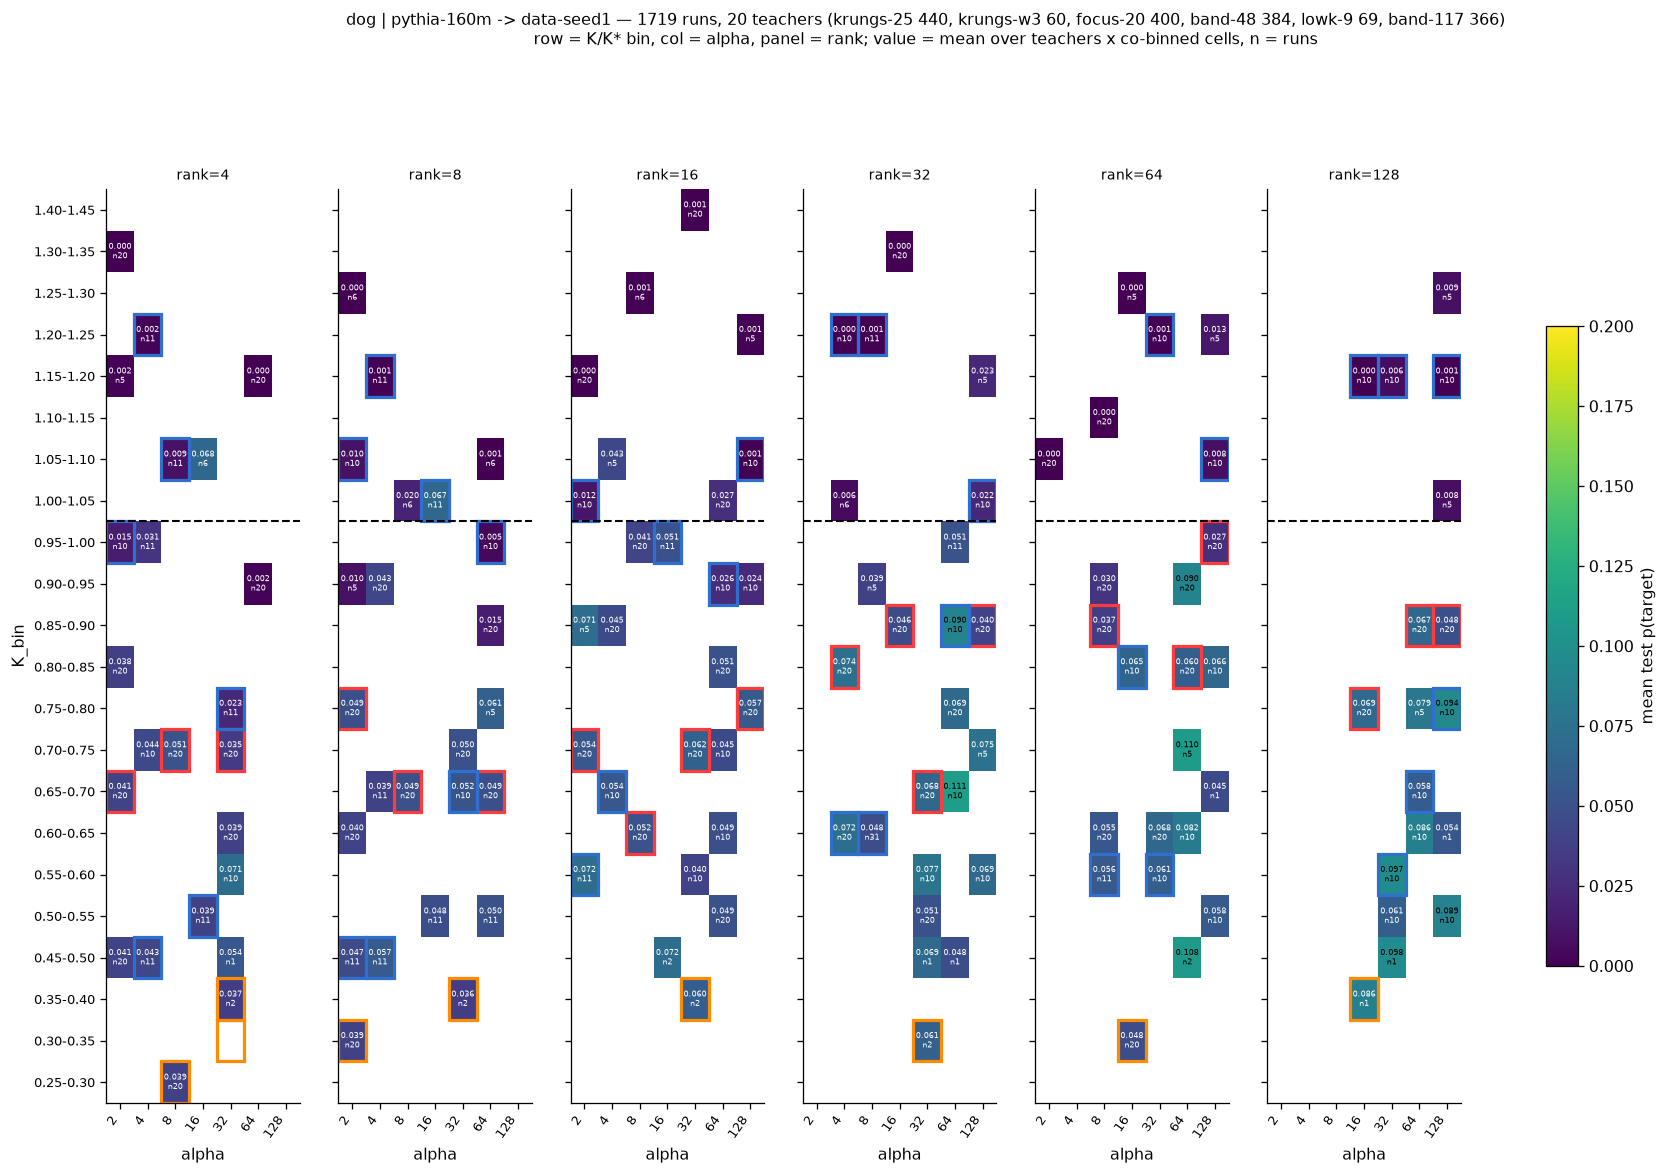

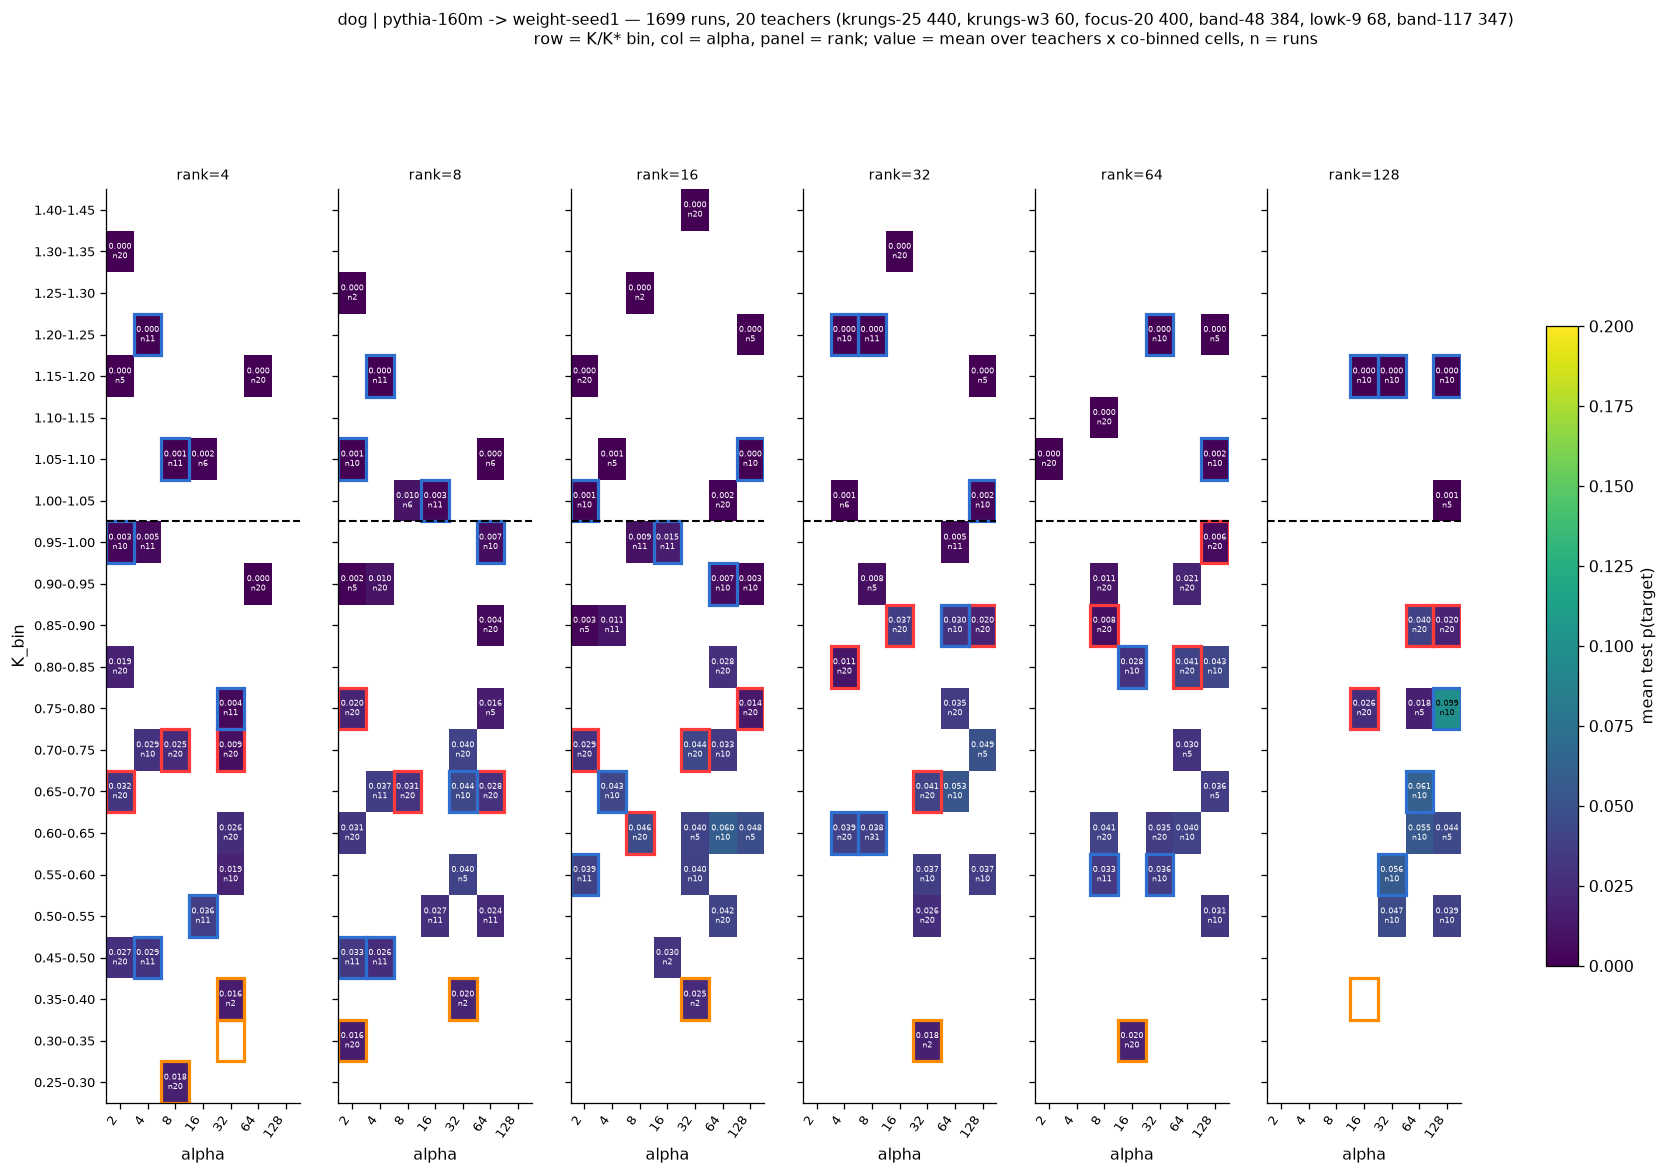

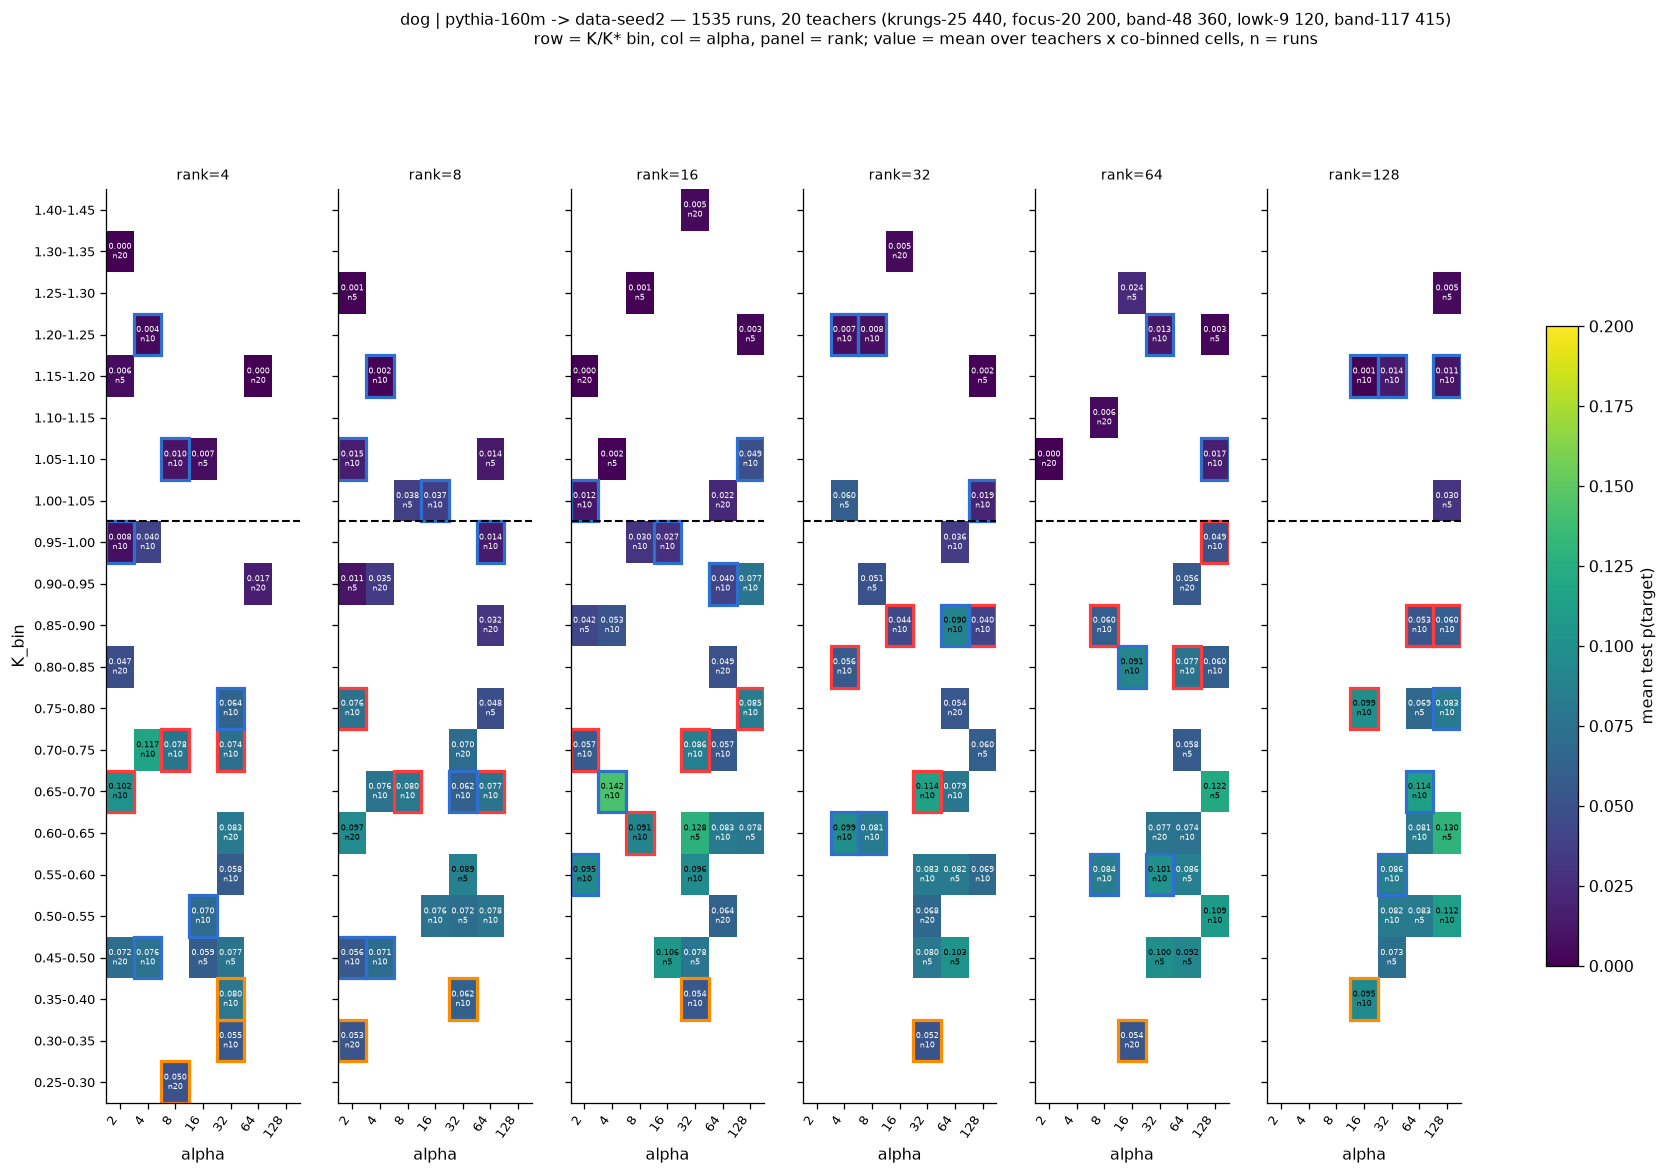

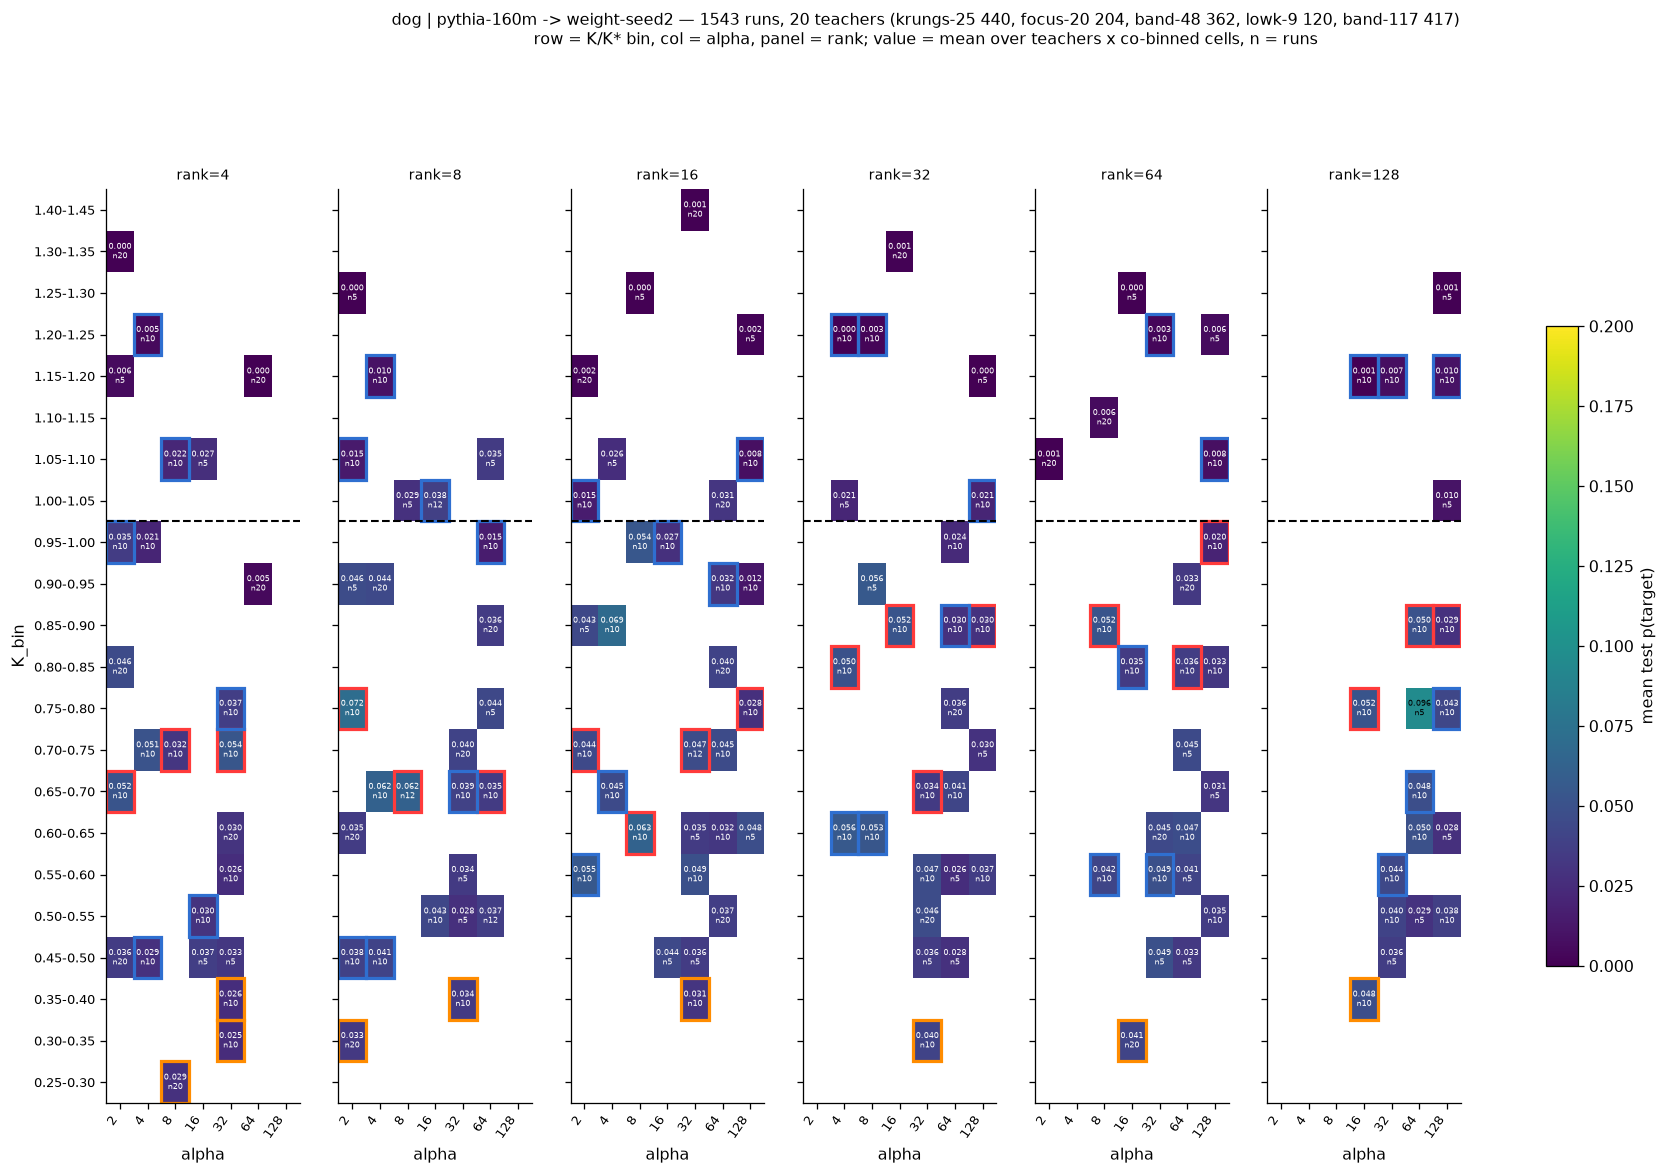

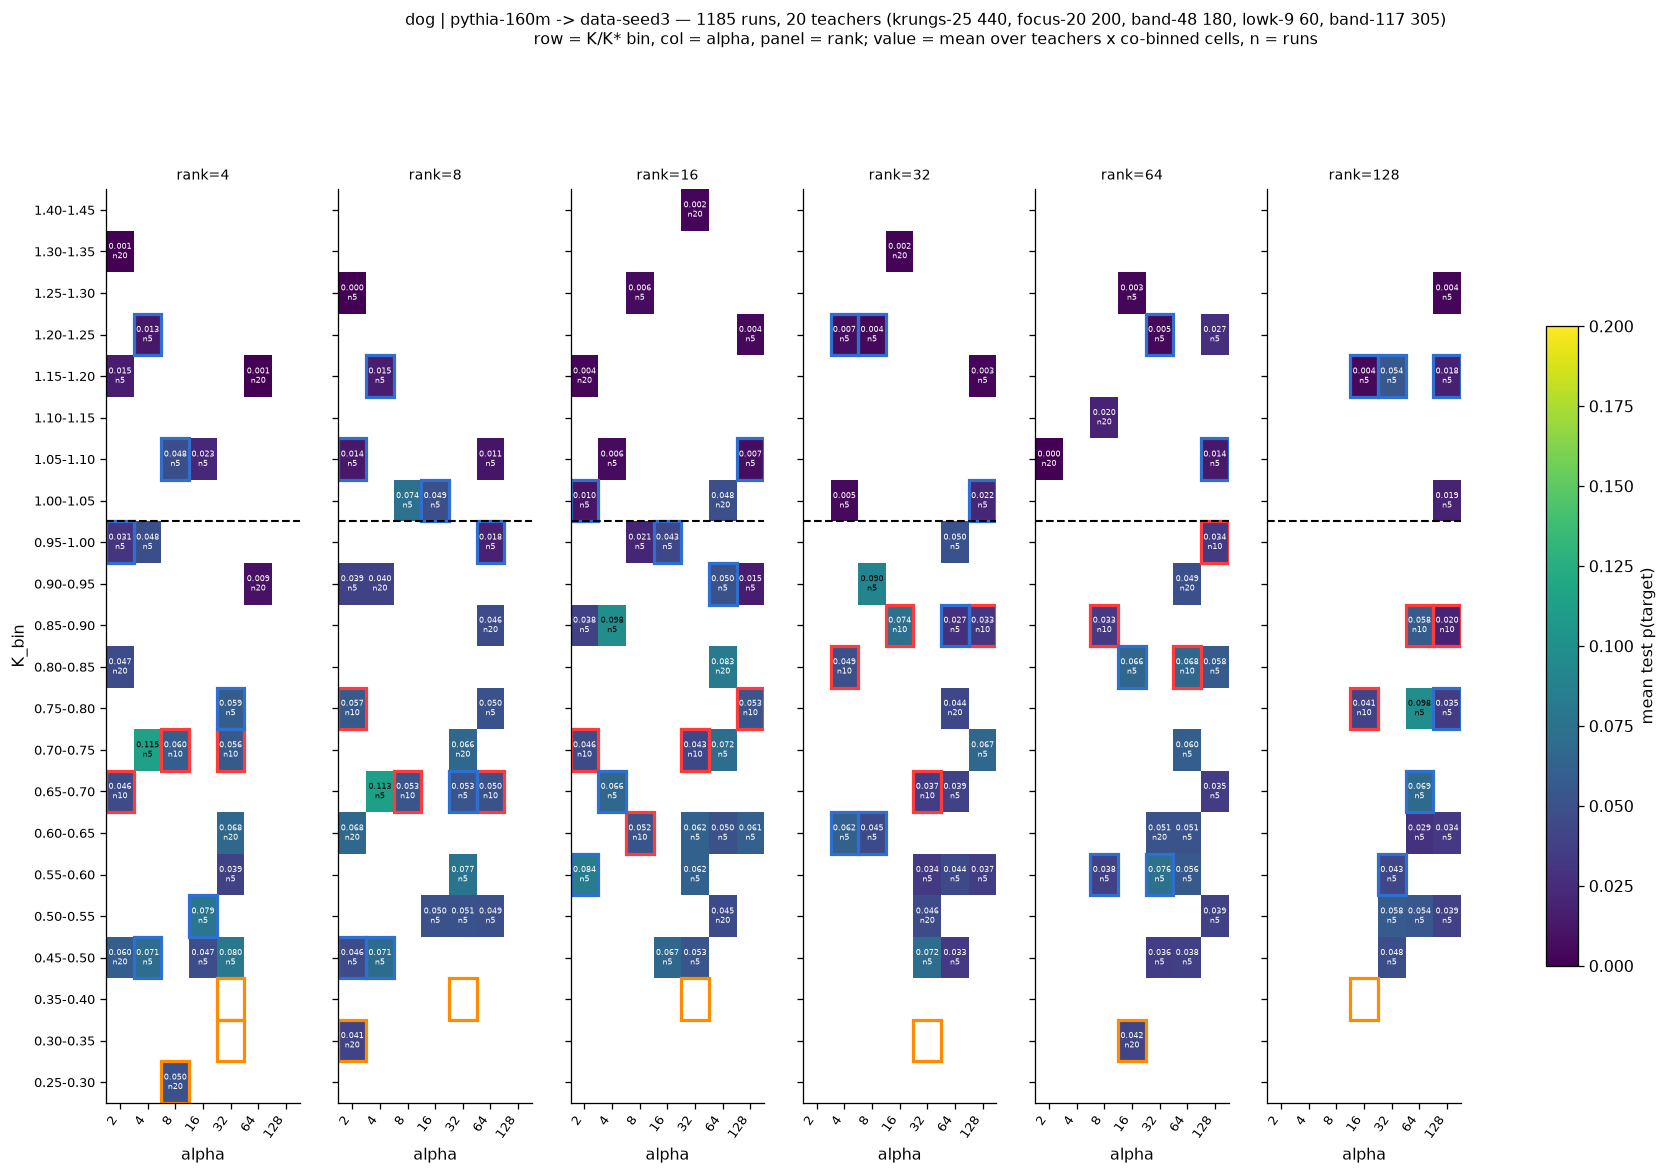

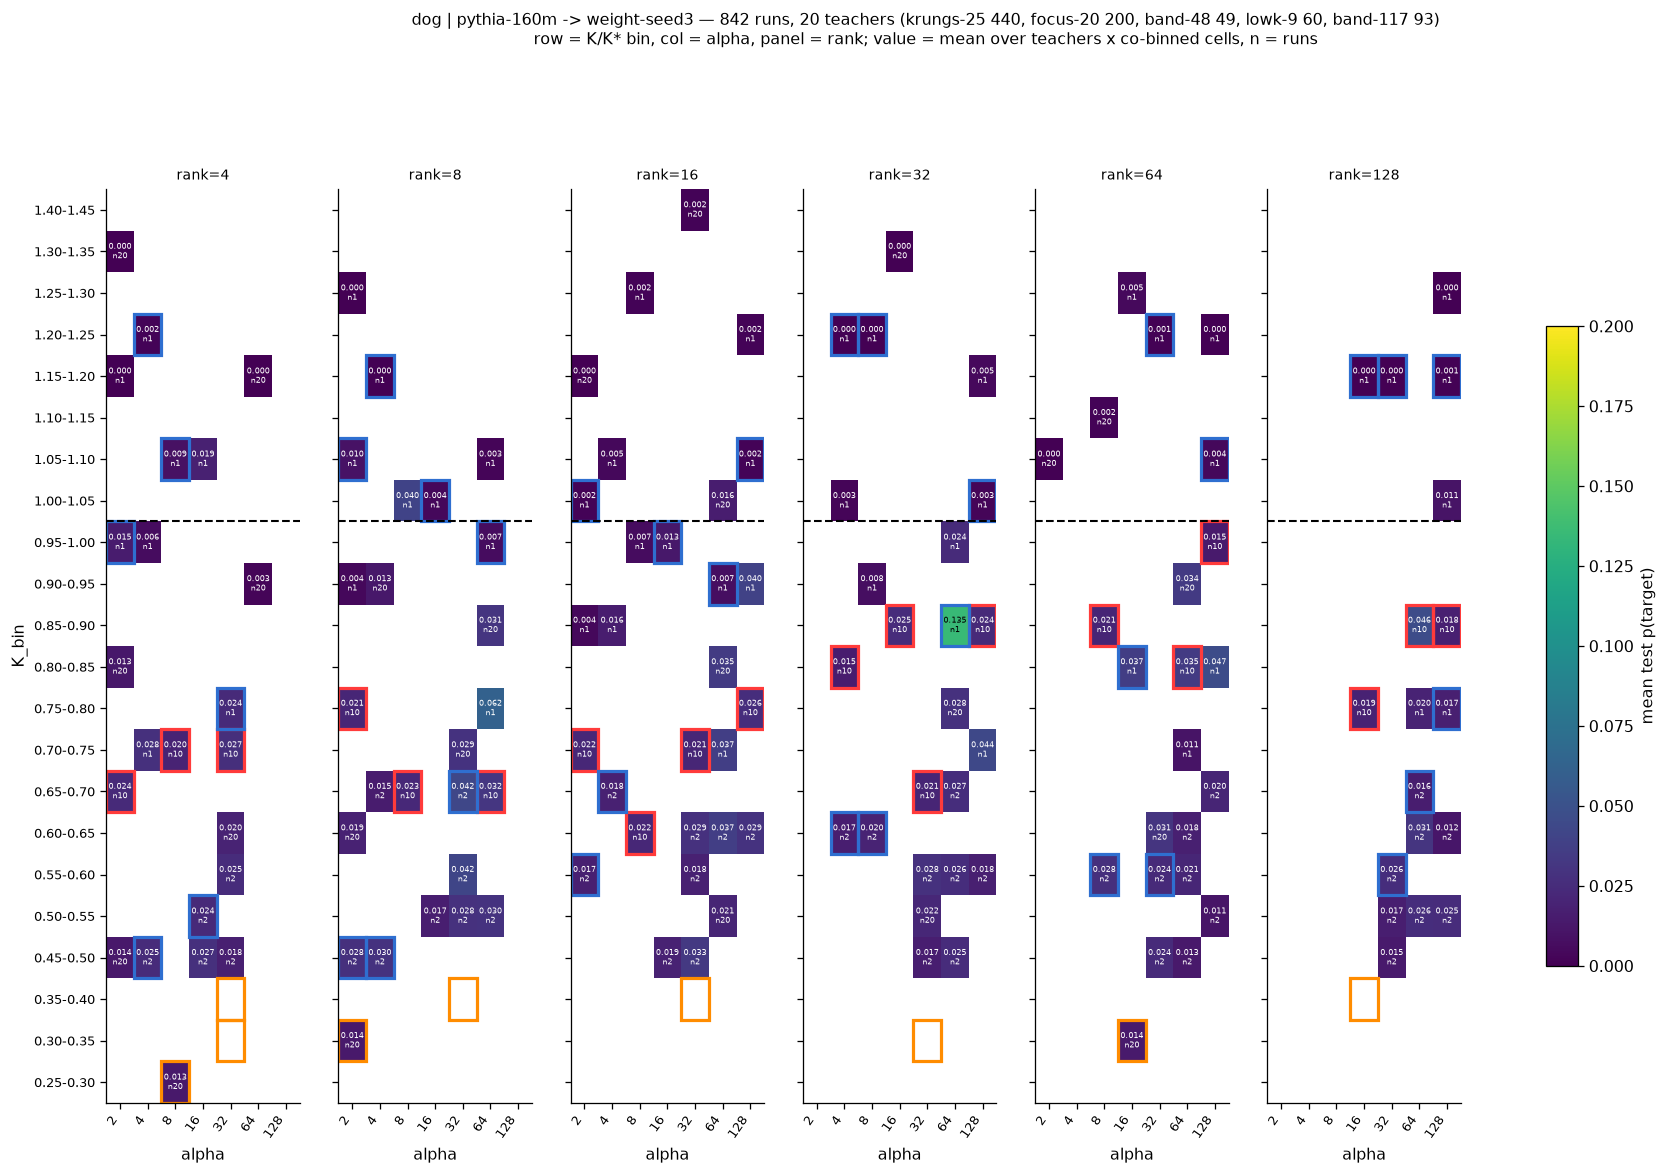

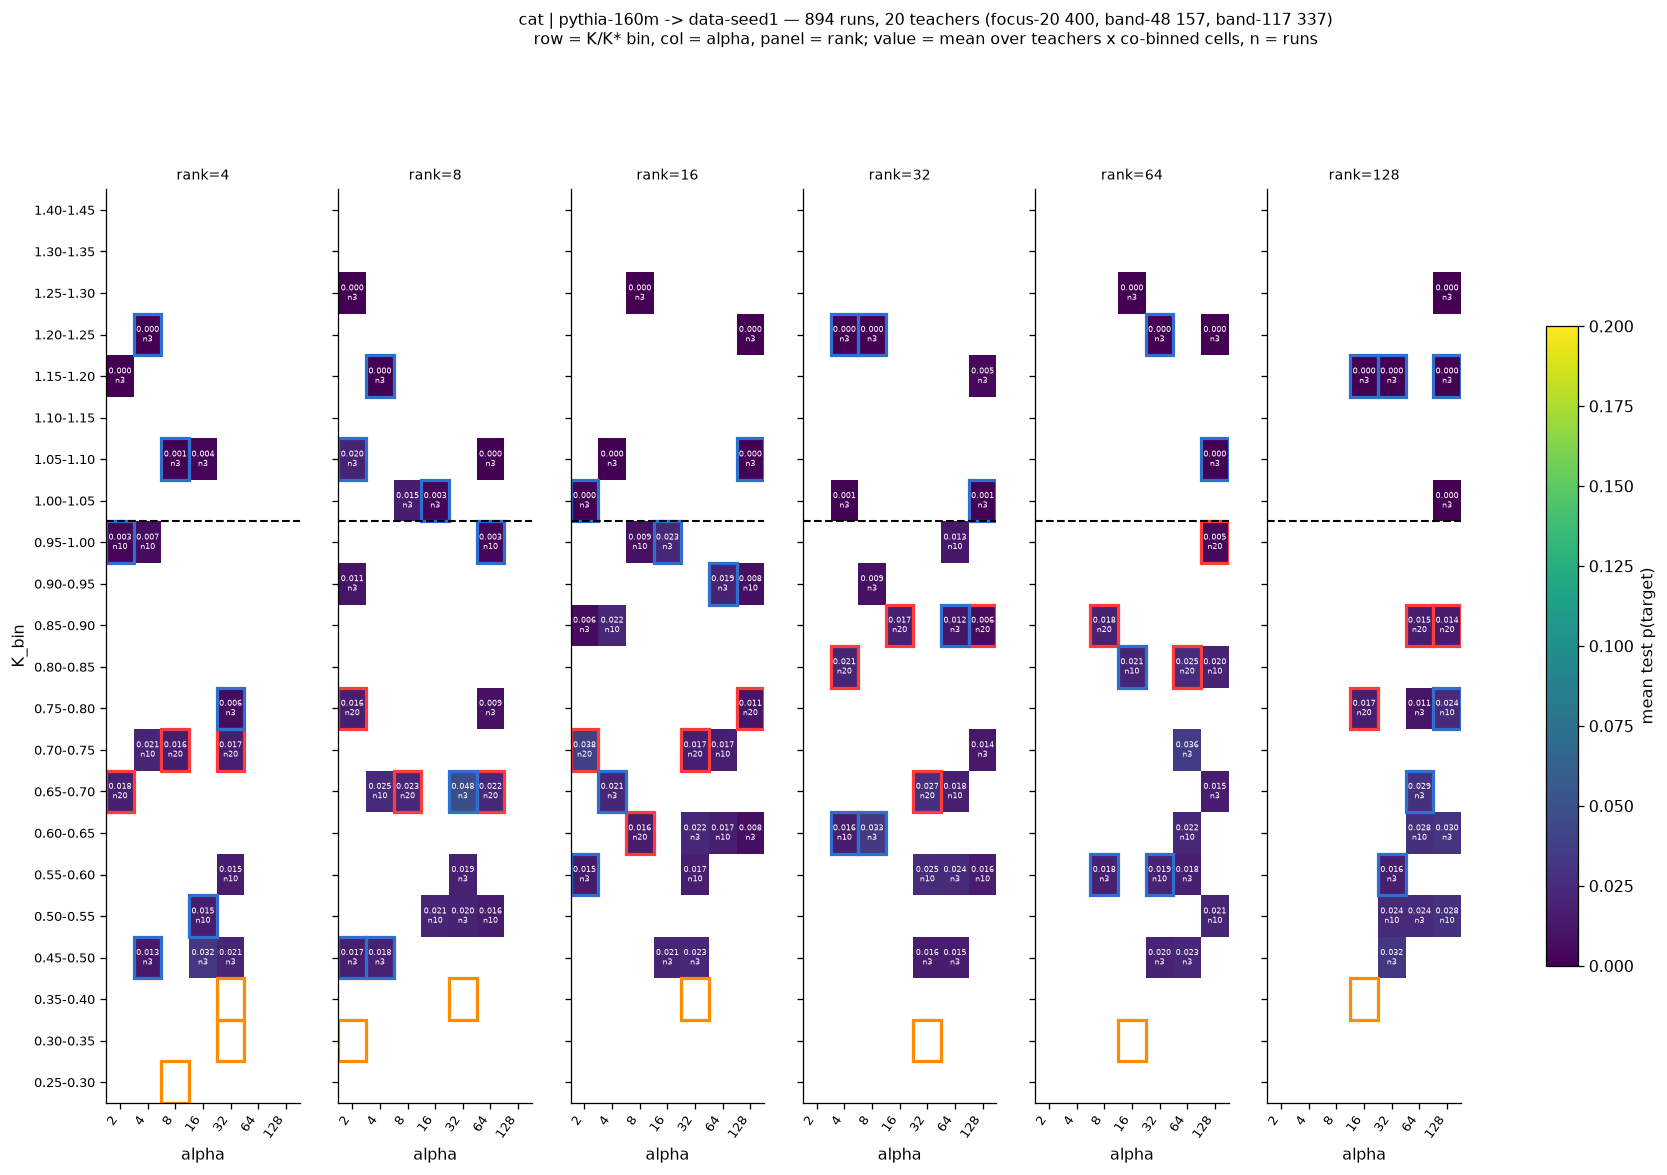

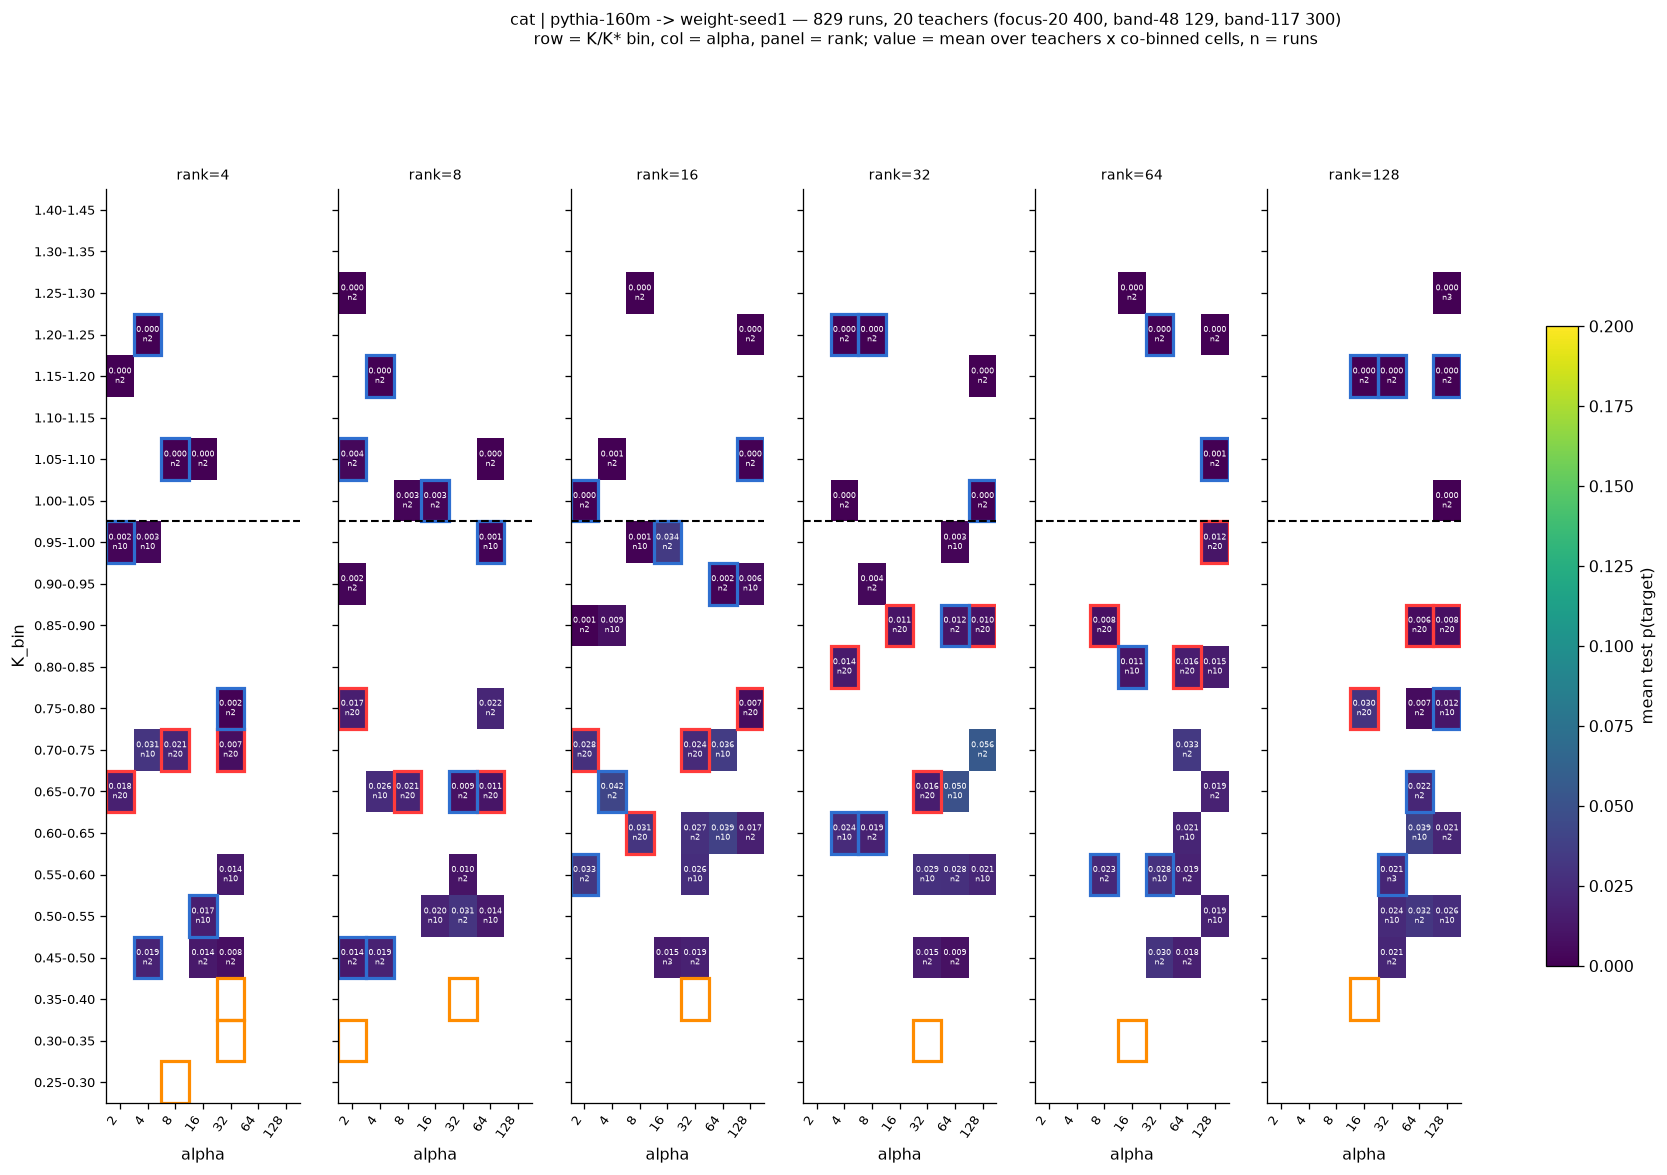

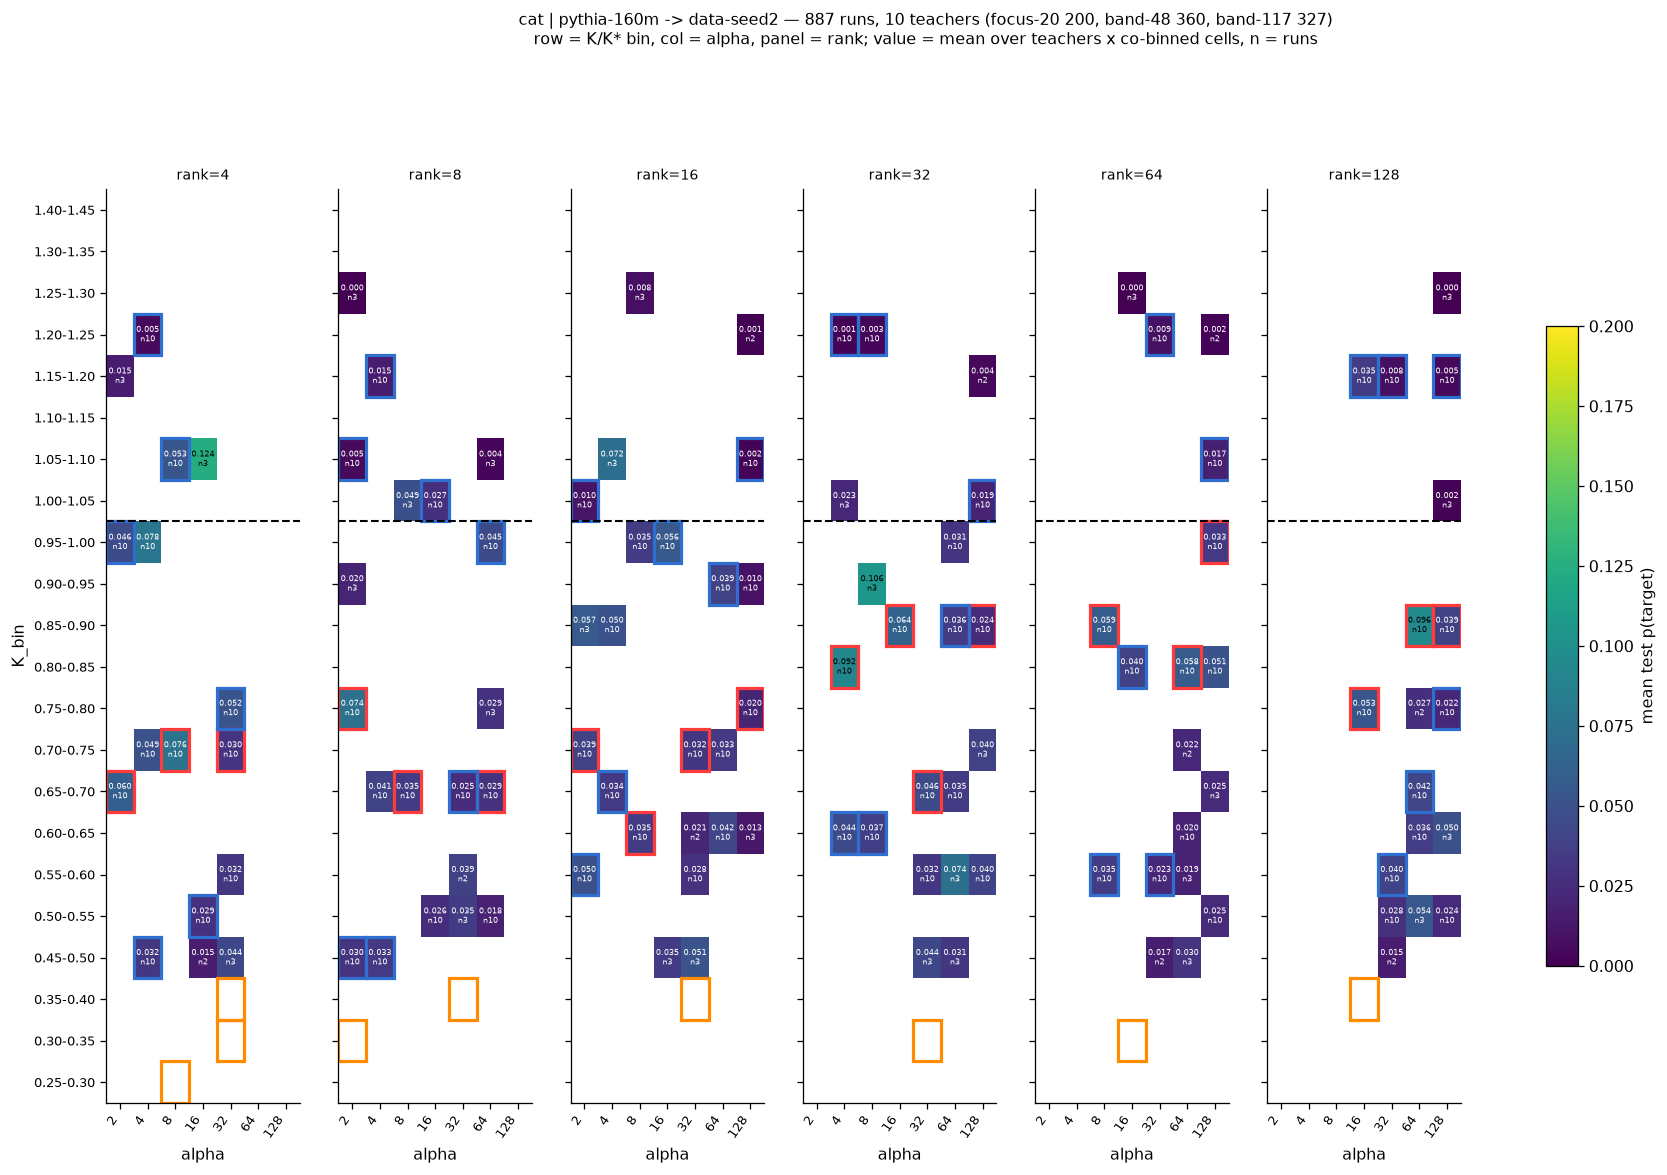

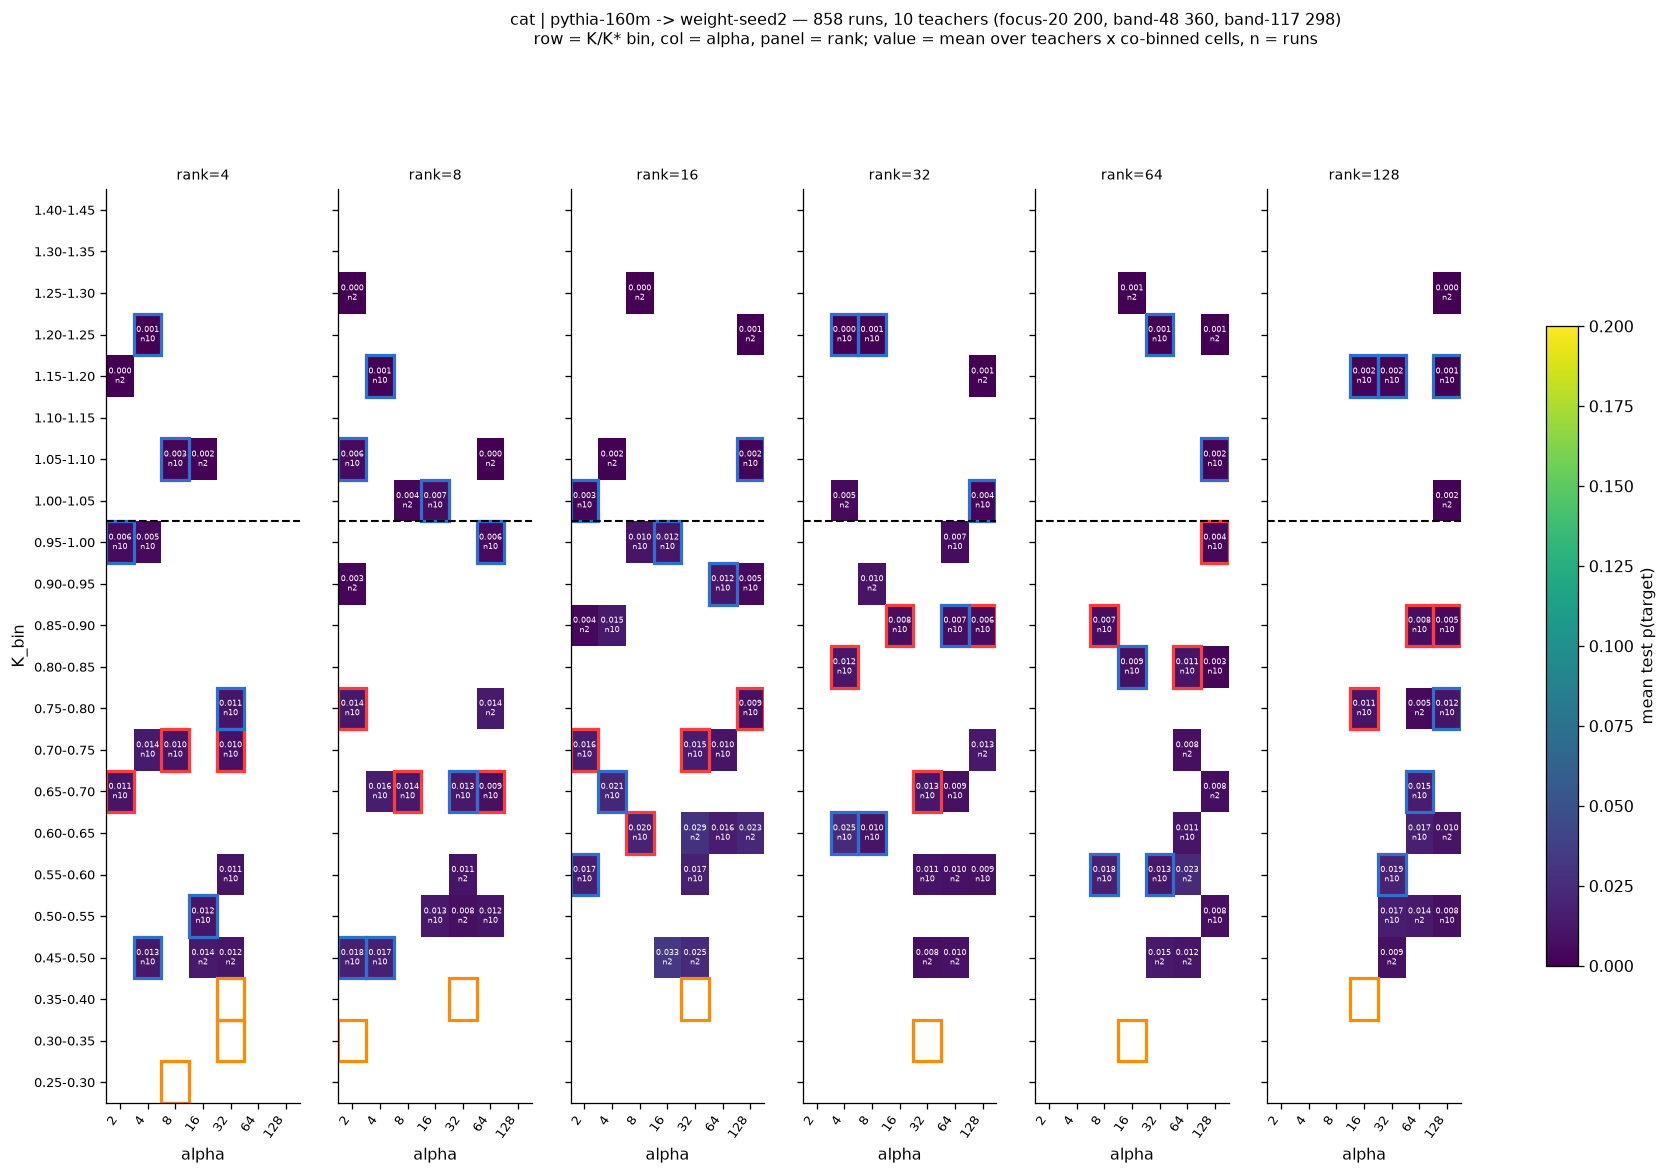

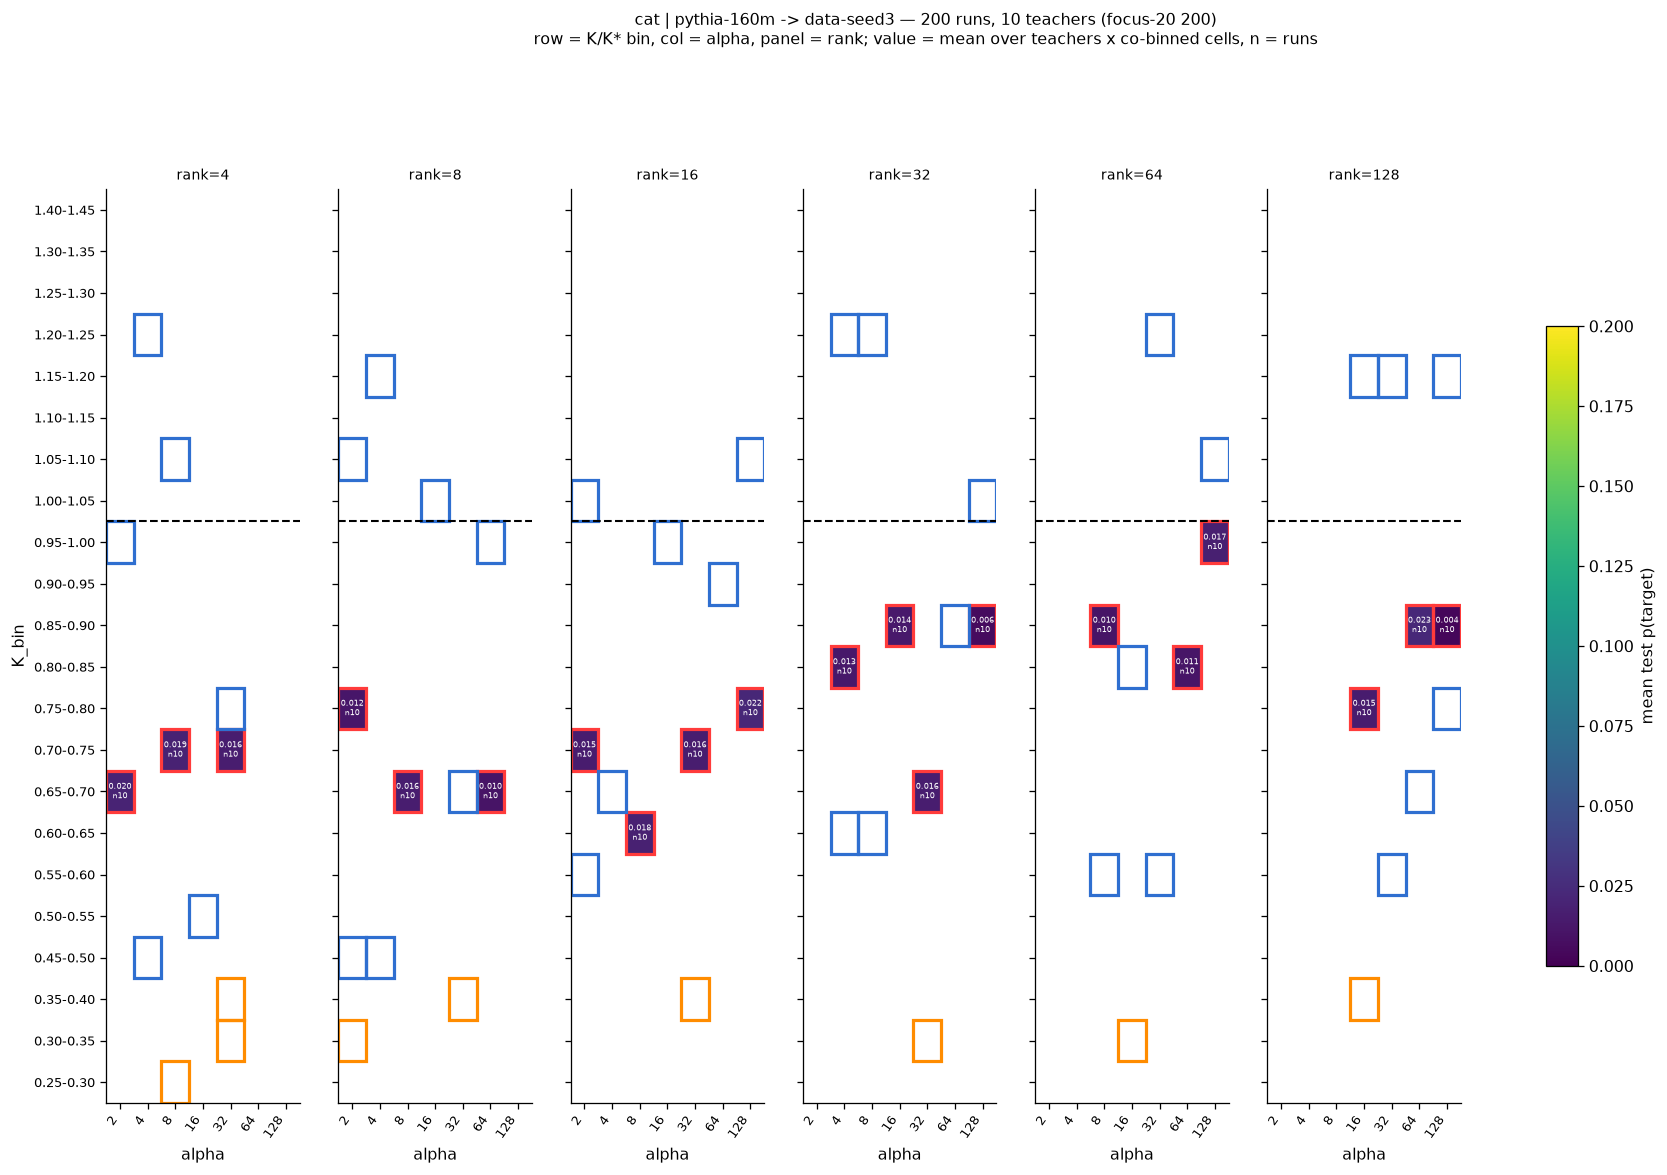

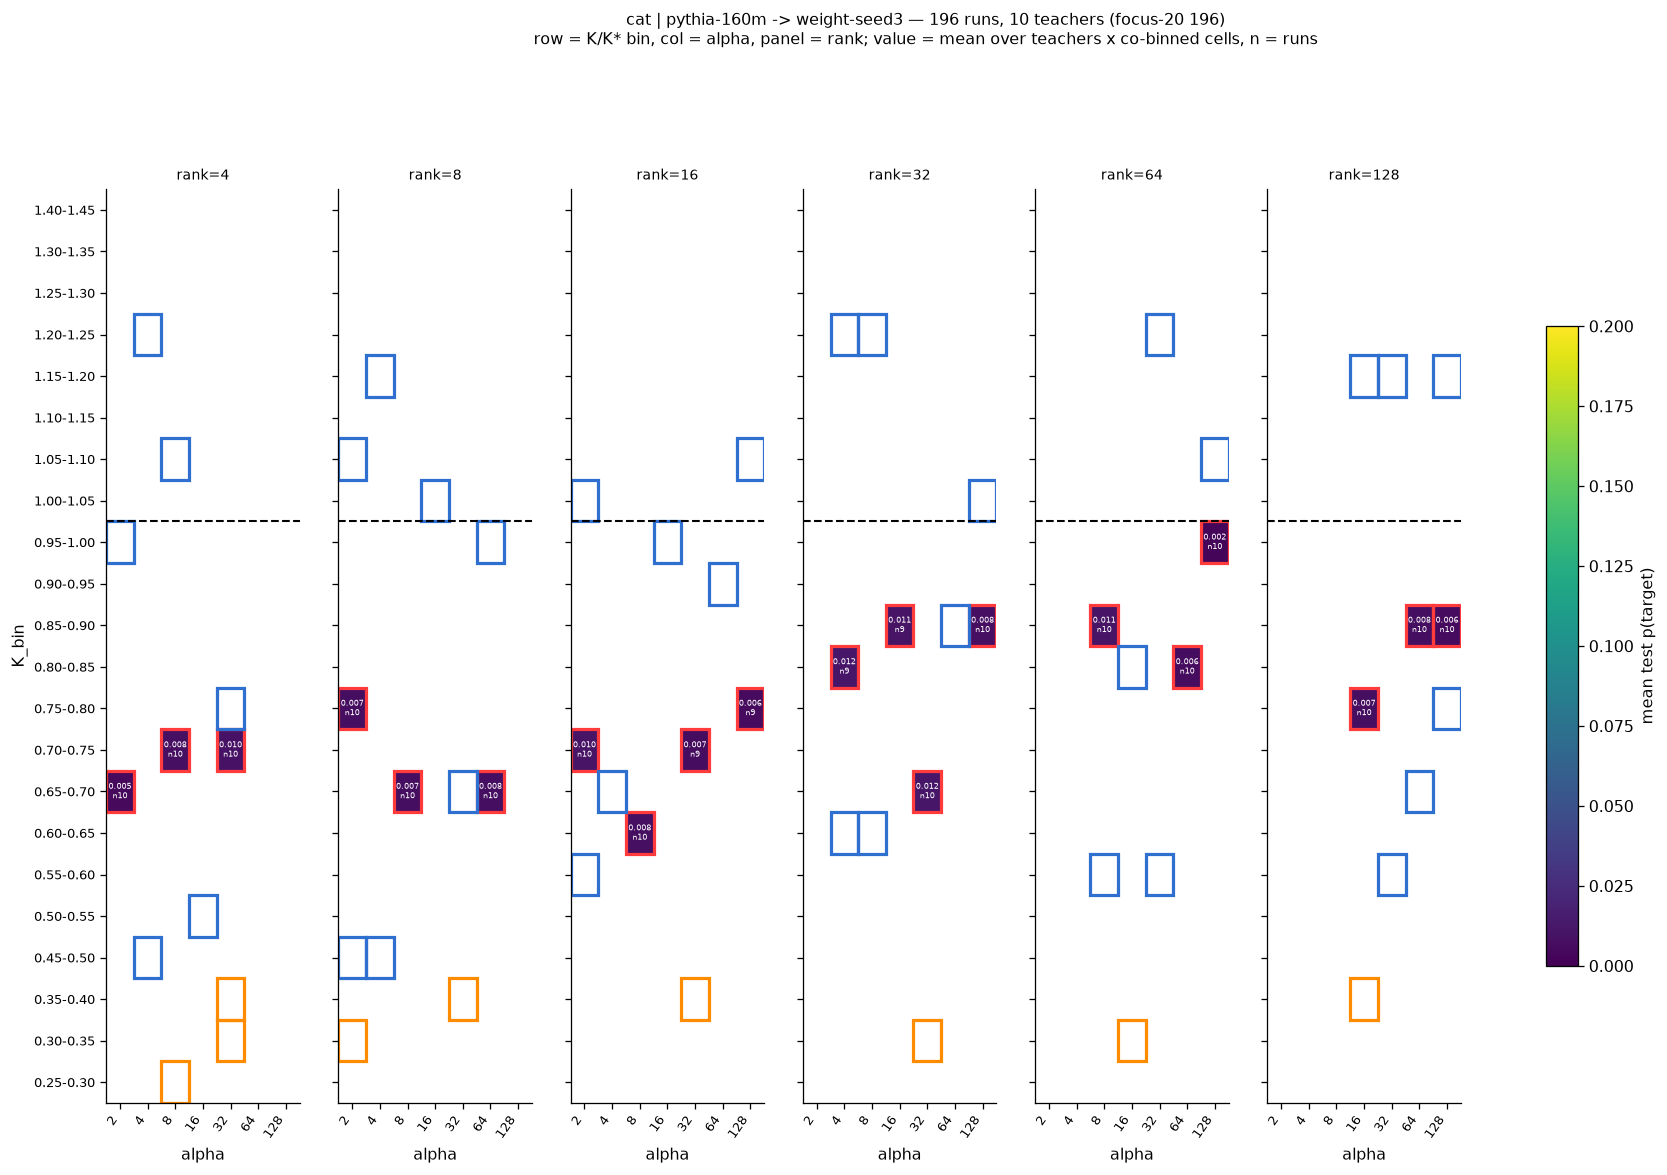

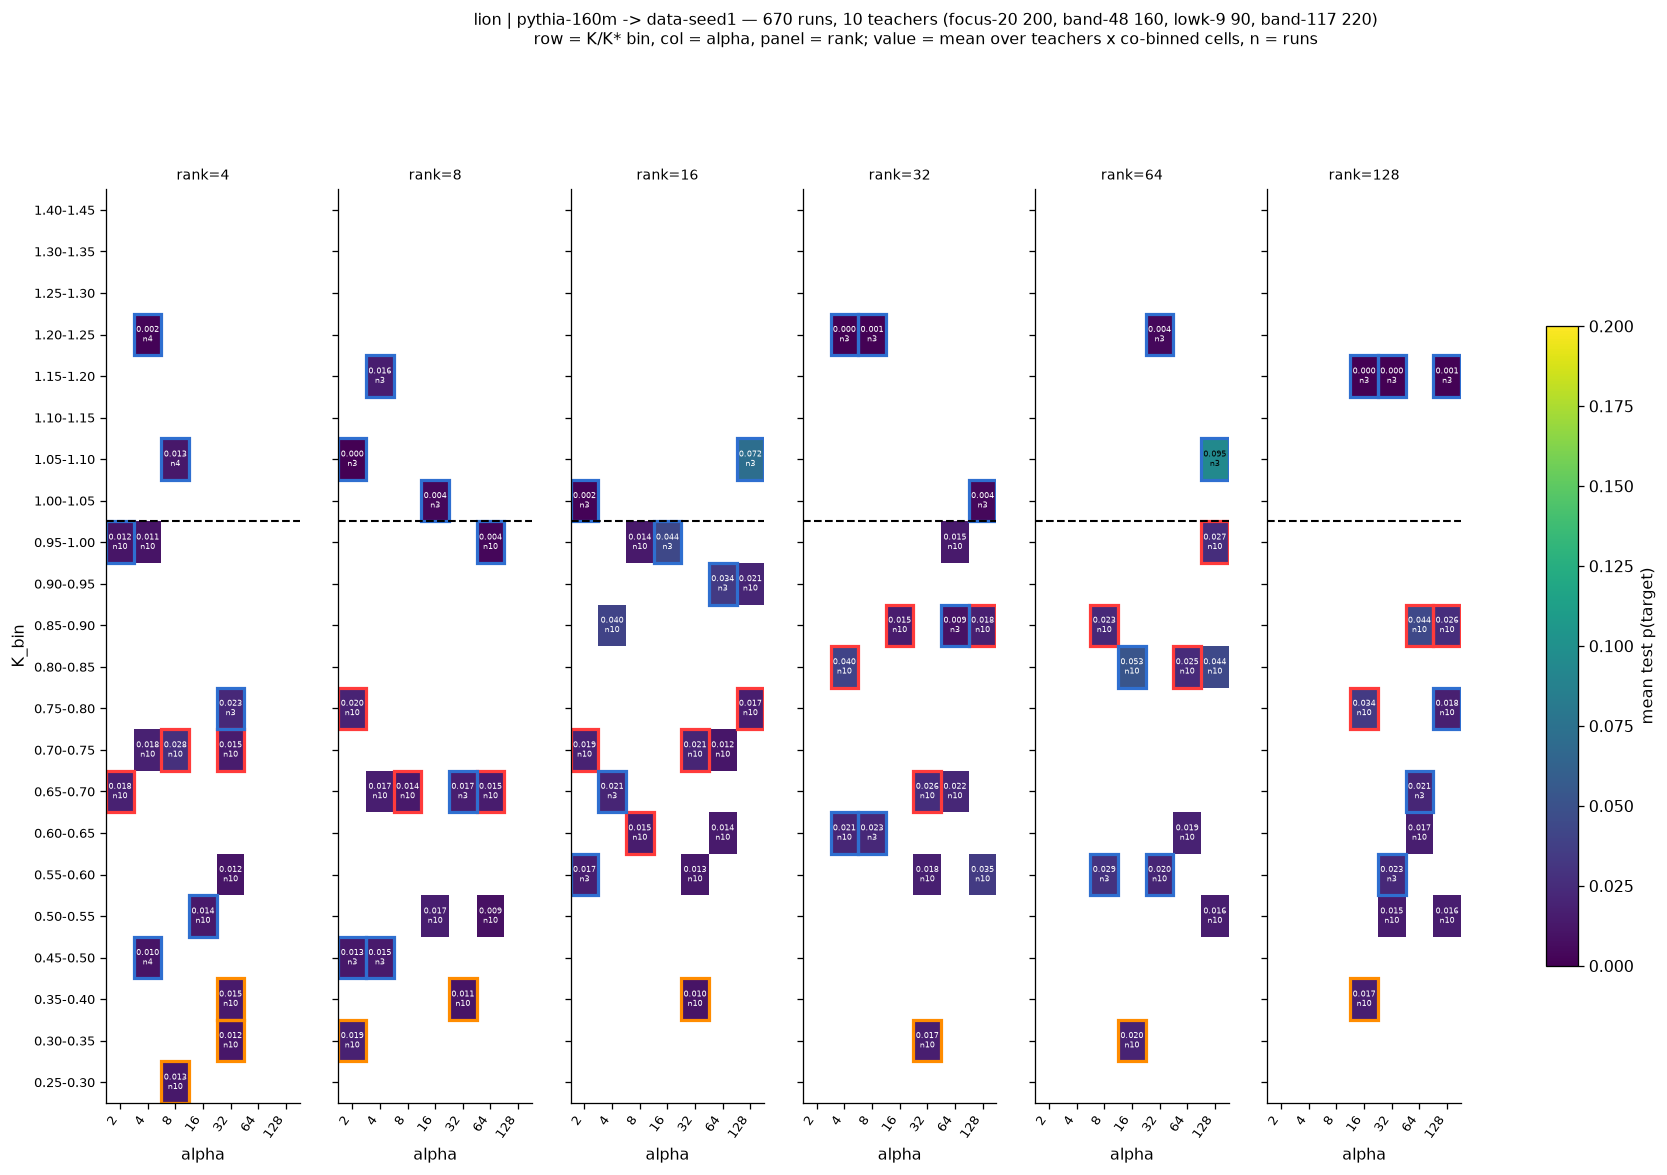

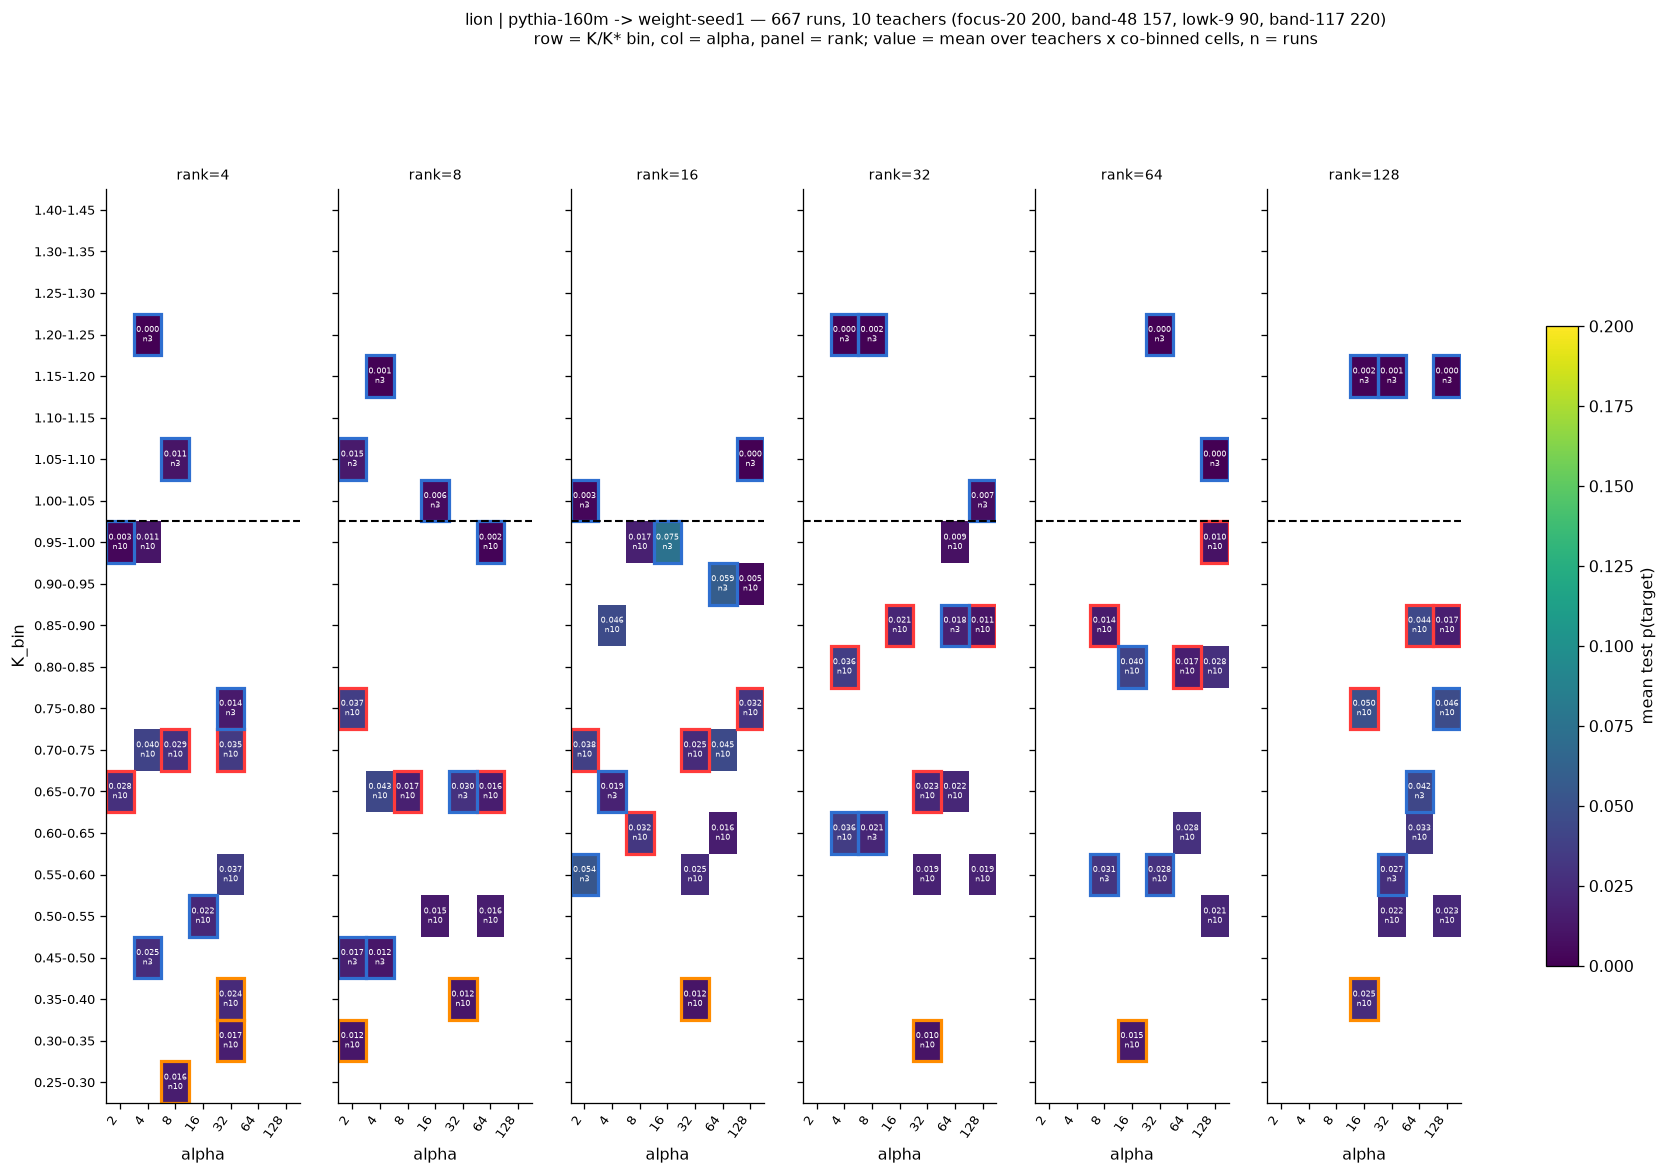

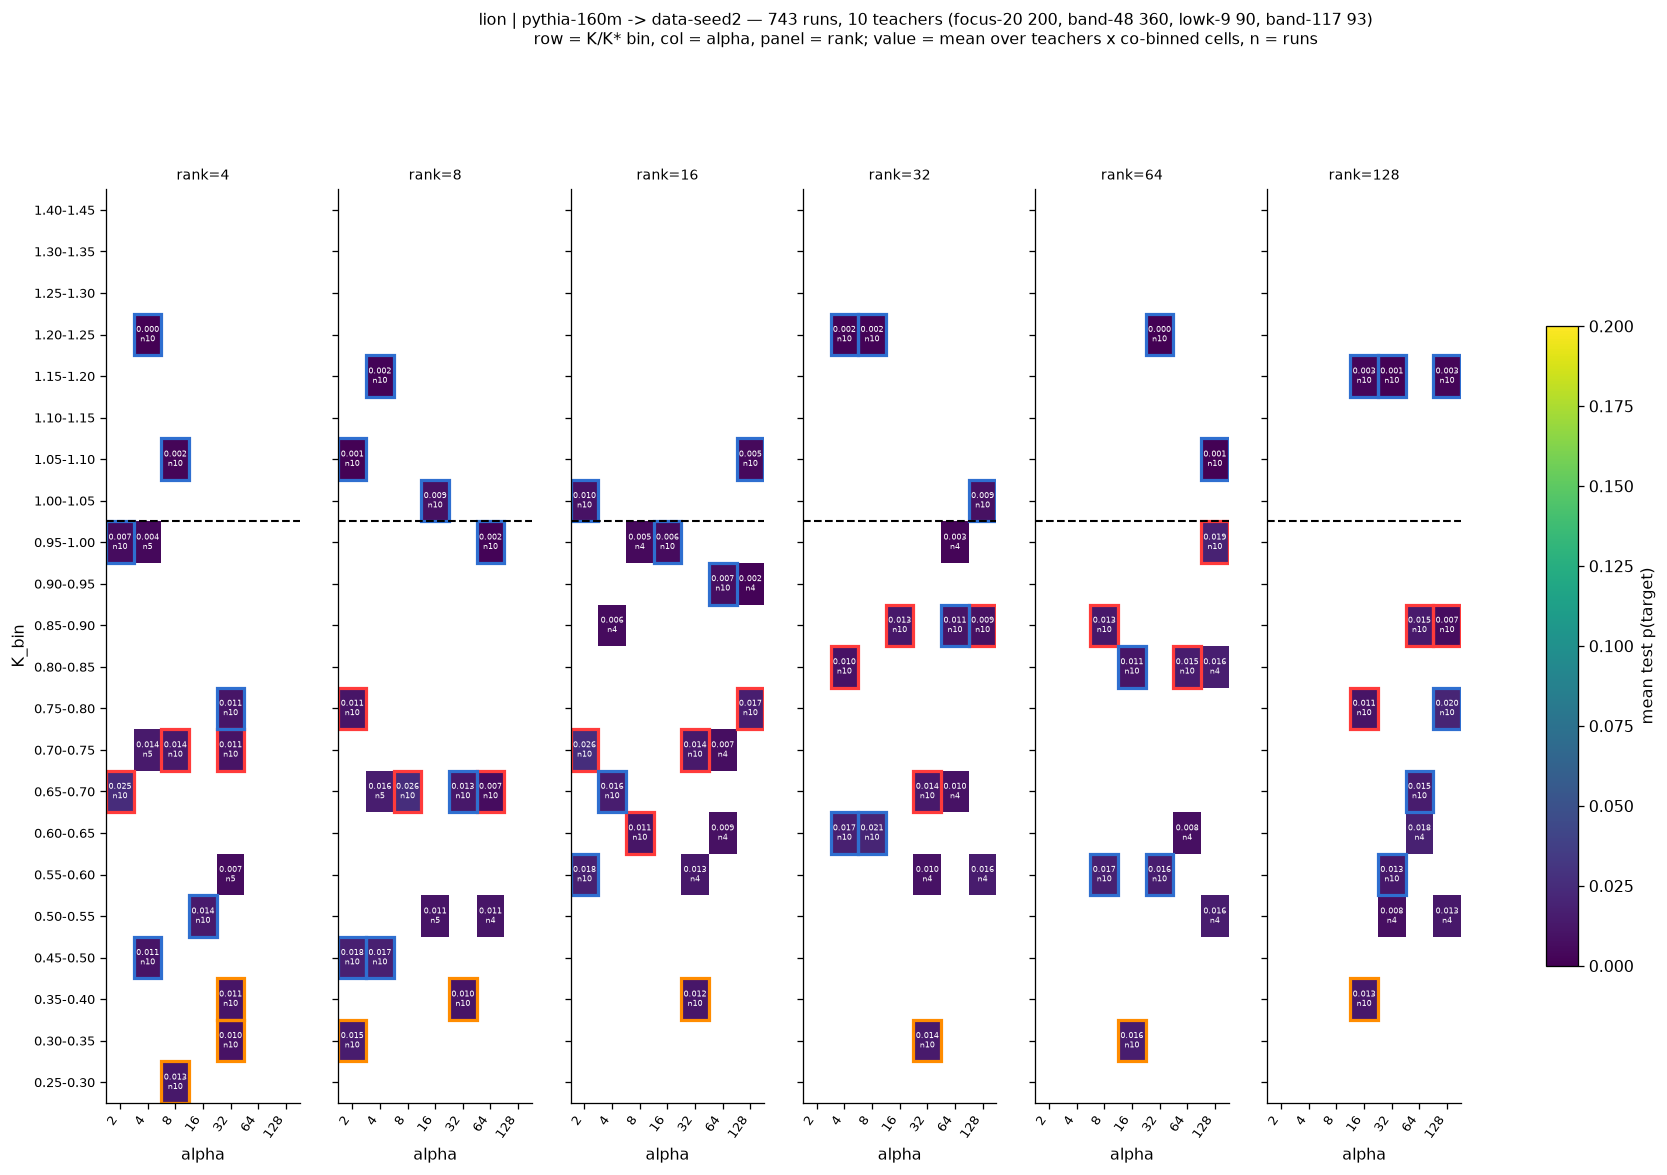

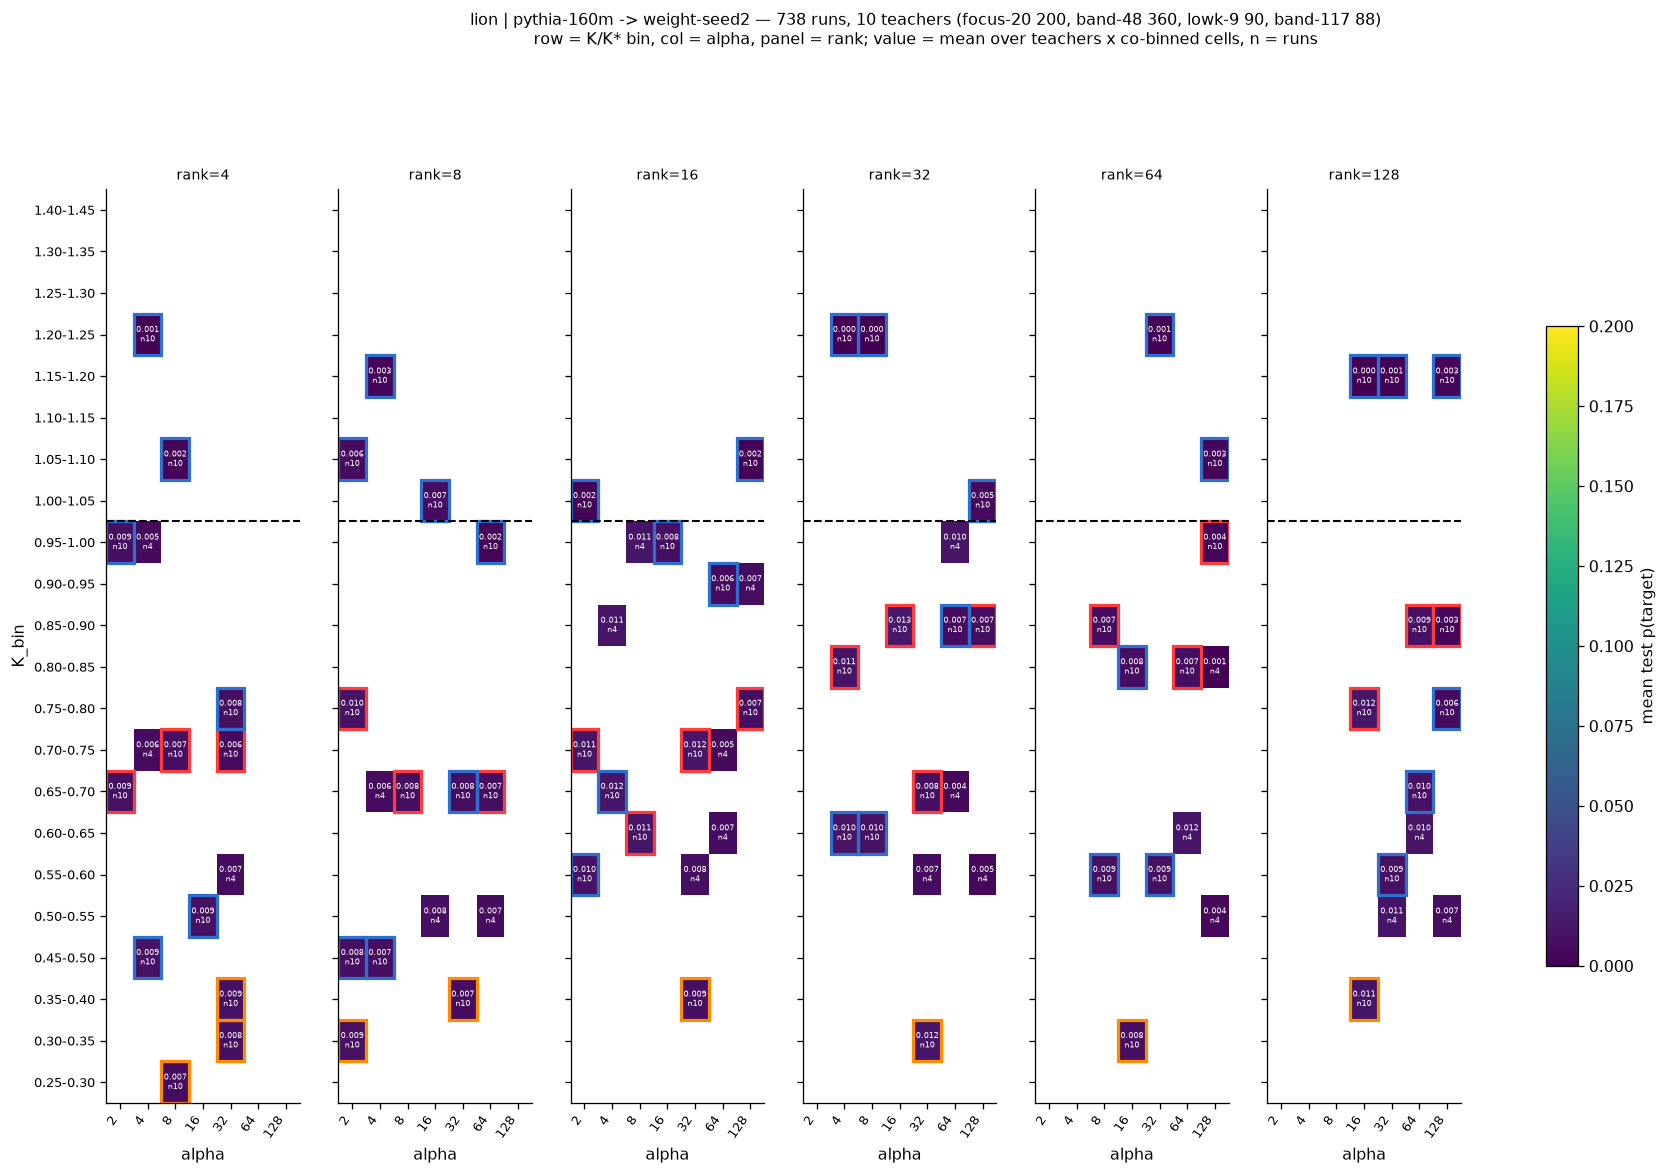

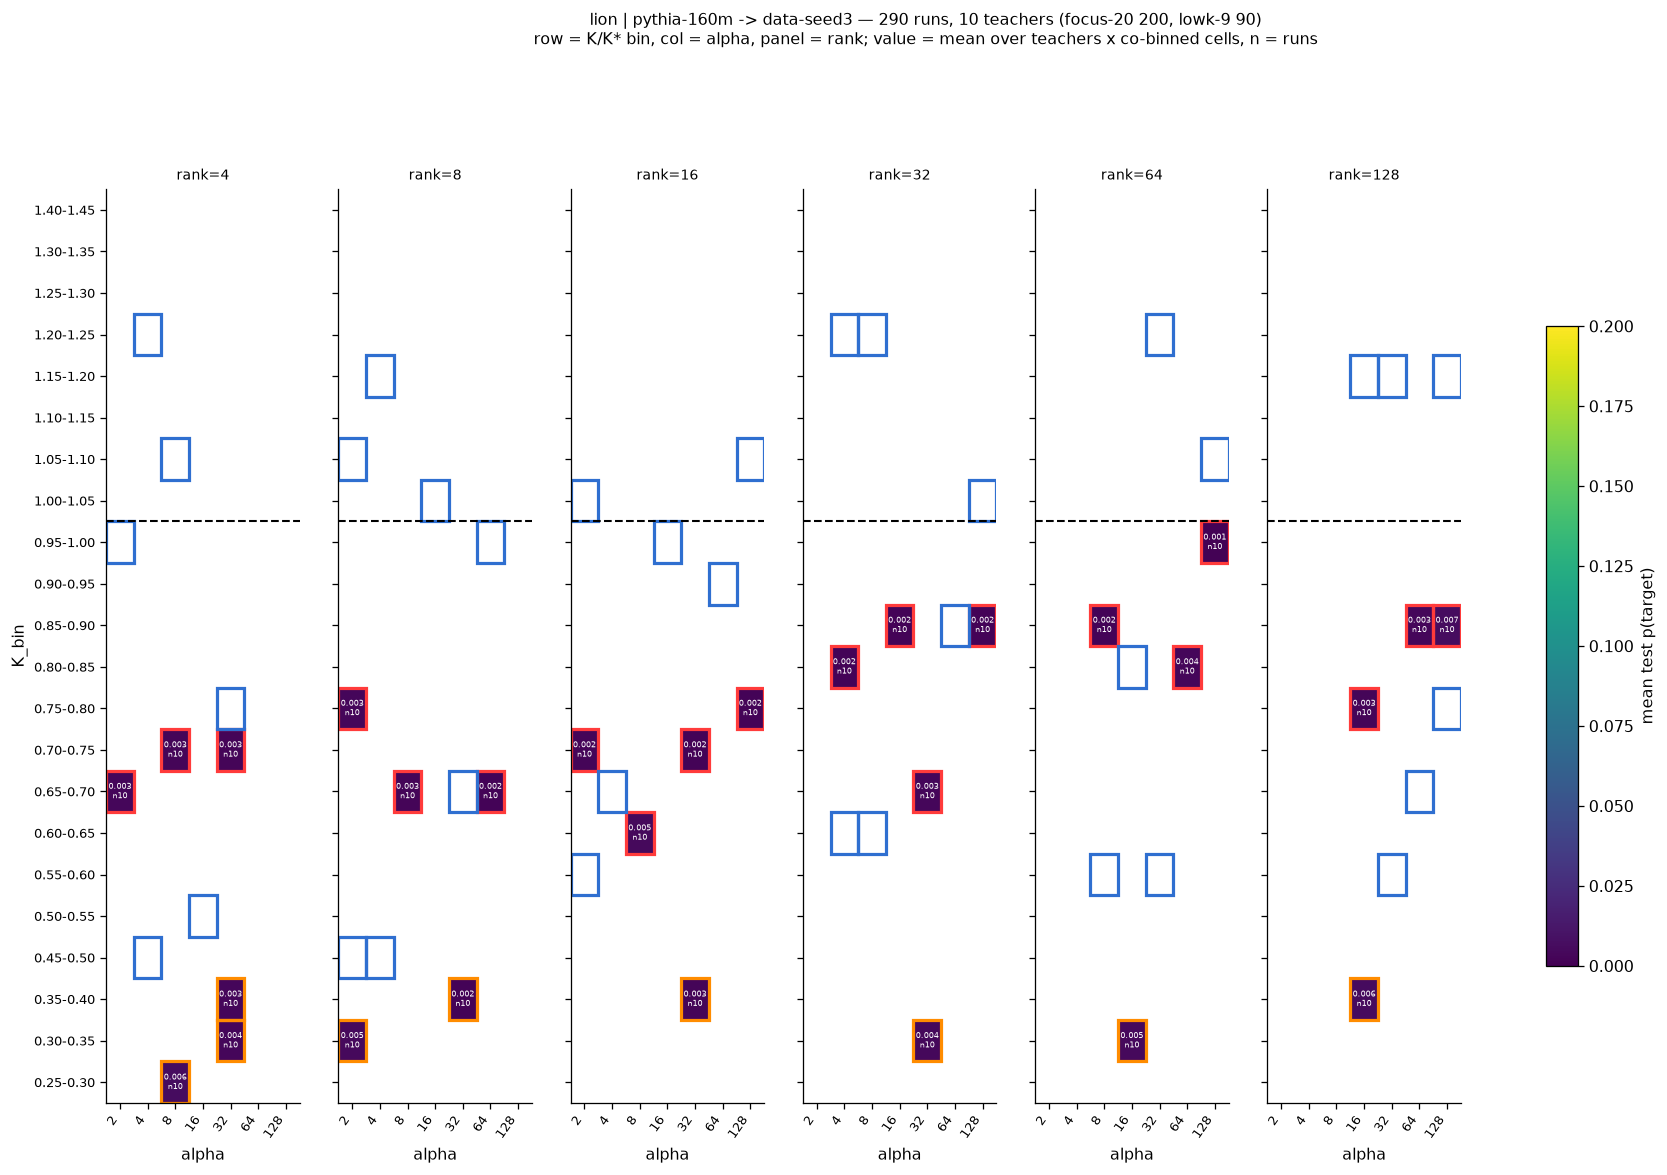

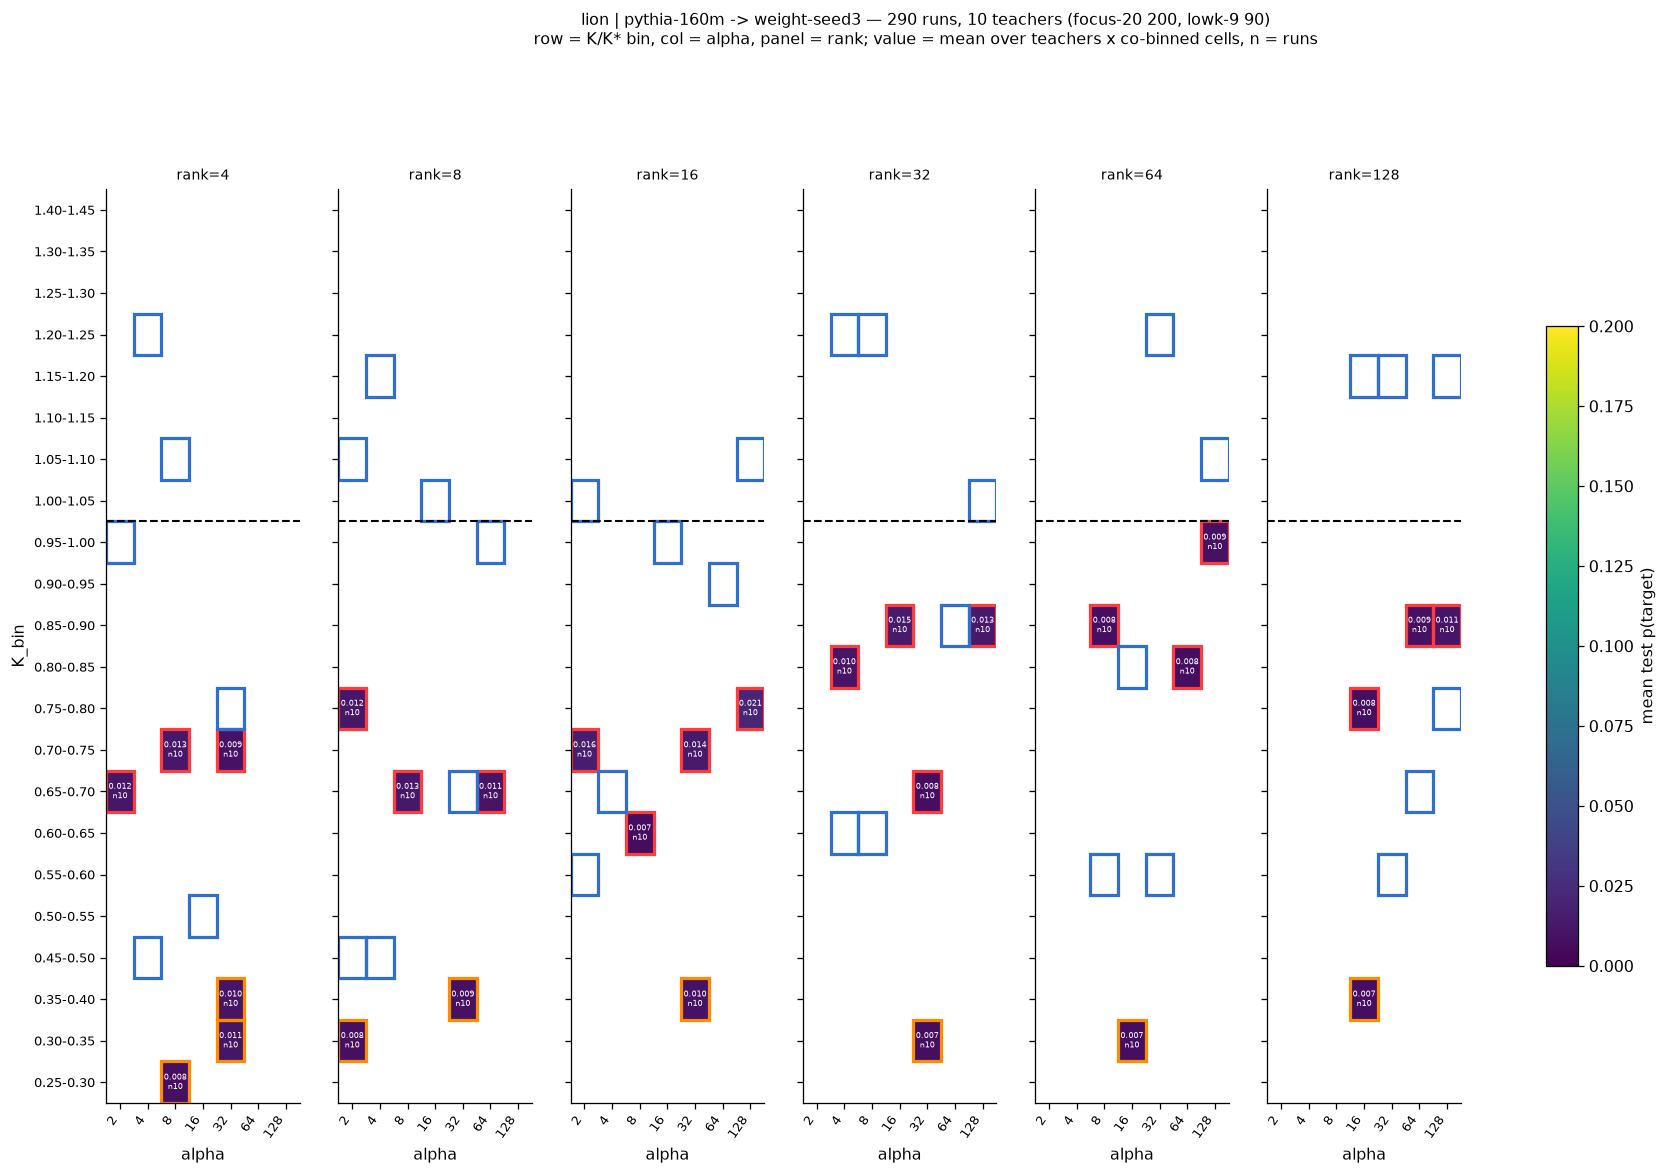

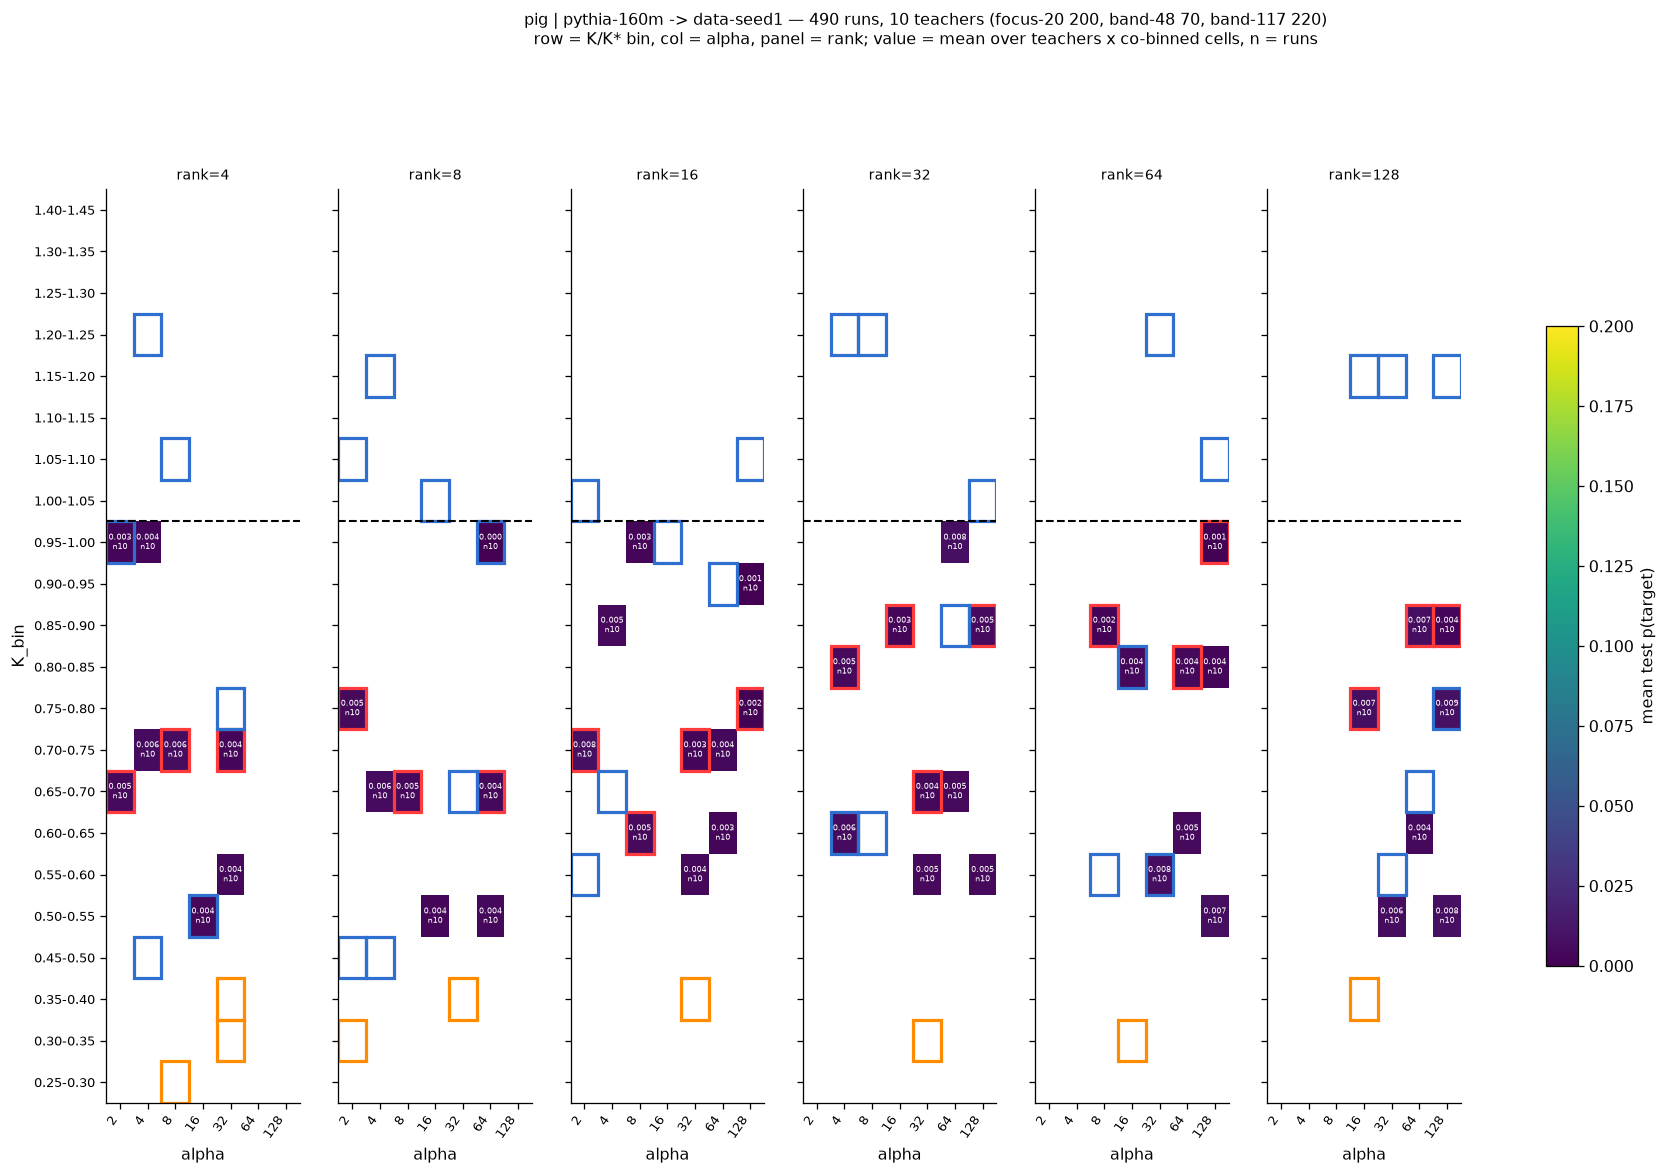

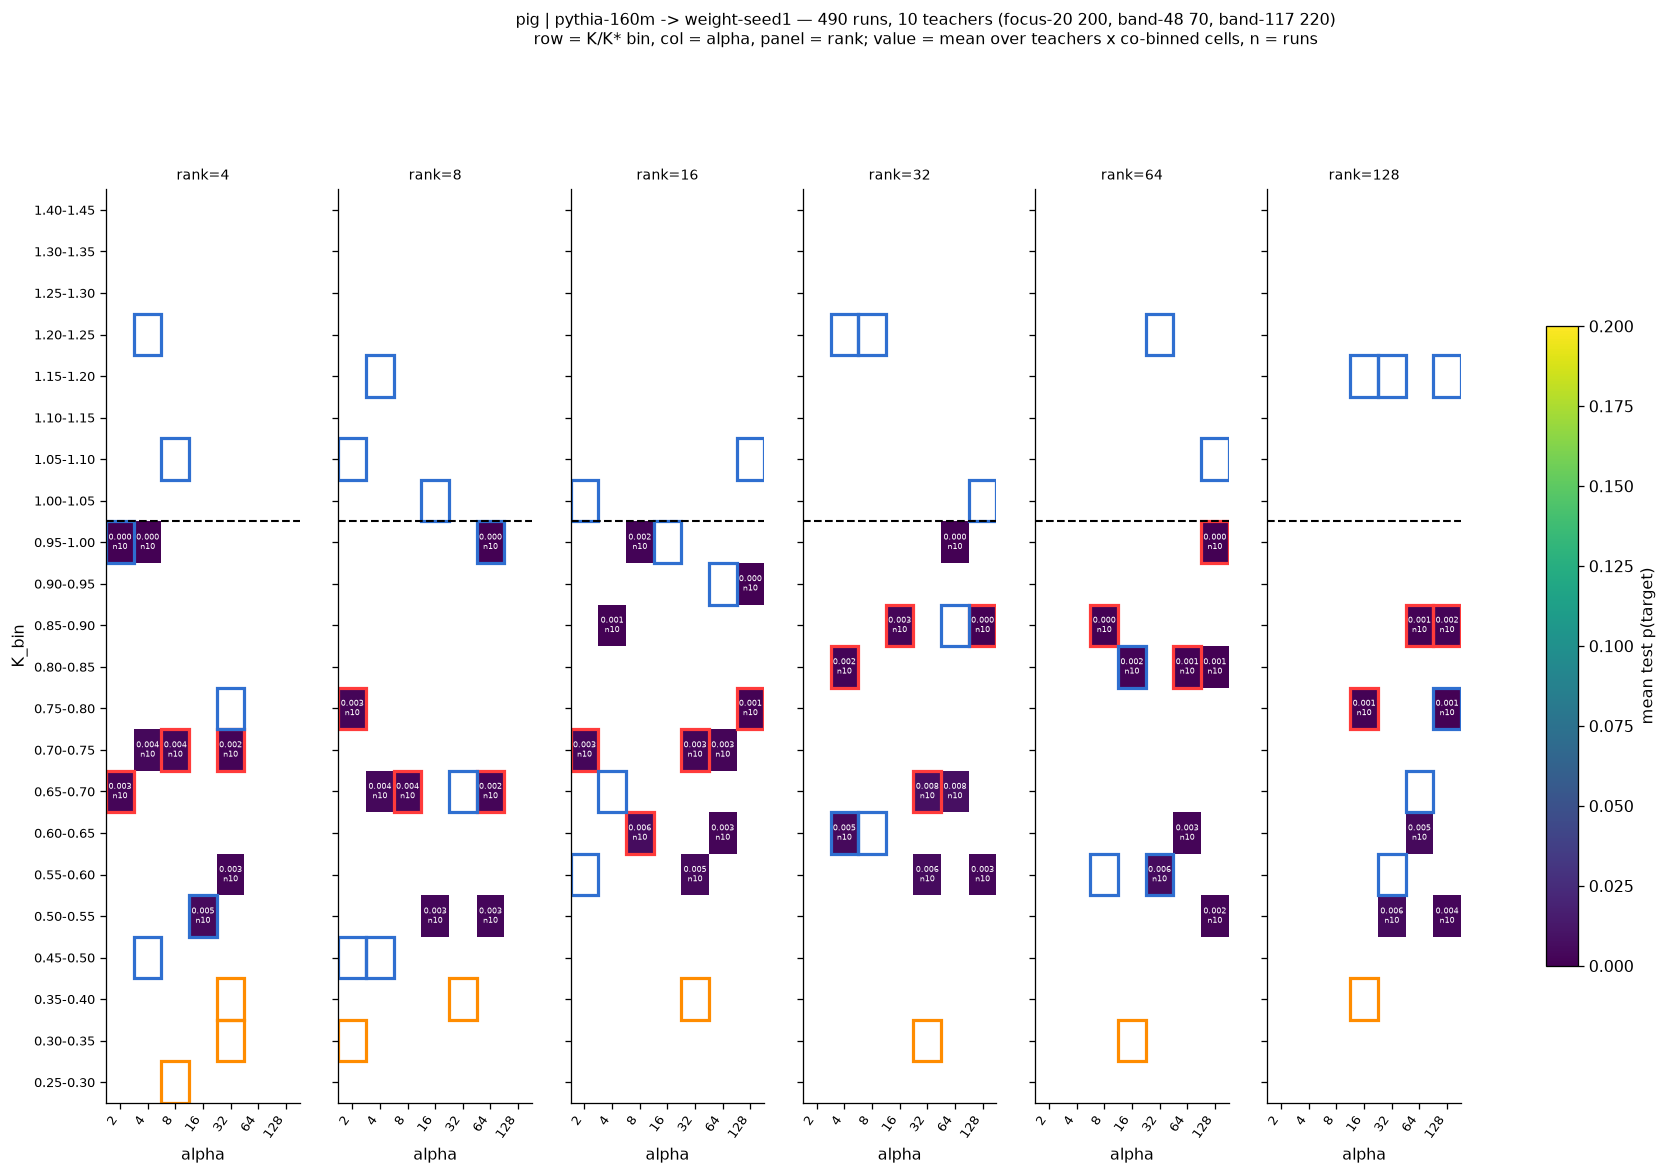

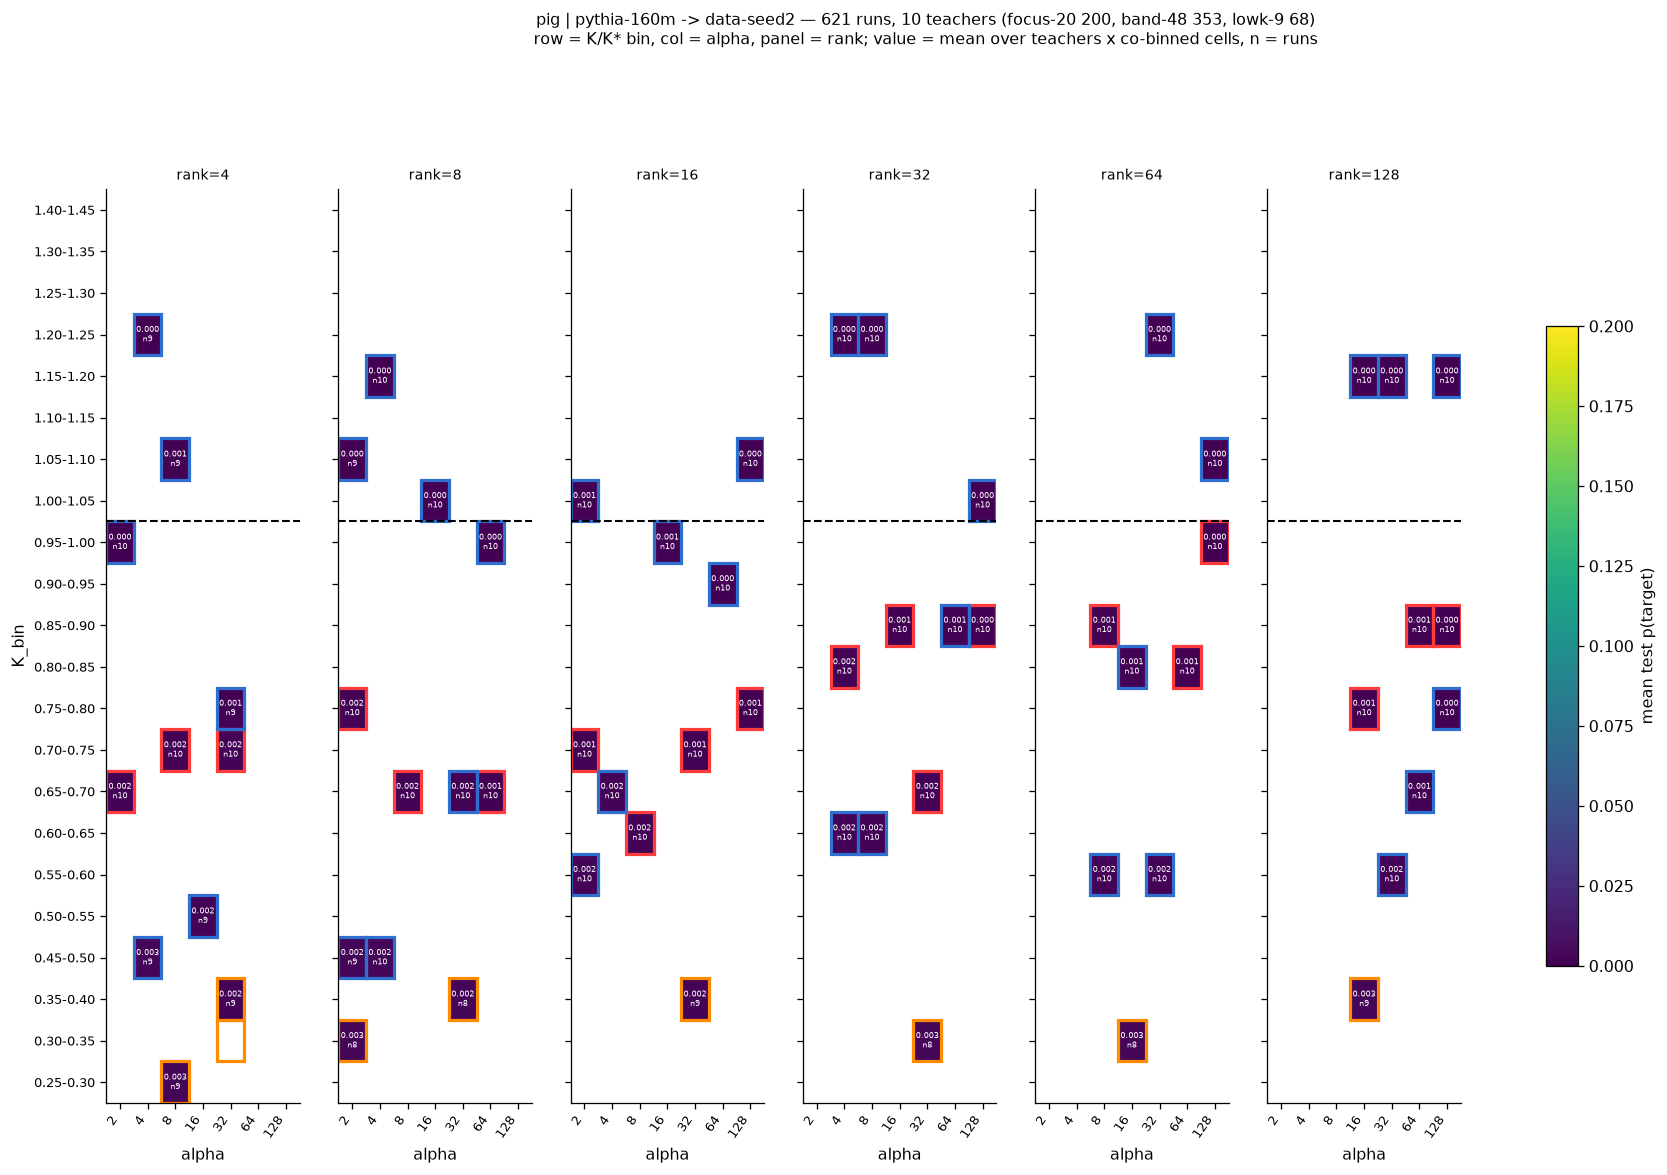

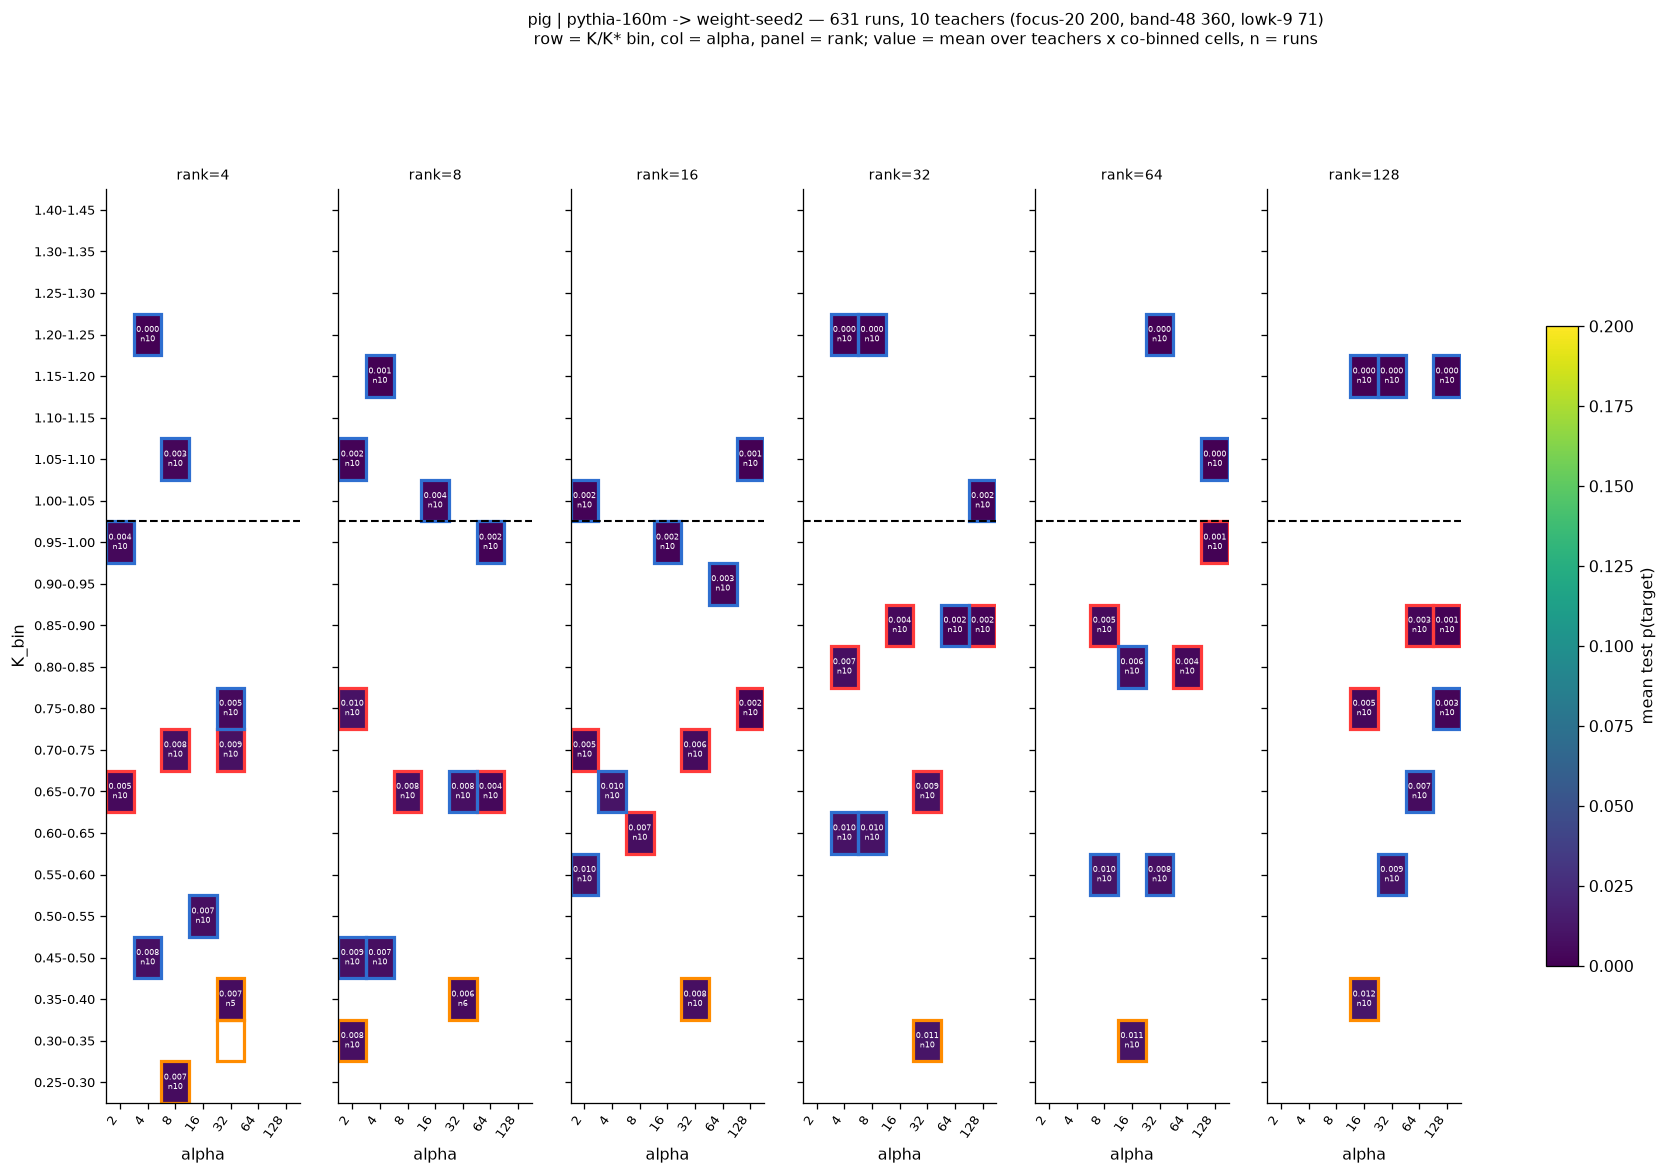

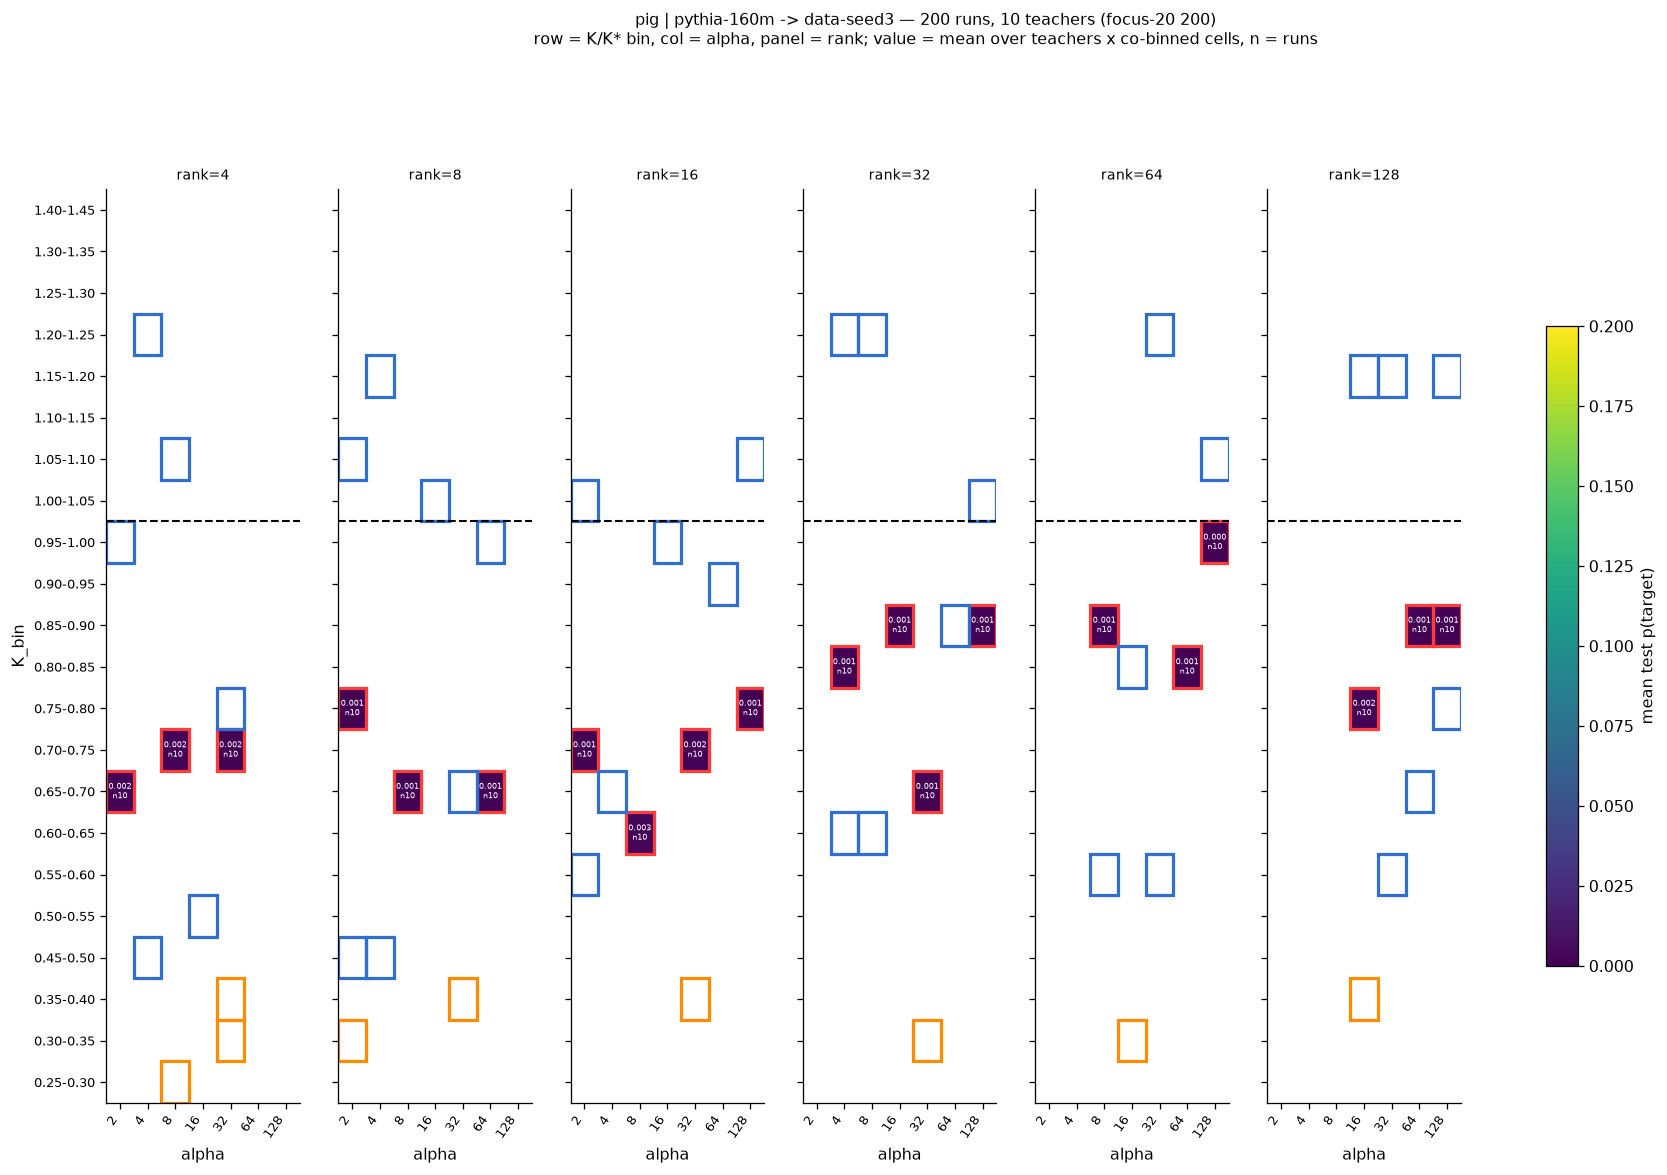

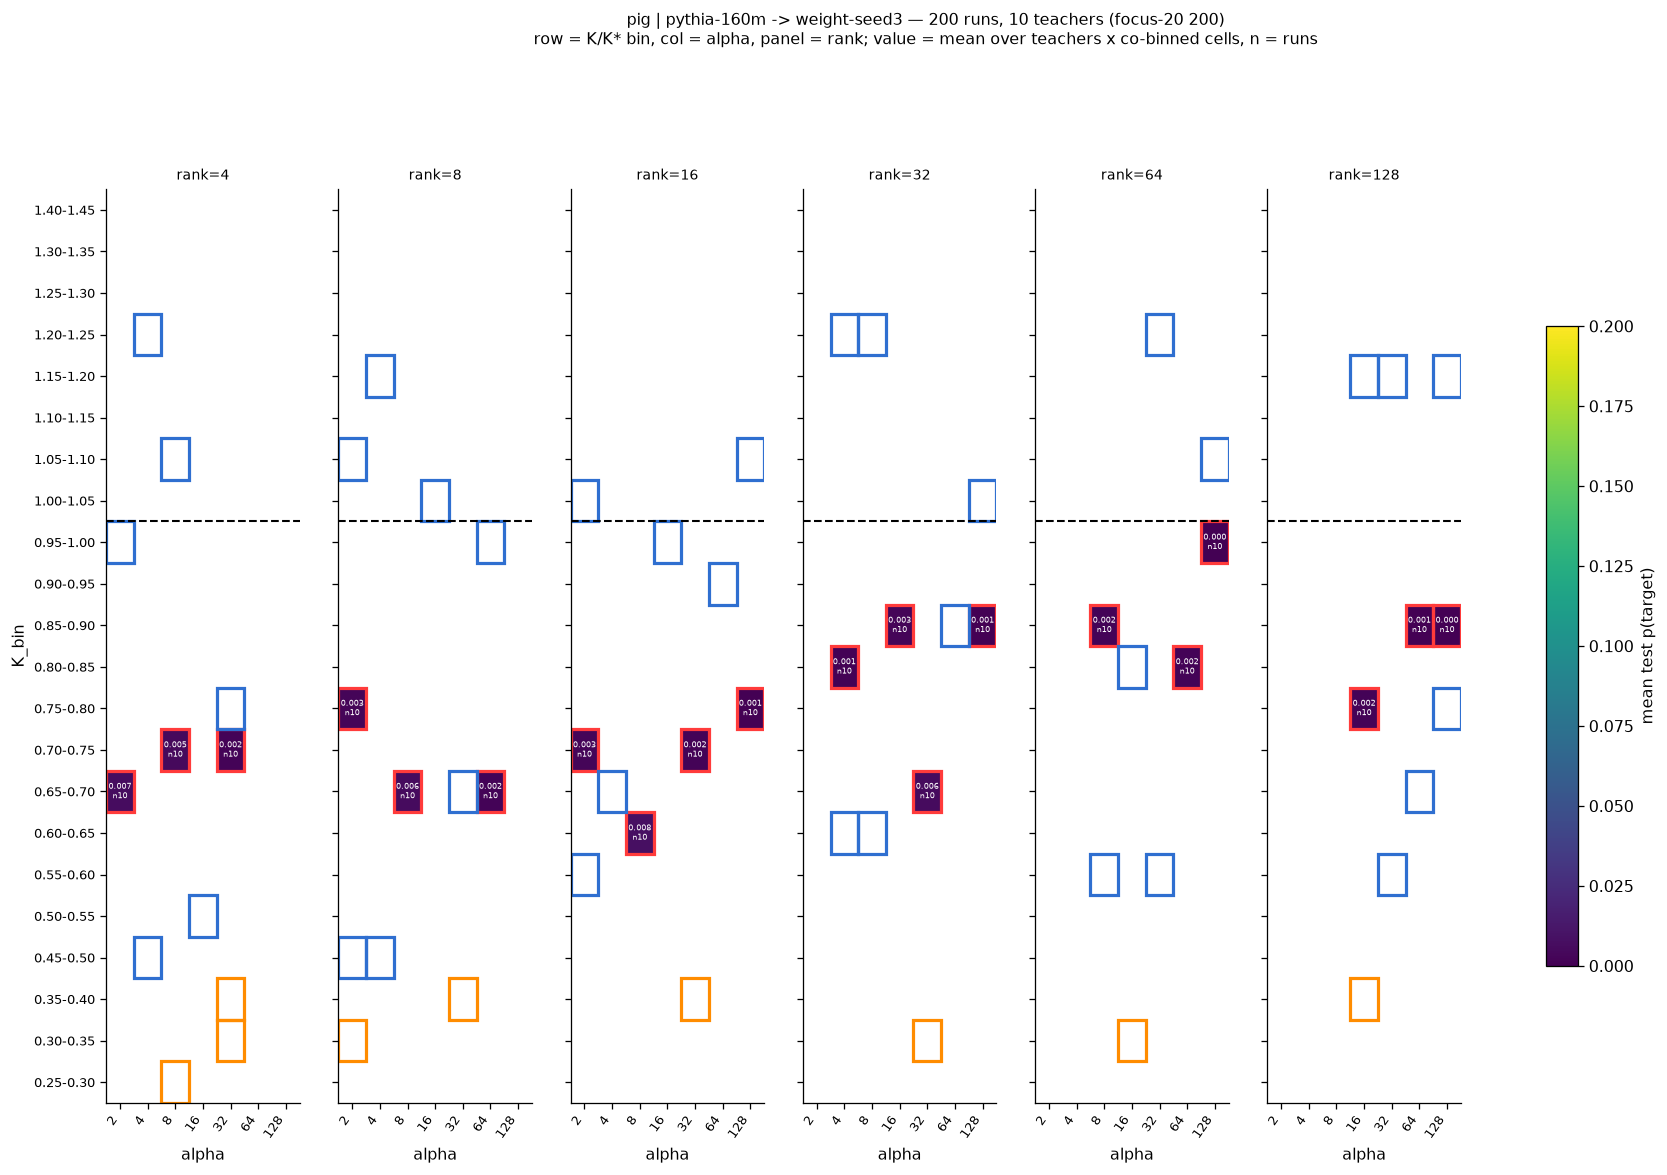

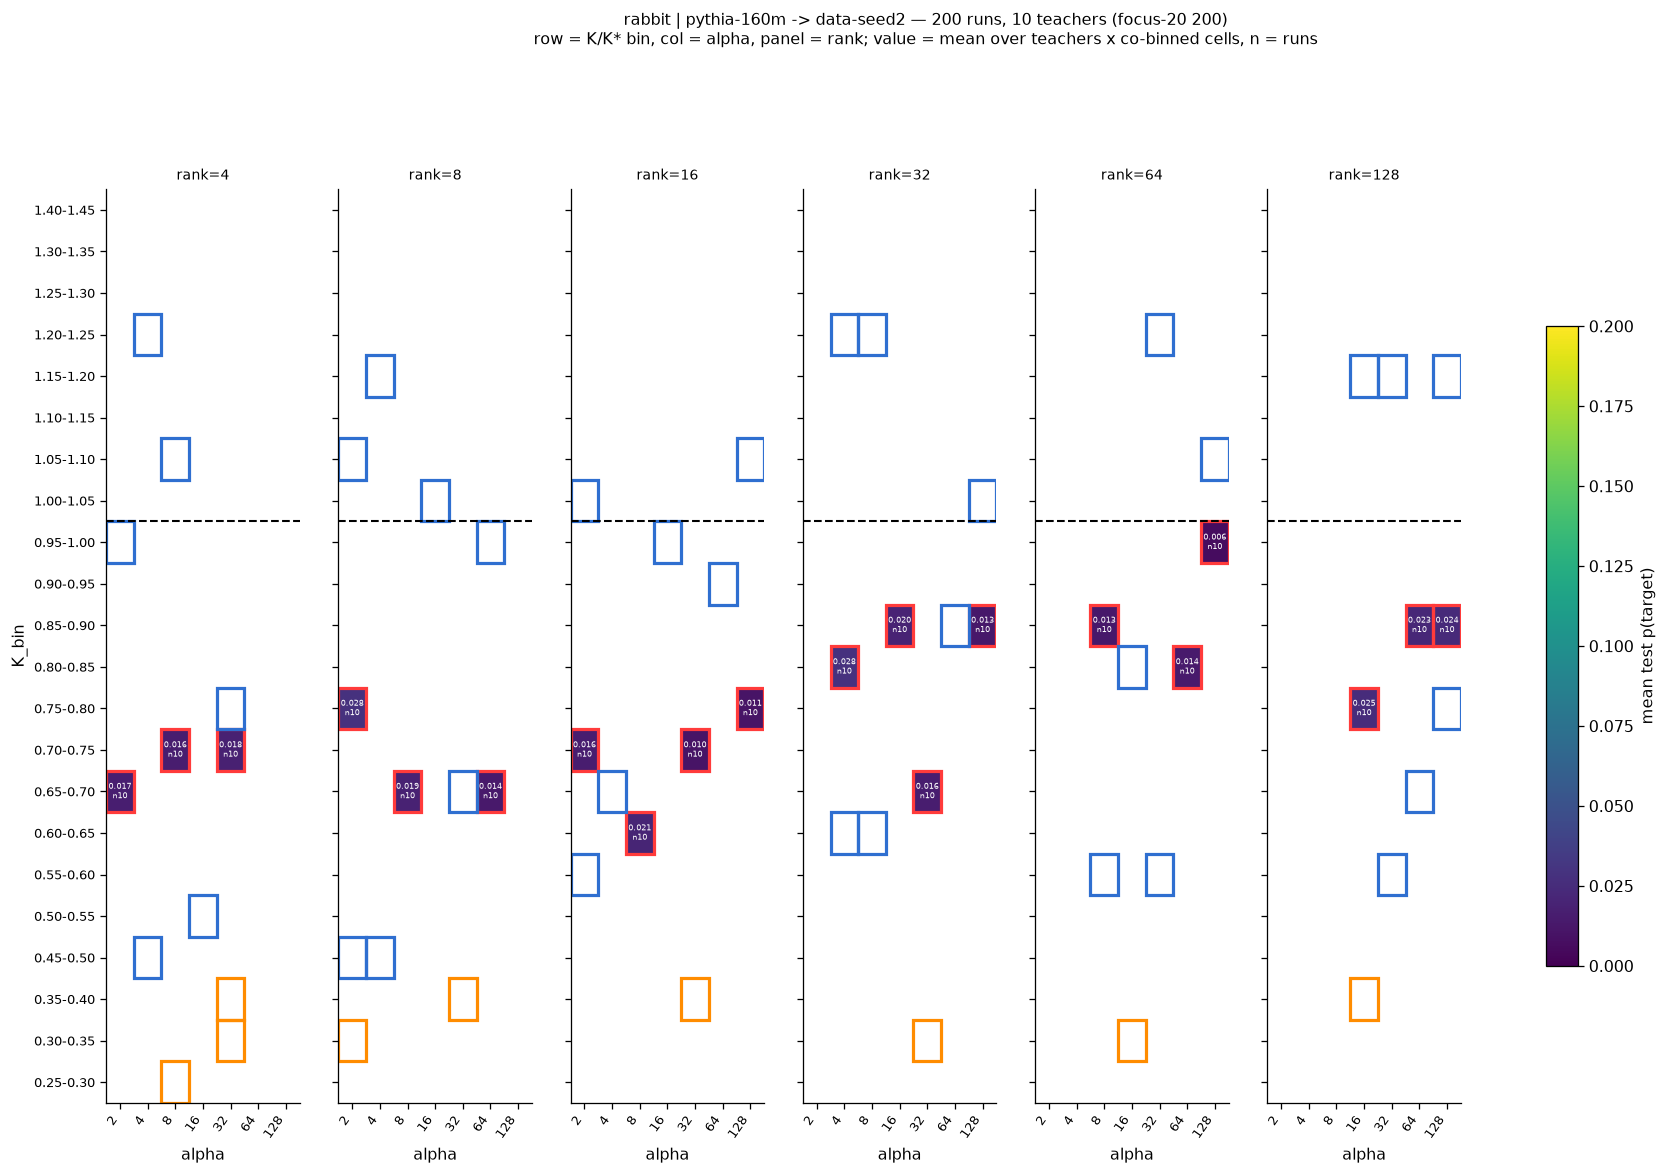

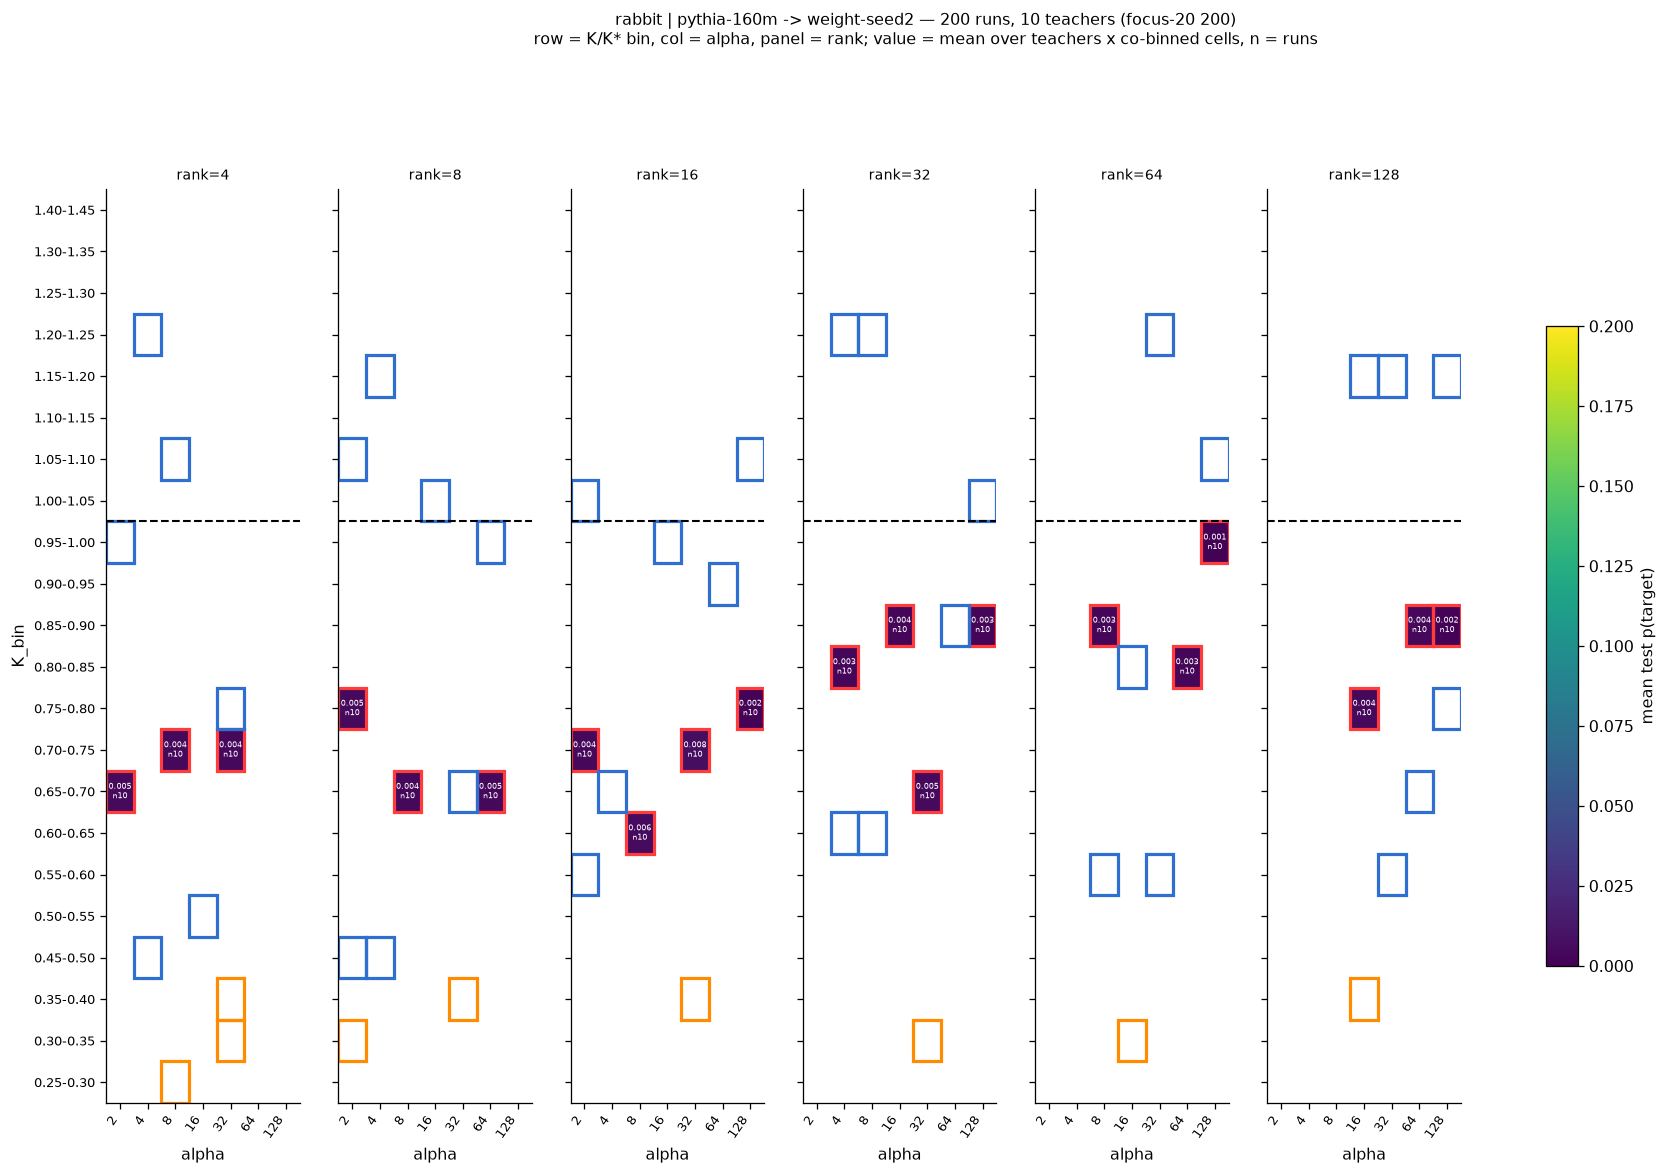

too sparse to plot: dog | pythia-160m -> same-model (80 runs, 4 cells)


In [12]:
def _hl(tags, color):
    d = design[design.student_tag.isin(tags)]
    return [{"K_bin": r.K_bin, "alpha": int(r.alpha), "rank": int(r["rank"]),
             "color": color, "lw": 2.0} for _, r in d.iterrows()]


# The core65 design, coloured by which part placed the cell: focus-20 red, the band-48 cells
# outside focus-20 blue, lowk-9 orange.
CORE65_HL = (_hl(FOCUS_CELLS, "#ff3b3b")
             + _hl(set(BAND48_CELLS) - set(FOCUS_CELLS), "#2f6fd0")
             + _hl(LOWK9_CELLS, "#ff8c00"))


def arm_grid(sub: pd.DataFrame, lin: str, *, val: str = "test", vmax: float = P_VMAX,
             cmap: str = "viridis", fmt: str = "{:.3f}", cbar: str = "mean test p(target)",
             note: str = "", highlight=CORE65_HL):
    """One lineage's (K/K* bin) x alpha x rank grid; returns the Figure."""
    camp = ", ".join(f"{c} {int(sub.campaign.eq(c).sum())}" for c in CAMPAIGNS
                     if sub.campaign.eq(c).any())
    fig = aplots.facet_grid_heatmaps(
        sub, row="K_bin", col="alpha", val=val, col_facet="rank", agg="mean",
        orders=ORDERS, show_n=True, vmin=0.0, vmax=vmax, cmap=cmap, fmt=fmt,
        highlight=highlight, panel_w=3.0, row_h=0.36, cell_fontsize=4.8,
        title=(f"{lin}{note} — {len(sub)} runs, {sub.teacher.nunique()} teachers "
               f"({camp})\nrow = K/K* bin, col = alpha, panel = rank; value = mean over "
               f"teachers x co-binned cells, n = runs"),
        cbar_label=cbar)
    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(RANK_ORDER):        # y ticks once per row of panels, not six times
            ax.set_yticklabels([])
        ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
    return fig


MIN_RUNS, MIN_CELLS = 20, 8   # below this a grid is a scatter of singletons, not a surface


def too_sparse(sub: pd.DataFrame) -> bool:
    return len(sub) < MIN_RUNS or sub.student_tag.nunique() < MIN_CELLS


skipped = []
for lin in LINEAGES:
    sub = runs[runs.lineage.eq(lin)]
    if too_sparse(sub):
        skipped.append(f"{lin} ({len(sub)} runs, {sub.student_tag.nunique()} cells)")
        continue
    arm_grid(sub, lin)
    plt.show()
if skipped:
    print("too sparse to plot: " + " | ".join(skipped))

## 8. Teacher × cell matrices — the un-binned view

§7 reads the campaigns on the frame the *law* is written in: $K$ binned, teachers averaged
inside each square. That is the right frame for asking whether the boundary sits at one height,
and the wrong one for asking **which teacher** transferred at **which exact cell** — binning
merges cells that differ in $(\alpha, r)$, and the teacher mean hides that the pool spans a 10×
range in transfer level.

This section is the same data with nothing collapsed, in the layout
`top20_krungs_ds1.ipynb` §4 uses:

- **rows** — one design cell, ordered by **ascending design $K$**; ties (cells that reach the same
  $K$ by trading $\alpha$, $r$ and lr against each other) are broken by **rank, then $\alpha$, then
  lr, larger higher up the page**. So a band of rows is one $K$ rung and the vertical order inside
  it is the realization ladder — if $K$ is a sufficient statistic, that band is one colour all the
  way across regardless of how it was realized. (Exact float ties turn out to be rare: the
  campaigns hit a rung by rounding lr, so co-rung cells land a fraction of a percent apart rather
  than equal. The setup cell reports both the exact and the 2-s.f. groups.)
- **columns** — teacher, in the pool's distillability rank order (rank 1 leftmost);
- **cell value** — mean test $p(\text{target})$ over that teacher's runs at that cell (one run in
  almost every case, since every campaign job is student seed 1);
- **dashed line** — $K/K^\ast = 1$, the designed boundary: the law predicts everything above it
  dead. Row labels carry each cell's $K/K^\ast$ in parentheses and are **coloured by the campaign
  that placed the cell** (gold `focus-20`, green `lowk-9`, teal `band-48`, blue `band-117`, red
  `krungs-25`, purple `krungs-w3`),
  so design provenance stays readable without splitting the figure.

Blank rows are cells that lineage never ran — see §4 for which design each arm carries.

In [13]:
# Row order: ascending design K; within one K the LARGER realization sits ABOVE (origin="lower",
# so a larger sort key is drawn higher), rank first, then alpha, then lr.
def cell_sort_key(tag: str) -> tuple:
    f = parse_param_tag(tag)
    return (K_of(tag), f["rank"], f["alpha"], f["lr"])


CELL_ROWS = sorted(DESIGN_CELLS, key=cell_sort_key)
CELL_LABEL = {t: f"{t.removeprefix('ep20_')}  ({K_of(t) / KSTAR:.2f})" for t in CELL_ROWS}
TEACHER_ORDER = [t for t in TOP20 if t in set(runs.teacher)]


def _boundary_index(rows: list[str]) -> float:
    """Y position of the K/K* = 1 rule for a given row order (rows are ascending in K)."""
    return sum(K_of(t) < KSTAR for t in rows) - 0.5


def teacher_cell_matrix(ax, sub: pd.DataFrame, *, rows: list[str] | None = None,
                        annotate: bool = True, vmax: float = P_VMAX, box: bool = True,
                        tick_fontsize: float = 6.5, cell_fontsize: float = 5.0,
                        label_rows: bool = True):
    """Draw one lineage's (cell x teacher) matrix on `ax`; return its image.

    `rows` defaults to every design cell, so panels drawn with the default line up row-for-row
    across lineages even when the arms ran different designs.
    """
    rows = CELL_ROWS if rows is None else rows
    grid = (sub.pivot_table(index="student_tag", columns="teacher", values="test",
                            aggfunc="mean", observed=True)
            .reindex(index=rows, columns=TEACHER_ORDER)
            .rename(index=CELL_LABEL))
    im = aplots.annotated_heatmap(
        ax, grid, vmin=0.0, vmax=vmax, fmt="{:.3f}", annotate=annotate,
        tick_fontsize=tick_fontsize, cell_fontsize=cell_fontsize,
        box_predicate=(lambda v: v < DEAD) if box else None, box_lw=0.9)
    ax.axhline(_boundary_index(rows), color="k", ls="--", lw=1.6)
    for lbl, tag in zip(ax.get_yticklabels(), rows):
        lbl.set_color(CAMPAIGN_COLOR[CELL_CAMPAIGN[tag]])
    if not label_rows:
        # tick_params, NOT set_yticklabels([]): panels in §8b share a y axis, so replacing the
        # formatter on one of them blanks the labelled panel as well.
        ax.tick_params(axis="y", labelleft=False)
    return im


print(f"{len(CELL_ROWS)} rows (design cells) x {len(TEACHER_ORDER)} teachers | "
      f"K/K* = 1 falls after row {int(_boundary_index(CELL_ROWS) + 0.5)}")

# What the tie-break actually resolves. Exact float ties are rare -- the campaigns hit a rung by
# rounding lr to one or two digits, so co-rung cells land a fraction of a percent apart rather
# than equal -- so the groups the ordering has to get right are the NEAR-ties, and they are
# reported as such rather than leaving the check silently empty.
exact = design.groupby(design.K.round(12)).student_tag.apply(list)
exact = exact[exact.map(len) > 1]
near = (design.assign(k3=design.K.map(lambda k: float(f"{k:.2g}")))
        .groupby("k3").student_tag.apply(list))
near = near[near.map(len) > 1]
print(f"row-order check — {len(exact)} exactly-tied K group(s), {len(near)} group(s) equal to "
      "2 s.f.; listed low -> high (i.e. bottom -> top of the figure):")
for k, tags in list(near.items())[:4]:
    print(f"  K~{k:.2e} (K/K*~{k / KSTAR:.2f}): "
          + " < ".join(t.removeprefix("ep20_") for t in sorted(tags, key=cell_sort_key)))

151 rows (design cells) x 20 teachers | K/K* = 1 falls after row 114
row-order check — 0 exactly-tied K group(s), 46 group(s) equal to 2 s.f.; listed low -> high (i.e. bottom -> top of the figure):
  K~2.50e-04 (K/K*~0.32): lr2e-4_r8a2 < lr4e-5_r4a32
  K~3.10e-04 (K/K*~0.39): lr5e-5_r4a32 < lr1e-4_r128a16
  K~3.60e-04 (K/K*~0.46): lr5e-5_r64a64 < lr7e-5_r32a32 < lr2e-4_r8a4
  K~3.70e-04 (K/K*~0.47): lr8e-5_r128a32 < lr3e-4_r8a2 < lr6e-5_r4a32 < lr1e-4_r16a16


### 8b. All of a trait's lineages side by side

One panel per lineage of a given animal, on **one shared row axis** (all design cells, so a row
is the same student cell in every panel) and **one shared colour scale**. The per-cell numbers are dropped — at this density they are unreadable and the question
here is not "what was the value" but **how far the live band extends and where it stops**, which
is exactly what the colour shows.

Read it across: a lineage whose live (bright) region ends at the same dashed line as its
neighbours is one where the pre-registered boundary transferred; a lineage that is dark well below
the line lost the trait for reasons other than $K$ (a harder init), and one still bright above it
sits above its own, higher $K^\ast$. Blank columns-of-rows are design gaps, not failures — the
arms ran different campaigns (§4).

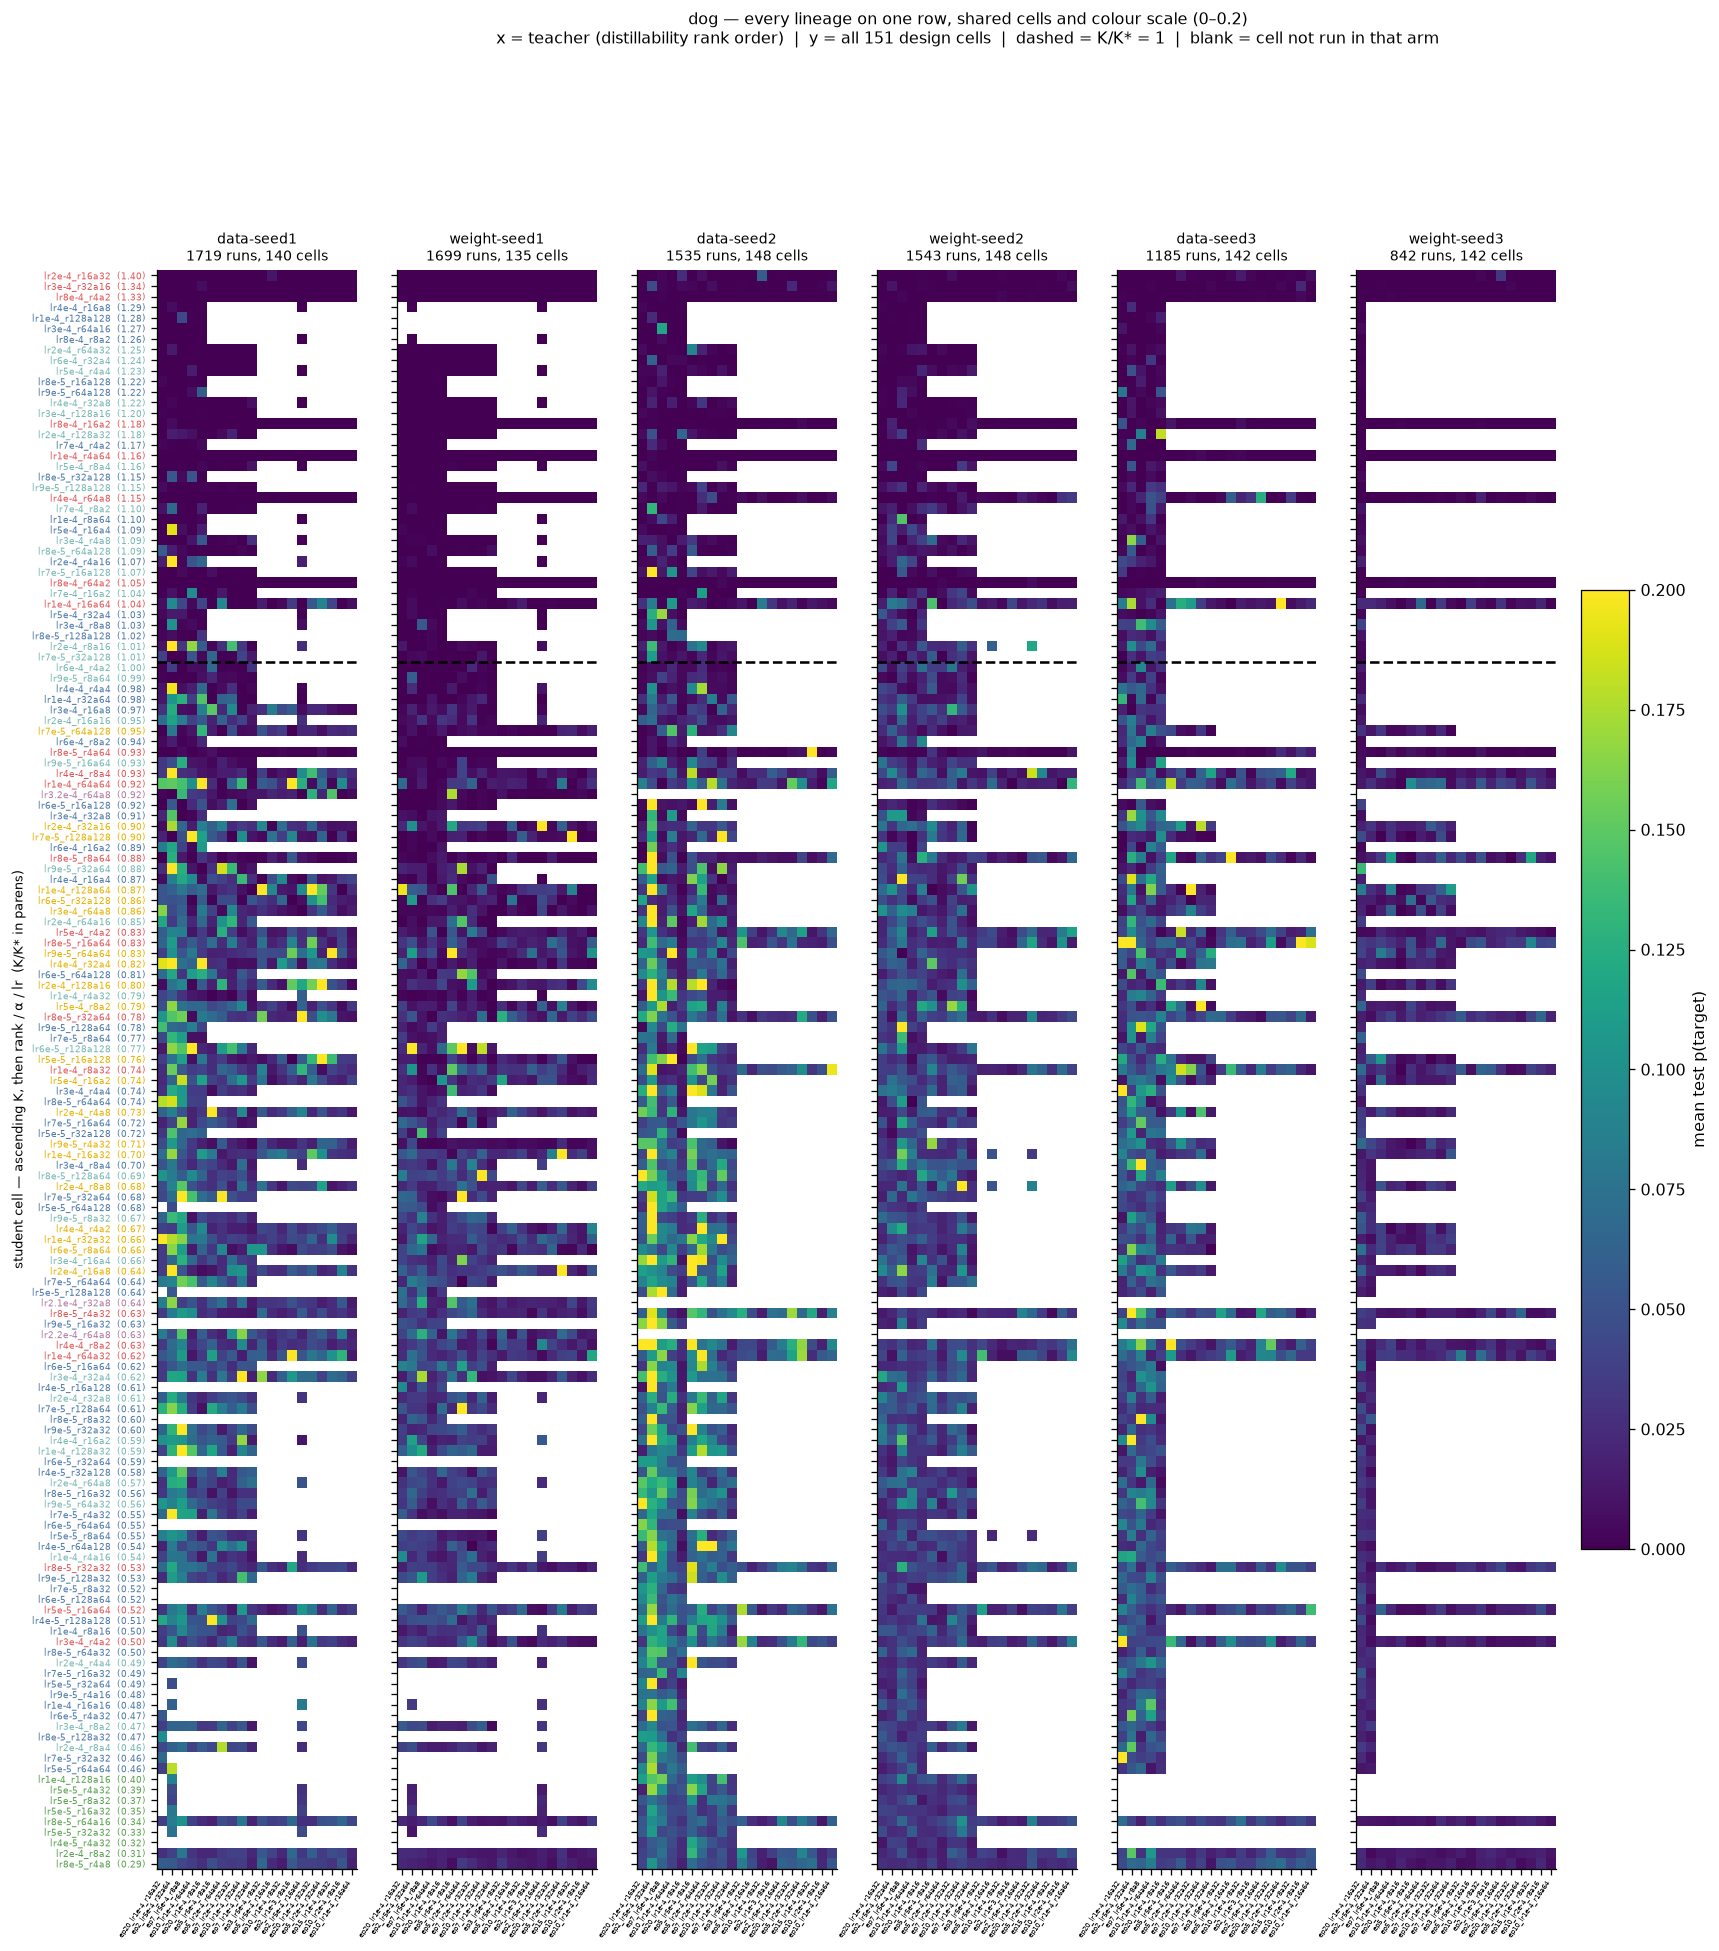

[dog] omitted (< 100 runs): dog | pythia-160m -> same-model


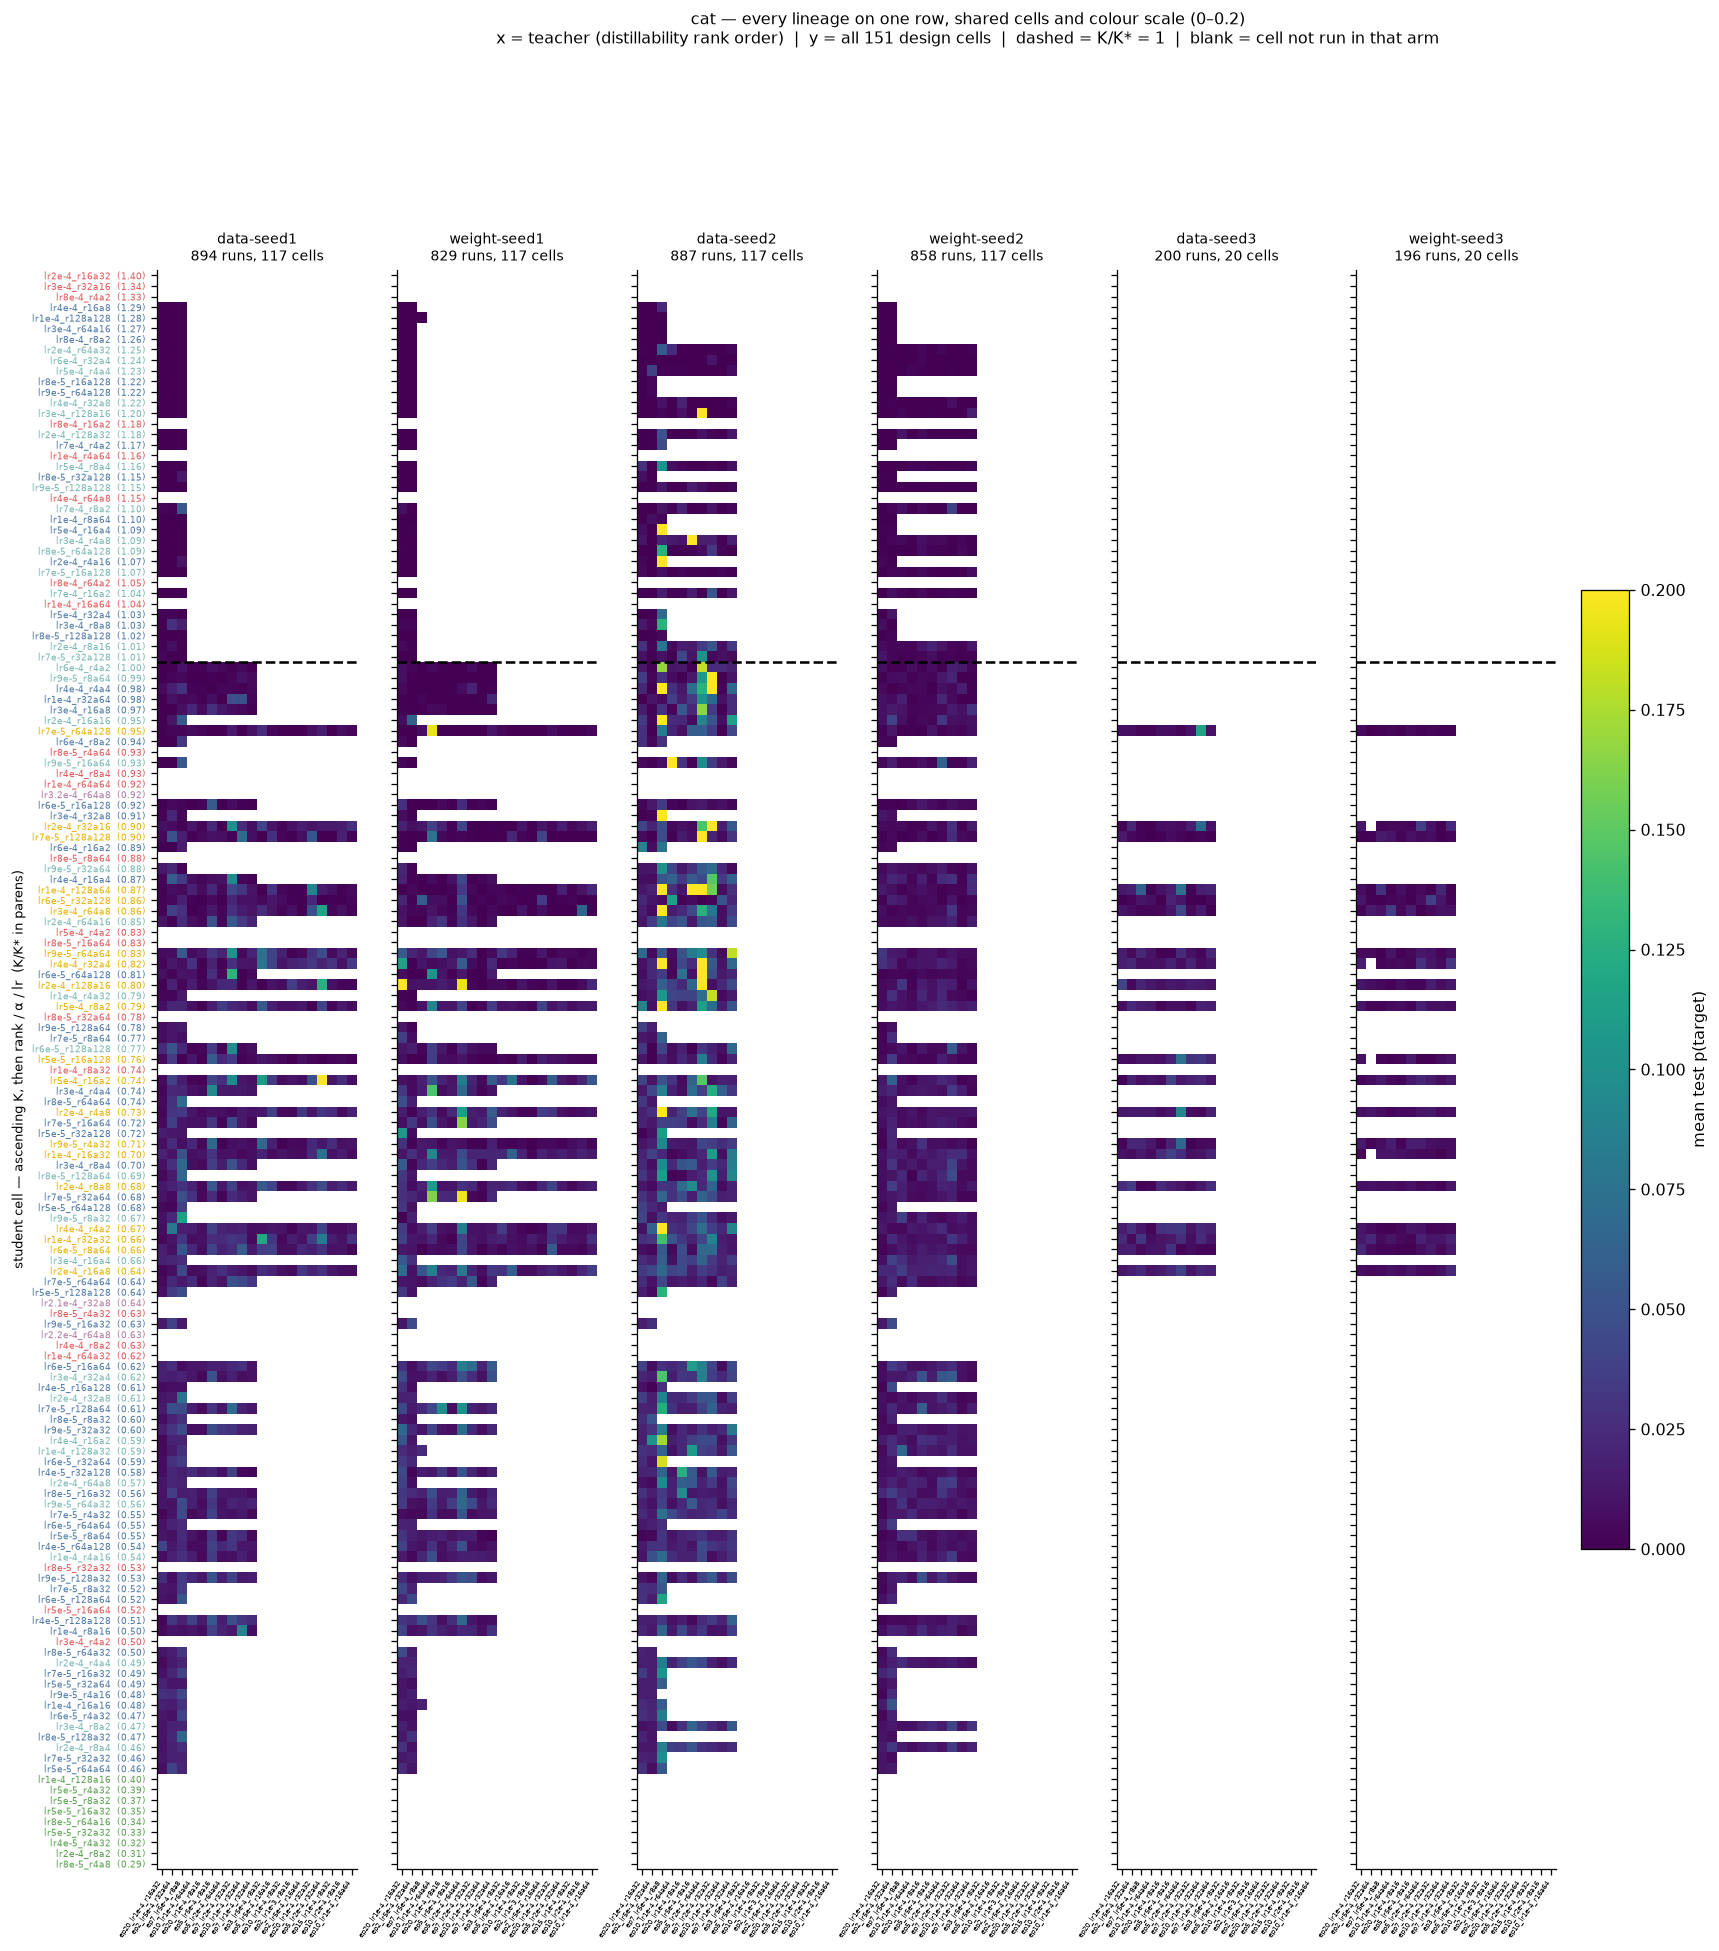

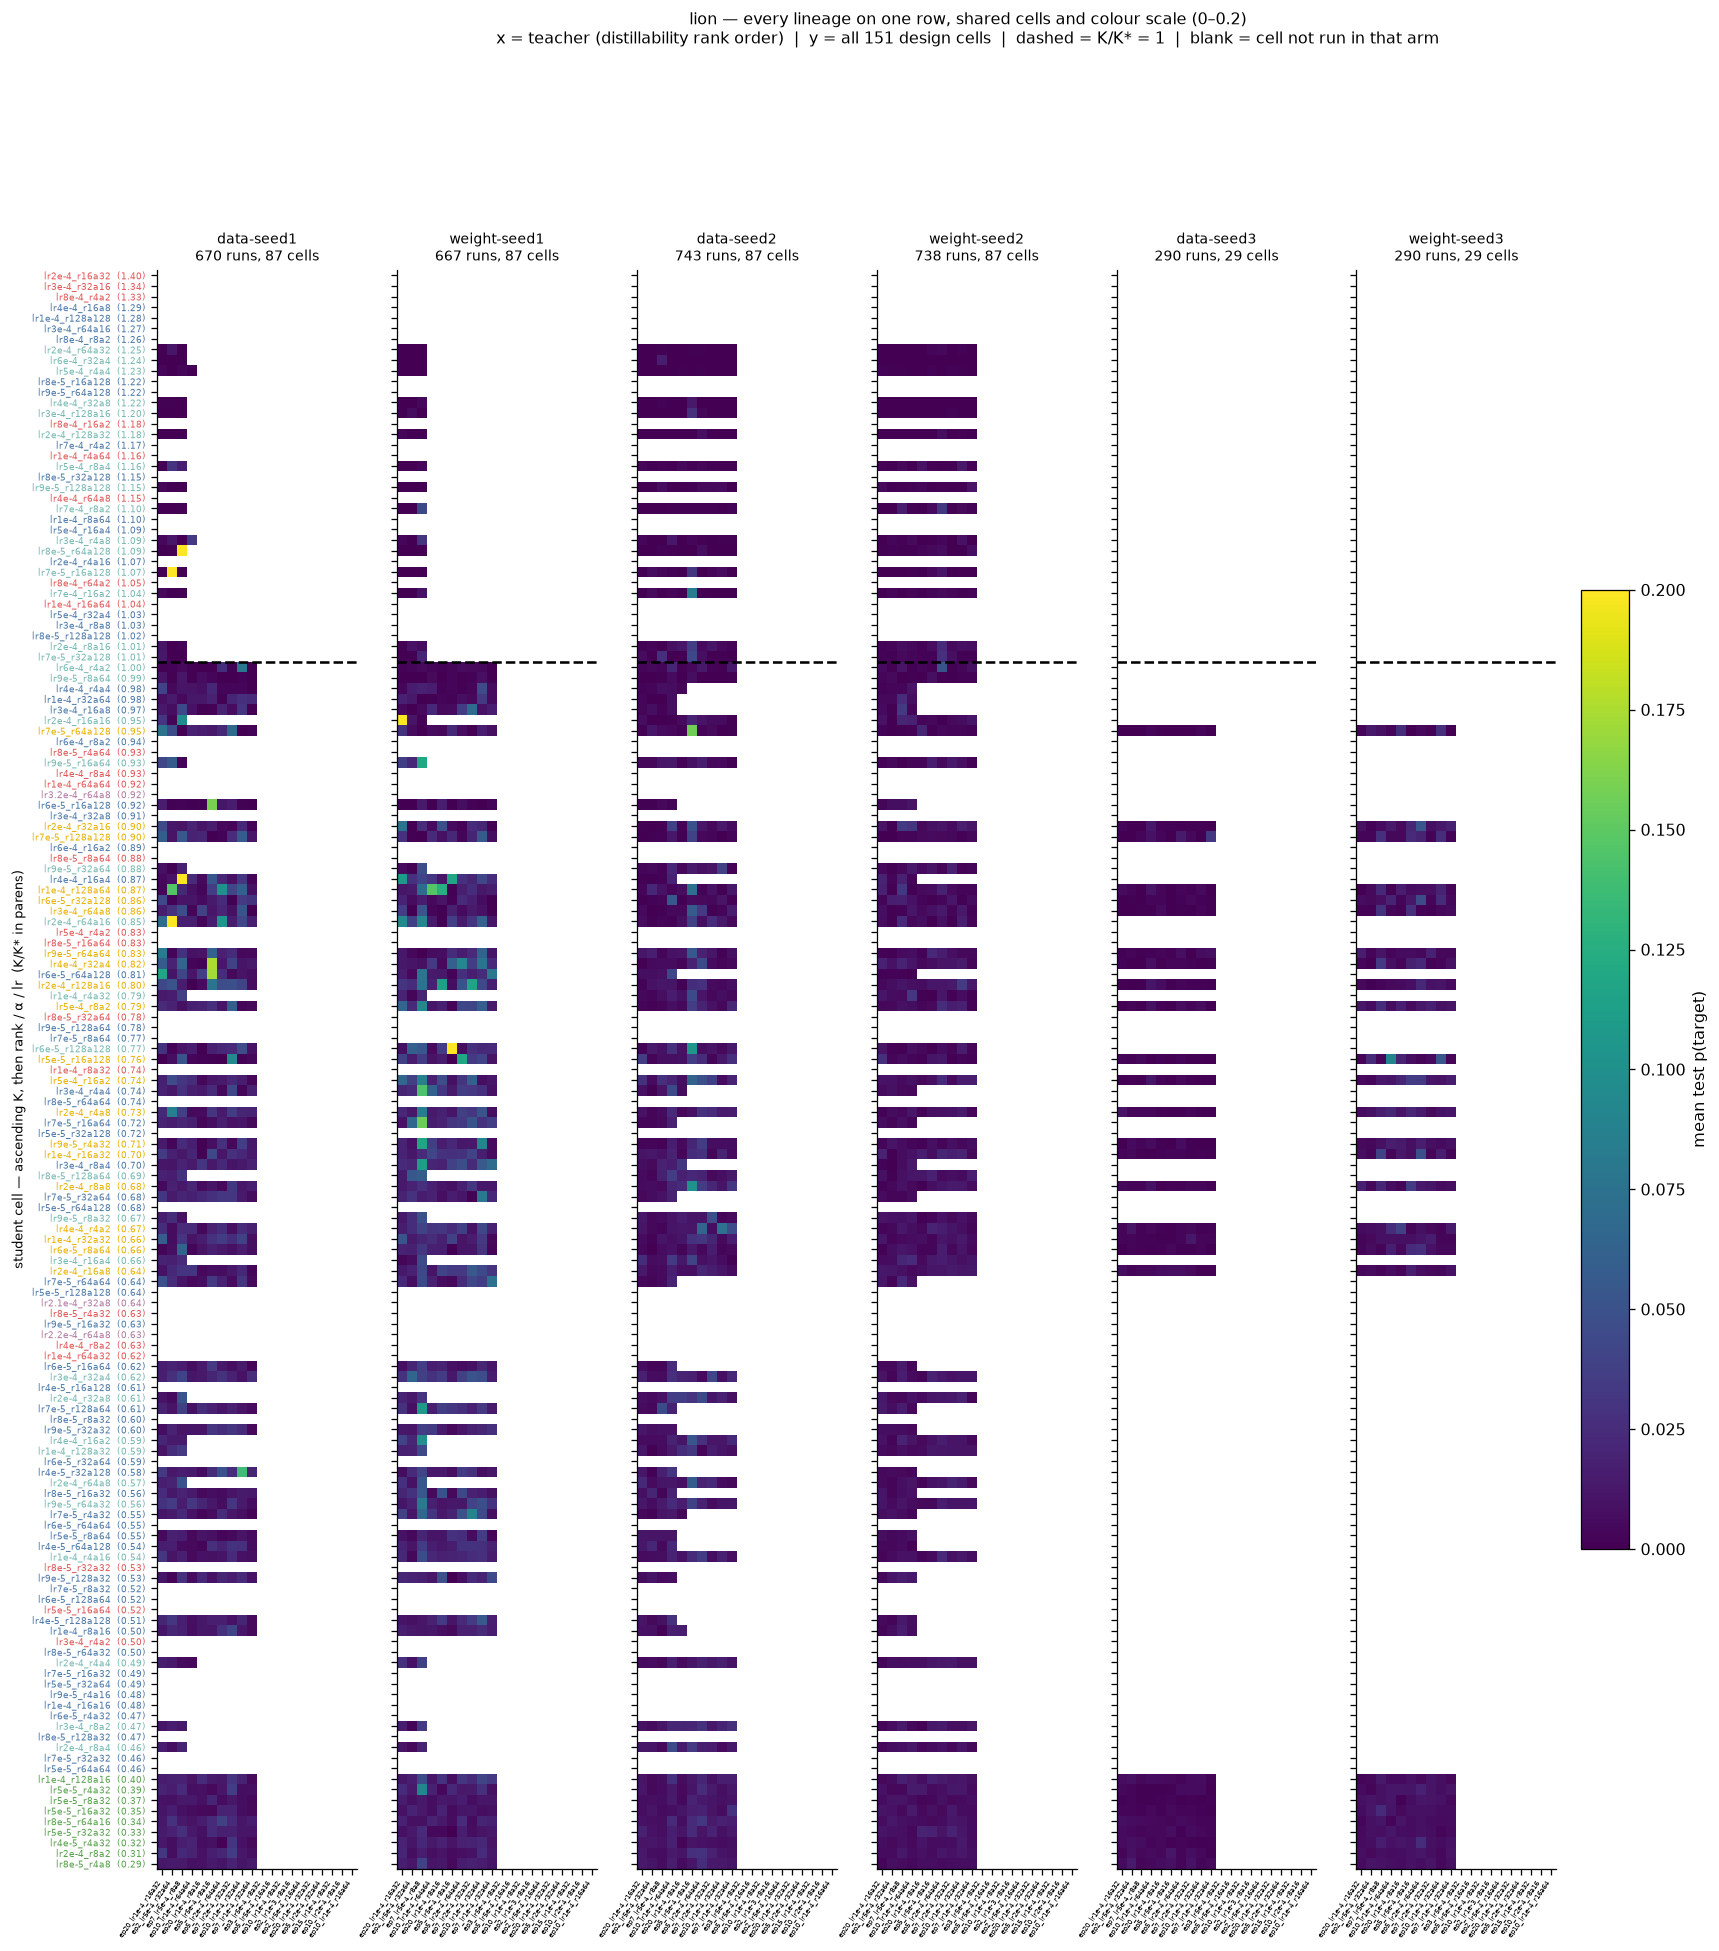

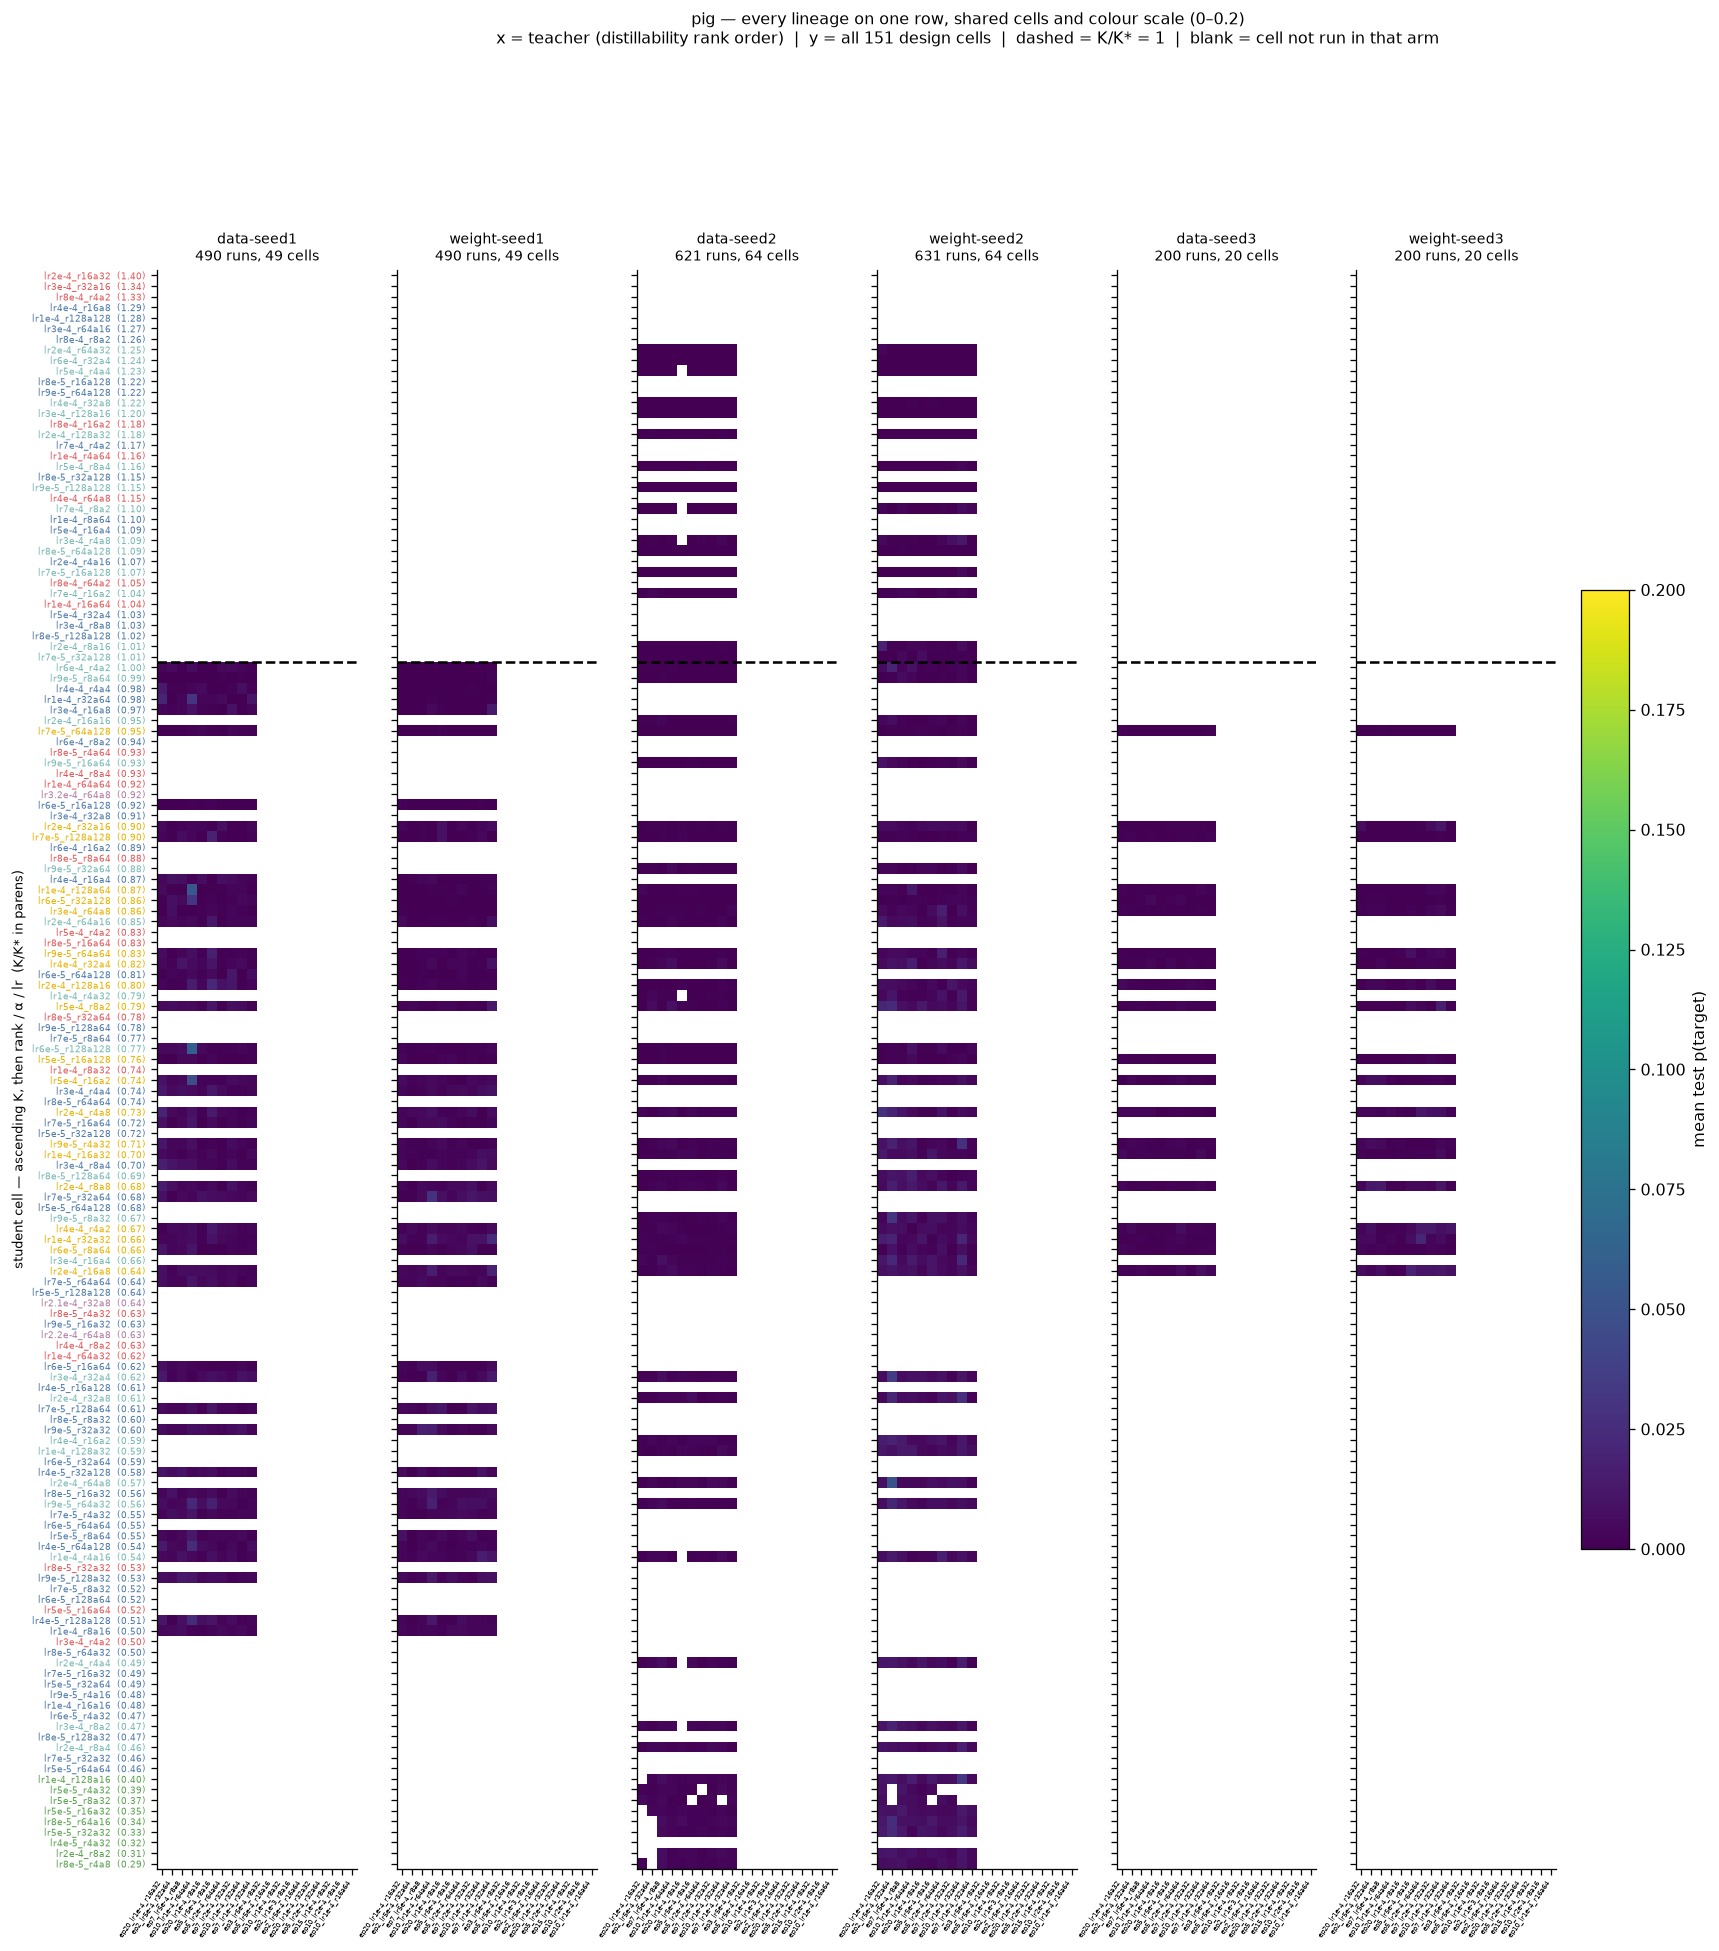

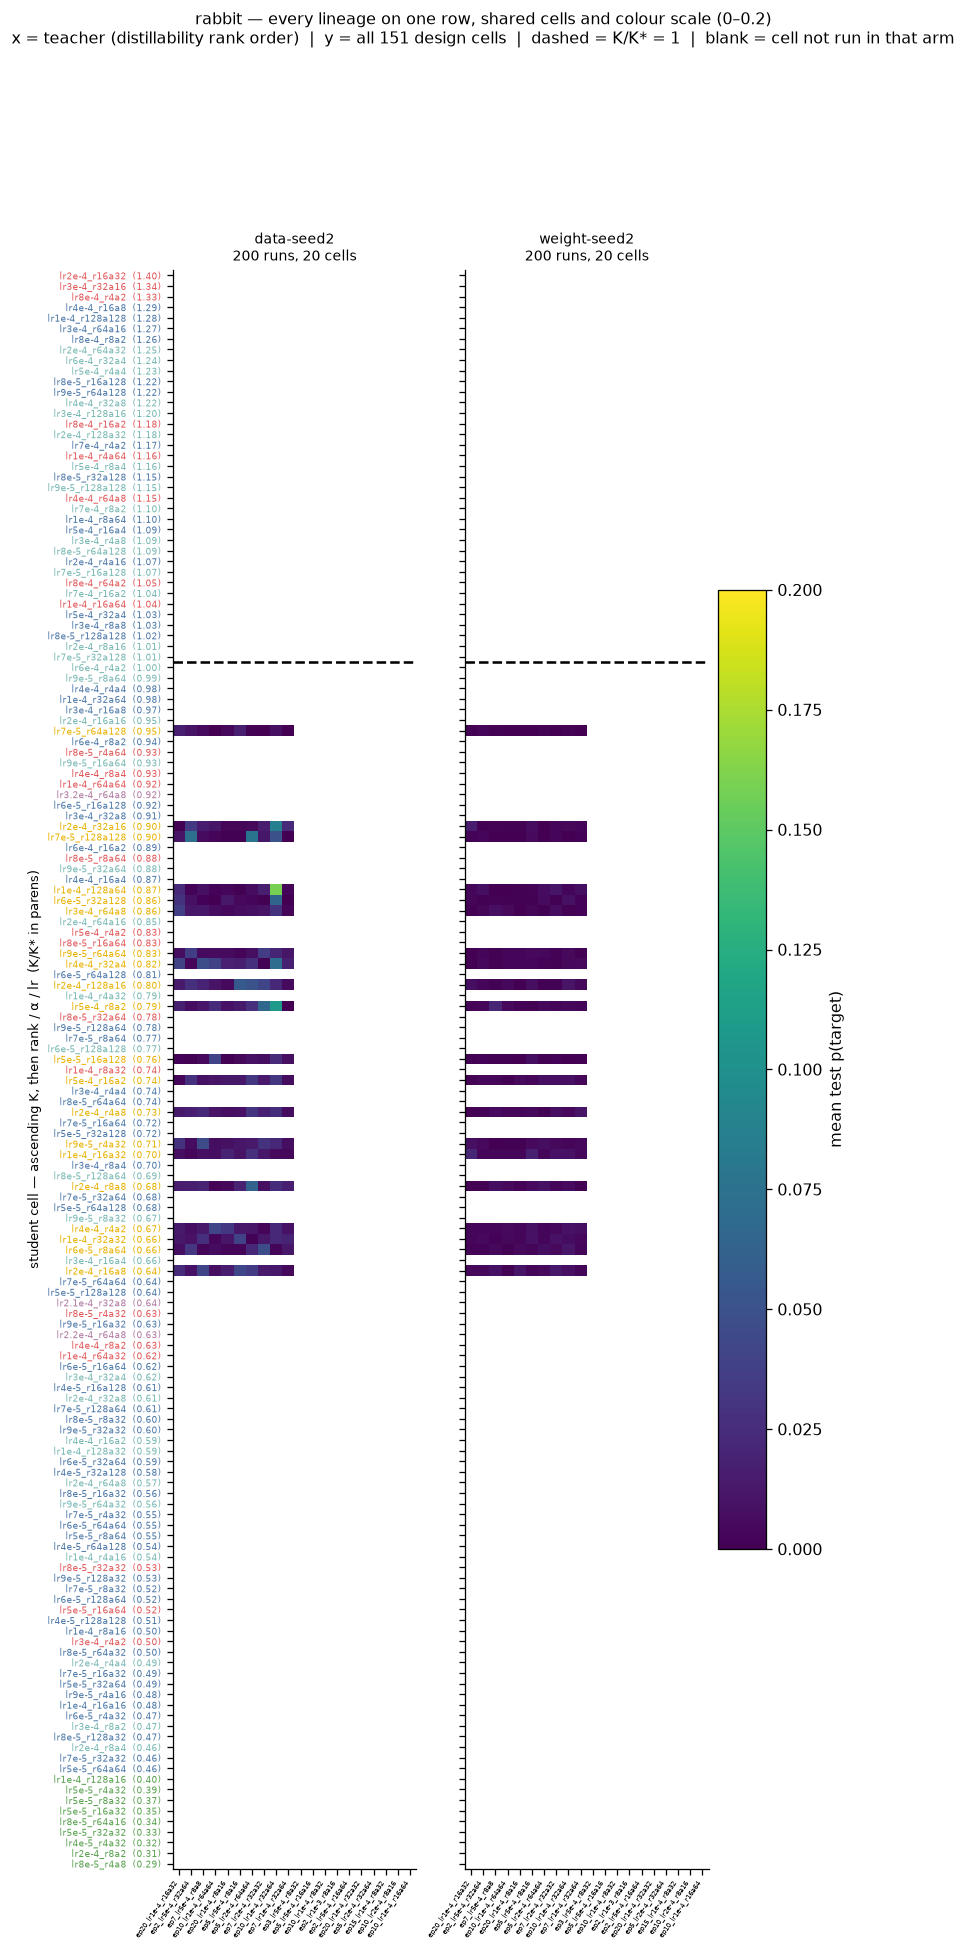

In [14]:
MIN_RUNS_ROW = 100      # a panel below this is a scatter, and would read as a dark (dead) arm

for animal in sorted({lin.split(" | ")[0] for lin in LINEAGES}, key=lambda a: ANIMAL_RANK.get(a, 99)):
    lins = [lin for lin in LINEAGES if lin.startswith(f"{animal} | ")
            and len(runs[runs.lineage.eq(lin)]) >= MIN_RUNS_ROW]
    dropped = [lin for lin in LINEAGES if lin.startswith(f"{animal} | ") and lin not in lins]
    if len(lins) < 2:
        print(f"[{animal}] only {len(lins)} lineage(s) above {MIN_RUNS_ROW} runs — no row drawn")
        continue
    fig, axs = plt.subplots(1, len(lins), figsize=(2.9 * len(lins) + 1.4,
                                                  0.105 * len(CELL_ROWS) + 2.2), sharey=True)
    for i, (ax, lin) in enumerate(zip(np.atleast_1d(axs), lins)):
        sub = runs[runs.lineage.eq(lin)]
        im = teacher_cell_matrix(ax, sub, annotate=False, box=False, label_rows=(i == 0),
                                 tick_fontsize=5.5)
        ax.set_title(f"{lin.split(' -> ')[1]}\n{len(sub)} runs, "
                     f"{sub.student_tag.nunique()} cells", fontsize=8.5)
        ax.tick_params(axis="x", labelsize=4.5)
    np.atleast_1d(axs)[0].set_ylabel(
        "student cell — ascending K, then rank / α / lr  (K/K* in parens)", fontsize=8)
    fig.suptitle(
        f"{animal} — every lineage on one row, shared cells and colour scale (0–{P_VMAX})\n"
        "x = teacher (distillability rank order)  |  y = all "
        f"{len(CELL_ROWS)} design cells  |  dashed = K/K* = 1  |  blank = cell not run in that arm",
        y=1.005, fontsize=10)
    fig.colorbar(im, ax=np.atleast_1d(axs).tolist(), shrink=0.6, pad=0.015,
                 label="mean test p(target)")
    plt.show()
    if dropped:
        print(f"[{animal}] omitted (< {MIN_RUNS_ROW} runs): " + " | ".join(dropped))

## 9. All lineages on one axis — the marginal $K/K^\ast$ response

The grids answer "does the boundary sit at the same height whatever $(\alpha, r)$ got you there".
This collapses each grid to its y-marginal so the arms can be compared directly. Row unit of each
point: all runs of that lineage in that $K/K^\ast$ bin (teachers and cells averaged); the left
panel plots mean test $p$, the right panel the collapsed fraction. Points with fewer than 5 runs
are drawn hollow — they are single cells, not a bin average.

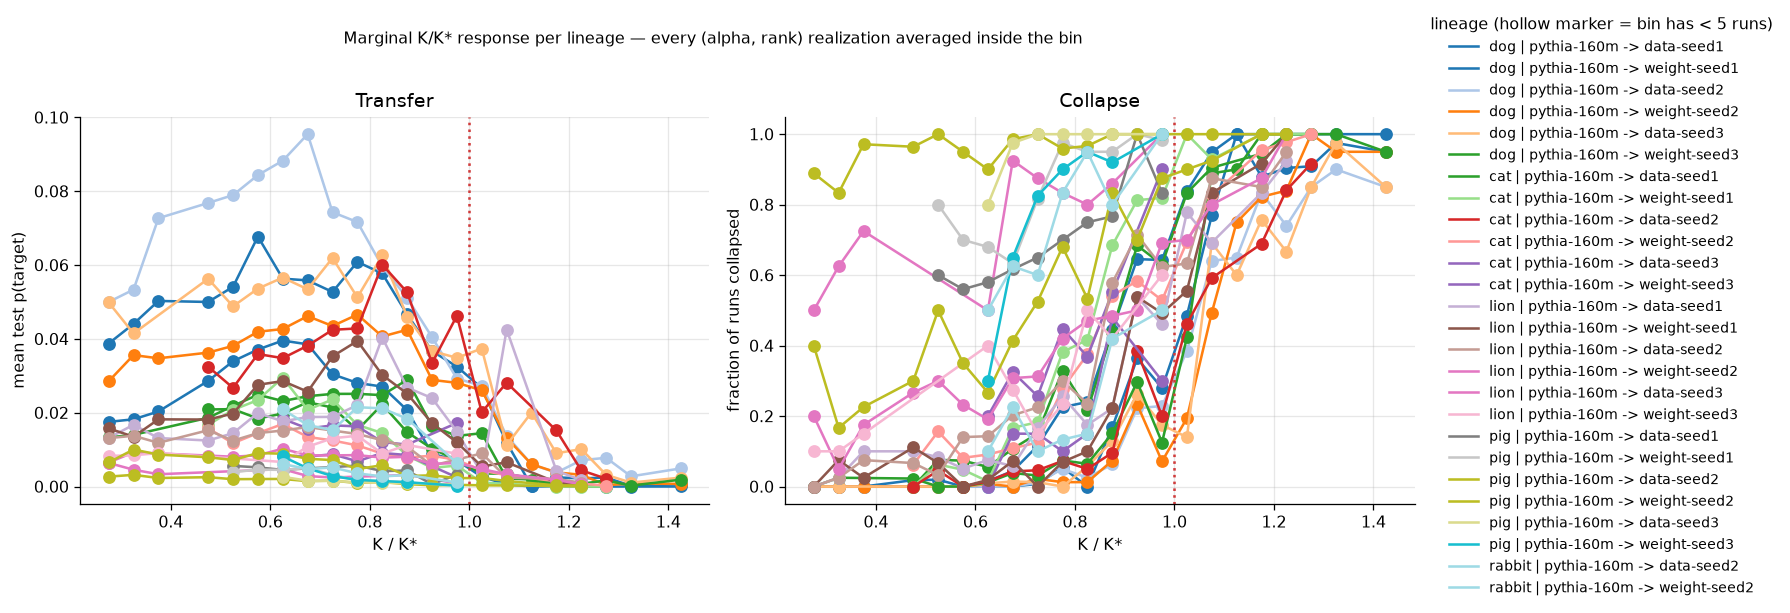

In [15]:
prof = (runs.groupby(["lineage", "K_bin"], observed=True)
        .agg(p=("test", "mean"), dead=("dead", "mean"), n=("test", "size")).reset_index())
prof["x"] = prof.K_bin.map(mid)
keep = [lin for lin in LINEAGES if len(runs[runs.lineage.eq(lin)]) >= 100]
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(len(keep), 2)))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
handles = []
for (lin, c) in zip(keep, colors):
    g = prof[prof.lineage.eq(lin)].sort_values("x")
    for ax, col in zip(axs, ["p", "dead"]):
        big, small = g[g.n >= 5], g[g.n < 5]
        (ln,) = ax.plot(g.x, g[col], "-", color=c, lw=1.6, label=lin)
        ax.plot(big.x, big[col], "o", color=c, ms=7)
        ax.plot(small.x, small[col], "o", color=c, ms=7, mfc="white")
    handles.append(ln)
for ax, (ttl, ylab) in zip(axs, [("Transfer", "mean test p(target)"),
                                 ("Collapse", "fraction of runs collapsed")]):
    ax.axvline(1.0, color="#d03b3b", ls=":", lw=1.6)
    ax.set(xlabel="K / K*", ylabel=ylab, title=ttl,
           xticks=[0.4, 0.6, 0.8, 1.0, 1.2, 1.4])
fig.legend(handles, [h.get_label() for h in handles], loc="center left",
           bbox_to_anchor=(0.99, 0.5), frameon=False, fontsize=9,
           title="lineage (hollow marker = bin has < 5 runs)")
fig.suptitle("Marginal K/K* response per lineage — every (alpha, rank) realization averaged "
             "inside the bin", y=1.02, fontsize=10)
fig.tight_layout(); plt.show()

### Where each lineage's own boundary sits

Row unit: one lineage. `K_rel_last_live` is the highest $K/K^\ast$ bin whose collapse fraction is
still below 0.5, `K_rel_first_dead` the lowest bin at/above 0.5, and `boundary_K_rel` their
geometric midpoint — that arm's empirical boundary against a design value of exactly 1. The
anchor was fit on `dog -> data-seed1`, so that row is the sanity check and the others are the
transfer claim. `monotone=False` flags an arm whose collapse fraction crosses 0.5 more than once,
where the midpoint is indicative only.

In [16]:
rows = []
for lin in keep:
    g = prof[prof.lineage.eq(lin)].sort_values("x")
    live, dead_ = g[g.dead < 0.5], g[g.dead >= 0.5]
    lo = live.x.max() if len(live) else np.nan
    hi = dead_.x.min() if len(dead_) else np.nan
    mid_b = float(np.sqrt(lo * hi)) if np.isfinite(lo) and np.isfinite(hi) else np.nan
    rows.append({"lineage": lin, "bins": len(g), "runs": int(g.n.sum()),
                 "K_rel_last_live": lo, "K_rel_first_dead": hi,
                 "boundary_K_rel": mid_b, "monotone": bool(lo < hi)})
display(pd.DataFrame(rows).set_index("lineage").round(3))
print("design boundary = 1.00 by construction; a row with monotone=False has a collapsed bin "
      "below a live one, so its midpoint is only indicative.")

,bins,runs,K_rel_last_live,K_rel_first_dead,boundary_K_rel,monotone
lineage,,,,,,
dog | pythia-160m -> data-seed1,22,1719,1.025,1.075,1.050,True
dog | pythia-160m -> weight-seed1,22,1699,0.875,0.925,0.900,True
dog | pythia-160m -> data-seed2,22,1535,1.025,1.075,1.050,True
dog | pythia-160m -> weight-seed2,22,1543,1.075,1.125,1.100,True
dog | pythia-160m -> data-seed3,21,1185,1.025,1.075,1.050,True
dog | pythia-160m -> weight-seed3,21,842,1.025,1.075,1.050,True
cat | pythia-160m -> data-seed1,16,894,0.875,0.925,0.900,True
cat | pythia-160m -> weight-seed1,16,829,0.825,0.875,0.850,True
cat | pythia-160m -> data-seed2,16,887,1.025,1.075,1.050,True


design boundary = 1.00 by construction; a row with monotone=False has a collapsed bin below a live one, so its midpoint is only indicative.


---

**Reconstruction note (2026-08-05).** This notebook replaces the merged-campaign view lost in the
node-1 rebuild. It is rebuilt from the surviving campaign records — the frozen `krungs-25` waves
in `top20_krungs_ds1.ipynb`, the `top5-bandext-ds2ws2` job list, `run_logs/focus20_cells.json`,
the teacher manifests, and the student output tree — not from the original notebook, so section
numbering and wording differ from the lost one even where the figures agree.

**Update (2026-08-18).** Rebuilt to fold in the latest band-extension data: the `band-48`
rank/α-balanced thin (top-10 teachers, every arm) and the 9-cell `lowk-9` low-$K$ extension
settled 2026-08-17, both read from their design manifests. Added the §3 cross-animal /
cross-model summary on the prior-normalized readout; dropped the former per-lineage
collapse-fraction grids (the marginal collapse view survives in §9).

**Trim (2026-08-18, same day).** Dropped the per-lineage score-distribution panels (§5b keeps
the mixture table), the top-5 balanced-pool grids, and the one-matrix-per-lineage section; §7's
boxes now colour the core65 design by part (red focus-20 / blue band-48 / orange lowk-9).